In [1]:
%pip install --user catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 106.0 MB/s  0:00:00m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 85.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/3 [plotly]  WARNING: The script plotly_get_chrome is installed in '/home/zilinm2/.local/bin' which is not on PATH.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [catboost]2/3 [catboost]
Note: you may need to restart the kernel to use updated packages.


In [2]:



# ============================================================
# Cell 1: CatBoost — Data Preprocessing & Technology Dataset Export
# Master: 45 Stocks | 31 Features | 2 Targets
# Technology: 9 Stocks | 31 Features | TARGET_10
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

# 1. Load source data
source_path = Path("data_engineered.csv")
master_path = Path("data_preML.csv")
tech_path = Path("data_preML_Tech.CSV")

data_raw = pd.read_csv(source_path, parse_dates=["DlyCalDt"])
assert data_raw.shape == (122265, 53)

# 2. Remove market and peer features
market_features = [
    "SP_RET_5", "SP_VOL_20", "REL_RET_20",
    "BETA_39", "IDIO_VOL_39"
]
peer_features = [
    "PEER_RET_5", "PEER_REL_RET_20",
    "PEER_VOL_20", "XS_RANK_20"
]
removed_features = market_features + peer_features

assert len(set(removed_features)) == 9
assert set(removed_features).issubset(data_raw.columns)

raw_cols = [
    "PERMNO", "Ticker", "DlyCalDt",
    "DlyOpen", "DlyHigh", "DlyLow", "DlyClose",
    "DlyVol", "DlyCap", "sprtrn"
]
all_target_cols = ["TARGET_5", "TARGET_10"]
metadata_cols = raw_cols + all_target_cols + ["Split"]

# 3. Build and validate 45-stock master dataset
data_all = (
    data_raw.drop(columns=removed_features)
    .sort_values(["PERMNO", "DlyCalDt"])
    .reset_index(drop=True)
)

all_feature_cols = [
    c for c in data_all.columns if c not in metadata_cols
]

assert data_all.shape == (122265, 44)
assert data_all["Ticker"].nunique() == 45
assert data_all["PERMNO"].nunique() == 45
assert len(all_feature_cols) == 31
assert set(all_target_cols).issubset(data_all.columns)
assert not data_all.duplicated(["PERMNO", "DlyCalDt"]).any()
assert set(data_all["Split"]) == {"Train", "Validation", "Test"}
assert np.isfinite(
    data_all[all_feature_cols + all_target_cols].to_numpy(dtype=float)
).all()

# Export and reload master dataset
data_all.to_csv(master_path, index=False, float_format="%.17g")
data_all = pd.read_csv(
    master_path, parse_dates=["DlyCalDt"], float_precision="round_trip"
)

assert data_all.shape == (122265, 44)
assert np.isfinite(
    data_all[all_feature_cols + all_target_cols].to_numpy(dtype=float)
).all()

# 4. Extract technology stocks
tech_tickers = [
    "AAPL", "MSFT", "NVDA", "AMD", "ADBE",
    "AVGO", "ORCL", "CRM", "AMAT"
]
assert len(set(tech_tickers)) == 9

data = (
    data_all.loc[data_all["Ticker"].isin(tech_tickers)]
    .drop(columns=["TARGET_5"])
    .sort_values(["PERMNO", "DlyCalDt"])
    .reset_index(drop=True)
)

target_col = "TARGET_10"
target_cols = [target_col]
feature_cols = [
    c for c in data.columns
    if c not in raw_cols + target_cols + ["Split"]
]

# 5. Validate technology dataset
assert data.shape == (24453, 43)
assert data["Ticker"].nunique() == 9
assert data["PERMNO"].nunique() == 9
assert set(data["Ticker"]) == set(tech_tickers)
assert len(feature_cols) == 31
assert feature_cols == all_feature_cols
assert data.groupby("Ticker").size().eq(2717).all()
assert data.groupby("Ticker")["PERMNO"].nunique().eq(1).all()
assert not data.duplicated(["PERMNO", "DlyCalDt"]).any()
assert data["DlyCalDt"].notna().all()
assert np.isfinite(
    data[feature_cols + target_cols].to_numpy(dtype=float)
).all()

# Export and reload technology dataset
data.to_csv(tech_path, index=False, float_format="%.17g")
data = pd.read_csv(
    tech_path, parse_dates=["DlyCalDt"], float_precision="round_trip"
)

assert data.shape == (24453, 43)
assert np.isfinite(
    data[feature_cols + target_cols].to_numpy(dtype=float)
).all()

# 6. Define chronological splits
train_pool = data.loc[data["Split"] == "Train"].copy()
val_pool = data.loc[data["Split"] == "Validation"].copy()
test_pool = data.loc[data["Split"] == "Test"].copy()

assert (len(train_pool), len(val_pool), len(test_pool)) == (
    15516, 4509, 4428
)

for subset, start_year, end_year in [
    (train_pool, 2015, 2021),
    (val_pool, 2022, 2023),
    (test_pool, 2024, 2025)
]:
    assert subset["DlyCalDt"].dt.year.between(
        start_year, end_year
    ).all()

assert train_pool["DlyCalDt"].max() < val_pool["DlyCalDt"].min()
assert val_pool["DlyCalDt"].max() < test_pool["DlyCalDt"].min()

# 7. Dataset summaries
def summarize_splits(df):
    return (
        df.groupby("Split")
        .agg(
            Rows=("DlyCalDt", "size"),
            Stocks=("Ticker", "nunique"),
            Start=("DlyCalDt", "min"),
            End=("DlyCalDt", "max")
        )
        .reindex(["Train", "Validation", "Test"])
    )

full_summary = summarize_splits(data_all)
split_summary = summarize_splits(data)

stock_summary = (
    data.groupby("Ticker")
    .agg(
        PERMNO=("PERMNO", "first"),
        Rows=("DlyCalDt", "size"),
        Start=("DlyCalDt", "min"),
        End=("DlyCalDt", "max")
    )
    .reindex(tech_tickers)
)

# 8. Output
print("=" * 65)
print("CELL 1: CATBOOST — DATA PREPROCESSING & EXPORT")
print("=" * 65)

print("\n1. Master Dataset")
print(f"Path: {master_path.resolve()}")
print(f"Size: {master_path.stat().st_size / 1024**2:.2f} MB")
print(f"Shape: {data_all.shape} | Features: {len(all_feature_cols)}")
print(f"Targets: {all_target_cols}")
display(full_summary)

print("\n2. Technology Dataset")
print(f"Path: {tech_path.resolve()}")
print(f"Size: {tech_path.stat().st_size / 1024**2:.2f} MB")
print(f"Shape: {data.shape} | Features: {len(feature_cols)}")
print(f"Target: {target_col}")
display(stock_summary)

print("\n3. Technology Train / Validation / Test")
display(split_summary)

print("\n4. Retained Features")
display(pd.DataFrame({
    "No.": range(1, len(feature_cols) + 1),
    "Feature": feature_cols
}))

print("\n5. Data Integrity")
print("Stocks, features, targets and splits: PASSED")
print("Duplicates and non-finite values: NONE")
print("Chronological separation: PASSED")
print("CSV export and reload: PASSED")
print("No normalization, feature selection or model fitting performed")

print("\nCELL 1 STATUS: PASSED")



CELL 1: CATBOOST — DATA PREPROCESSING & EXPORT

1. Master Dataset
Path: /home/zilinm2/Fin 556/data_preML.csv
Size: 94.61 MB
Shape: (122265, 44) | Features: 31
Targets: ['TARGET_5', 'TARGET_10']


,Rows,Stocks,Start,End
Split,,,,
Train,77580,45,2015-03-02,2021-12-31
Validation,22545,45,2022-01-03,2023-12-29
Test,22140,45,2024-01-02,2025-12-16



2. Technology Dataset
Path: /home/zilinm2/Fin 556/data_preML_Tech.CSV
Size: 18.33 MB
Shape: (24453, 43) | Features: 31
Target: TARGET_10


,PERMNO,Rows,Start,End
Ticker,,,,
AAPL,14593,2717,2015-03-02,2025-12-16
MSFT,10107,2717,2015-03-02,2025-12-16
NVDA,86580,2717,2015-03-02,2025-12-16
AMD,61241,2717,2015-03-02,2025-12-16
ADBE,75510,2717,2015-03-02,2025-12-16
AVGO,93002,2717,2015-03-02,2025-12-16
ORCL,10104,2717,2015-03-02,2025-12-16
CRM,90215,2717,2015-03-02,2025-12-16
AMAT,14702,2717,2015-03-02,2025-12-16



3. Technology Train / Validation / Test


,Rows,Stocks,Start,End
Split,,,,
Train,15516,9,2015-03-02,2021-12-31
Validation,4509,9,2022-01-03,2023-12-29
Test,4428,9,2024-01-02,2025-12-16



4. Retained Features


,No.,Feature
0,1,RET_1
1,2,RET_3
2,3,RET_5
3,4,RET_10
4,5,RET_20
5,6,RET_39
6,7,UP_RATIO_20
7,8,MA_DEV_10
8,9,MA_DEV_20
9,10,BREAKOUT_POS_20



5. Data Integrity
Stocks, features, targets and splits: PASSED
Duplicates and non-finite values: NONE
Chronological separation: PASSED
CSV export and reload: PASSED
No normalization, feature selection or model fitting performed

CELL 1 STATUS: PASSED


In [4]:

# ============================================================
# Cell 2: CatBoost — Chronological Walk-Forward & Target Purging
# Technology | 9 Stocks | 31 Features | TARGET_10
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display

# 1. Configuration
HORIZON = 10
DEV_WINDOWS = [3, 4, 5]
DEV_YEARS = [2020, 2021]
TRAIN_OOS_YEARS = [2018, 2019, 2020, 2021]
TRAIN_OOS_START_YEAR = 2015

assert target_col == "TARGET_10"
assert len(feature_cols) == 31
assert data["Ticker"].nunique() == 9
assert len(train_pool) == 15516

# 2. Select chronological data
def get_period(start_year, end_year, split):
    period = data.loc[
        data["Split"].eq(split)
        & data["DlyCalDt"].dt.year.between(start_year, end_year)
    ].copy()

    assert not period.empty
    assert period["Ticker"].nunique() == 9
    assert period.groupby("DlyCalDt")["PERMNO"].nunique().eq(9).all()

    return period

# 3. Identify labels realized within each period
def get_realized_indices(period, horizon=HORIZON):
    target_end = (
        period.groupby("PERMNO", sort=False)["DlyCalDt"]
        .shift(-horizon)
    )

    realized_idx = period.index[target_end.notna()].copy()
    excluded_idx = period.index[target_end.isna()].copy()

    assert len(excluded_idx) == period["PERMNO"].nunique() * horizon
    assert (
        target_end.loc[realized_idx]
        > period.loc[realized_idx, "DlyCalDt"]
    ).all()
    assert (
        target_end.loc[realized_idx] <= period["DlyCalDt"].max()
    ).all()

    return realized_idx, excluded_idx

# 4. Construct walk-forward folds
def build_fold(
    train_start_year, train_end_year,
    oos_start_year, oos_end_year, oos_split
):
    train_period = get_period(
        train_start_year, train_end_year, "Train"
    )
    oos_period = get_period(
        oos_start_year, oos_end_year, oos_split
    )

    assert train_period["DlyCalDt"].max() < oos_period["DlyCalDt"].min()

    # Purge training labels extending beyond the training cutoff
    train_fit_idx, train_excluded_idx = get_realized_indices(
        train_period, HORIZON
    )

    # Retain all OOS dates for signals; evaluate only realized labels
    oos_signal_idx = oos_period.index.copy()
    oos_eval_idx, oos_excluded_idx = get_realized_indices(
        oos_period, HORIZON
    )

    # Fold integrity
    assert train_fit_idx.intersection(oos_signal_idx).empty
    assert len(train_excluded_idx) == 9 * HORIZON
    assert len(oos_excluded_idx) == 9 * HORIZON
    assert len(train_fit_idx) + len(train_excluded_idx) == len(train_period)
    assert len(oos_eval_idx) + len(oos_excluded_idx) == len(oos_period)

    assert data.loc[train_fit_idx, "Split"].eq("Train").all()
    assert data.loc[oos_signal_idx, "Split"].eq(oos_split).all()
    assert np.isfinite(
        data.loc[
            train_fit_idx, feature_cols + [target_col]
        ].to_numpy(dtype=float)
    ).all()

    return {
        "train_fit_idx": train_fit_idx,
        "train_full_idx": train_period.index.copy(),
        "train_excluded_idx": train_excluded_idx,
        "oos_signal_idx": oos_signal_idx,
        "oos_eval_idx": oos_eval_idx,
        "oos_excluded_idx": oos_excluded_idx,
        "train_start": train_period["DlyCalDt"].min(),
        "train_cutoff": train_period["DlyCalDt"].max(),
        "train_fit_end": data.loc[train_fit_idx, "DlyCalDt"].max(),
        "oos_start": oos_period["DlyCalDt"].min(),
        "oos_end": oos_period["DlyCalDt"].max(),
        "oos_split": oos_split
    }

# 5. Development walk-forward: 6 folds
development_folds = {}
development_rows = []

for val_year in DEV_YEARS:
    for window in DEV_WINDOWS:
        fold = build_fold(
            val_year - window, val_year - 1,
            val_year, val_year, "Train"
        )
        development_folds[(window, val_year)] = fold

        development_rows.append({
            "Window": window,
            "OOS_Year": val_year,
            "Train_Start": fold["train_start"],
            "Train_Fit_End": fold["train_fit_end"],
            "Train_Cutoff": fold["train_cutoff"],
            "Train_Fit_Rows": len(fold["train_fit_idx"]),
            "OOS_Signal_Rows": len(fold["oos_signal_idx"]),
            "OOS_Eval_Rows": len(fold["oos_eval_idx"]),
            "Train_Purged": len(fold["train_excluded_idx"]),
            "OOS_Eval_Excluded": len(fold["oos_excluded_idx"])
        })

development_summary_df = (
    pd.DataFrame(development_rows)
    .sort_values(["OOS_Year", "Window"])
    .reset_index(drop=True)
)

# 6. Historical Train OOS: 2018–2021 (Expanding Window)
train_oos_folds = {}
train_oos_rows = []

for oos_year in TRAIN_OOS_YEARS:
    fold = build_fold(
        TRAIN_OOS_START_YEAR, oos_year - 1,
        oos_year, oos_year, "Train"
    )
    train_oos_folds[oos_year] = fold

    train_oos_rows.append({
        "OOS_Year": oos_year,
        "Train_Start": fold["train_start"],
        "Train_Fit_End": fold["train_fit_end"],
        "Train_Cutoff": fold["train_cutoff"],
        "Train_Fit_Rows": len(fold["train_fit_idx"]),
        "OOS_Start": fold["oos_start"],
        "OOS_End": fold["oos_end"],
        "OOS_Signal_Rows": len(fold["oos_signal_idx"]),
        "OOS_Eval_Rows": len(fold["oos_eval_idx"]),
        "Train_Purged": len(fold["train_excluded_idx"])
    })

train_oos_summary_df = (
    pd.DataFrame(train_oos_rows)
    .sort_values("OOS_Year")
    .reset_index(drop=True)
)

# Verify that annual OOS periods are disjoint
all_oos_indices = np.concatenate([
    fold["oos_signal_idx"].to_numpy()
    for fold in train_oos_folds.values()
])
assert len(all_oos_indices) == len(np.unique(all_oos_indices))

# 7. Independent validation: 2022–2023
validation_fold = build_fold(
    2015, 2021, 2022, 2023, "Validation"
)

assert len(validation_fold["train_full_idx"]) == 15516
assert len(validation_fold["train_fit_idx"]) == 15426
assert len(validation_fold["oos_signal_idx"]) == 4509
assert len(validation_fold["oos_eval_idx"]) == 4419

# 8. Final integrity checks
assert len(development_folds) == 6
assert len(train_oos_folds) == 4
assert all(
    fold["oos_split"] == "Train"
    for fold in list(development_folds.values())
    + list(train_oos_folds.values())
)
assert validation_fold["oos_split"] == "Validation"

all_folds = (
    list(development_folds.values())
    + list(train_oos_folds.values())
    + [validation_fold]
)

# No Test observations appear in any training or OOS period
assert all(
    not data.loc[
        fold["train_full_idx"].union(fold["oos_signal_idx"]),
        "Split"
    ].eq("Test").any()
    for fold in all_folds
)

# 9. Output
print("=" * 65)
print("CELL 2: CATBOOST — CHRONOLOGICAL WALK-FORWARD & TARGET PURGING")
print("=" * 65)

print(f"\nStocks: 9 | Features: {len(feature_cols)}")
print(f"Target: {target_col} | Horizon: {HORIZON} trading days")

print("\n1. Development Walk-Forward")
display(development_summary_df)

print("\n2. Historical Train OOS")
display(train_oos_summary_df)

print("\n3. Independent Validation")
display(pd.DataFrame([{
    "Train_Start": validation_fold["train_start"],
    "Train_Cutoff": validation_fold["train_cutoff"],
    "Train_Fit_Rows": len(validation_fold["train_fit_idx"]),
    "Val_Start": validation_fold["oos_start"],
    "Val_End": validation_fold["oos_end"],
    "Val_Signal_Rows": len(validation_fold["oos_signal_idx"]),
    "Val_Eval_Rows": len(validation_fold["oos_eval_idx"])
}]))

print("\n4. Fold Integrity")
print(f"Development folds: {len(development_folds)}")
print(f"Historical Train OOS folds: {len(train_oos_folds)}")
print("Independent Validation folds: 1")
print("Training label purging: PASSED")
print("Full OOS signal coverage: PASSED")
print("Chronological separation: PASSED")
print("Train / OOS overlap: NONE")
print("Test observations used: NONE")

print("\nCELL 2 STATUS: PASSED")


CELL 2: CATBOOST — CHRONOLOGICAL WALK-FORWARD & TARGET PURGING

Stocks: 9 | Features: 31
Target: TARGET_10 | Horizon: 10 trading days

1. Development Walk-Forward


,Window,OOS_Year,Train_Start,Train_Fit_End,Train_Cutoff,Train_Fit_Rows,OOS_Signal_Rows,OOS_Eval_Rows,Train_Purged,OOS_Eval_Excluded
0,3,2020,2017-01-03,2019-12-16,2019-12-31,6696,2277,2187,90,90
1,4,2020,2016-01-04,2019-12-16,2019-12-31,8964,2277,2187,90,90
2,5,2020,2015-03-02,2019-12-16,2019-12-31,10881,2277,2187,90,90
3,3,2021,2018-01-02,2020-12-16,2020-12-31,6714,2268,2178,90,90
4,4,2021,2017-01-03,2020-12-16,2020-12-31,8973,2268,2178,90,90
5,5,2021,2016-01-04,2020-12-16,2020-12-31,11241,2268,2178,90,90



2. Historical Train OOS


,OOS_Year,Train_Start,Train_Fit_End,Train_Cutoff,Train_Fit_Rows,OOS_Start,OOS_End,OOS_Signal_Rows,OOS_Eval_Rows,Train_Purged
0,2018,2015-03-02,2017-12-14,2017-12-29,6354,2018-01-02,2018-12-31,2259,2169,90
1,2019,2015-03-02,2018-12-14,2018-12-31,8613,2019-01-02,2019-12-31,2268,2178,90
2,2020,2015-03-02,2019-12-16,2019-12-31,10881,2020-01-02,2020-12-31,2277,2187,90
3,2021,2015-03-02,2020-12-16,2020-12-31,13158,2021-01-04,2021-12-31,2268,2178,90



3. Independent Validation


,Train_Start,Train_Cutoff,Train_Fit_Rows,Val_Start,Val_End,Val_Signal_Rows,Val_Eval_Rows
0,2015-03-02,2021-12-31,15426,2022-01-03,2023-12-29,4509,4419



4. Fold Integrity
Development folds: 6
Historical Train OOS folds: 4
Independent Validation folds: 1
Training label purging: PASSED
Full OOS signal coverage: PASSED
Chronological separation: PASSED
Train / OOS overlap: NONE
Test observations used: NONE

CELL 2 STATUS: PASSED


In [5]:


# ============================================================
# Cell 3: CatBoost — Fold-Specific Standardization
# Technology | 9 Stocks | 31 Features | TARGET_10
# ============================================================

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from IPython.display import display

# 1. Configuration
assert len(feature_cols) == 31
assert target_col == "TARGET_10"
assert len(development_folds) == 6
assert len(train_oos_folds) == 4
assert not {target_col, "TARGET_5", "Split"}.intersection(feature_cols)

# 2. Standardize each chronological fold
def standardize_fold(fold):
    train_idx = fold["train_fit_idx"]
    signal_idx = fold["oos_signal_idx"]
    eval_idx = fold["oos_eval_idx"]

    X_train_raw = data.loc[train_idx, feature_cols]
    X_oos_raw = data.loc[signal_idx, feature_cols]
    y_train = data.loc[train_idx, target_col].copy()

    # Verify chronological separation and index alignment
    assert (
        data.loc[train_idx, "DlyCalDt"].max()
        < data.loc[signal_idx, "DlyCalDt"].min()
    )
    assert data.loc[train_idx, "Split"].eq("Train").all()
    assert not data.loc[signal_idx, "Split"].eq("Test").any()
    assert train_idx.intersection(signal_idx).empty
    assert eval_idx.isin(signal_idx).all()
    assert X_train_raw.index.equals(y_train.index)

    # Fit on training data only; apply the same scaler to OOS
    scaler = StandardScaler()

    X_train_scaled = pd.DataFrame(
        scaler.fit_transform(X_train_raw),
        index=train_idx,
        columns=feature_cols
    )

    X_oos_signal_scaled = pd.DataFrame(
        scaler.transform(X_oos_raw),
        index=signal_idx,
        columns=feature_cols
    )

    X_oos_eval_scaled = X_oos_signal_scaled.loc[eval_idx].copy()

    # 3. Numerical validation
    train_mean_error = float(
        X_train_scaled.mean().abs().max()
    )

    expected_variances = np.where(scaler.var_ > 0, 1.0, 0.0)
    train_var_error = float(
        np.abs(
            X_train_scaled.var(ddof=0).to_numpy()
            - expected_variances
        ).max()
    )

    constant_features = [
        feature_cols[i]
        for i in range(len(feature_cols))
        if scaler.var_[i] == 0
    ]

    assert train_mean_error < 1e-8
    assert train_var_error < 1e-8

    assert np.allclose(
        scaler.mean_,
        X_train_raw.mean().to_numpy(),
        rtol=1e-10,
        atol=1e-10
    )

    for X in (X_train_scaled, X_oos_signal_scaled, X_oos_eval_scaled):
        assert X.shape[1] == 31
        assert np.isfinite(X.to_numpy()).all()

    assert np.isfinite(y_train.to_numpy()).all()
    assert len(X_train_scaled) == len(train_idx)
    assert len(X_oos_signal_scaled) == len(signal_idx)
    assert len(X_oos_eval_scaled) == len(eval_idx)

    return {
        "scaler": scaler,
        "X_train": X_train_scaled,
        "y_train": y_train,
        "X_oos_signal": X_oos_signal_scaled,
        "X_oos_eval": X_oos_eval_scaled,
        "train_fit_idx": train_idx.copy(),
        "oos_signal_idx": signal_idx.copy(),
        "oos_eval_idx": eval_idx.copy(),
        "train_mean_error": train_mean_error,
        "train_var_error": train_var_error,
        "constant_features": constant_features,
        "train_cutoff": fold["train_cutoff"],
        "oos_start": fold["oos_start"],
        "oos_end": fold["oos_end"]
    }

# 4. Standardization summary helper
def scaling_record(stage, window, oos_year, result):
    return {
        "Stage": stage,
        "Window": window,
        "OOS_Year": oos_year,
        "Train_Rows": len(result["X_train"]),
        "OOS_Signal_Rows": len(result["X_oos_signal"]),
        "OOS_Eval_Rows": len(result["X_oos_eval"]),
        "Features": len(feature_cols),
        "Constant_Features": len(result["constant_features"]),
        "Train_Mean_Error": result["train_mean_error"],
        "Train_Var_Error": result["train_var_error"],
        "Status": "PASSED"
    }

# 5. Development walk-forward: 6 folds
scaled_development_folds = {}
scaling_rows = []

for (window, year), fold in sorted(development_folds.items()):
    result = standardize_fold(fold)
    scaled_development_folds[(window, year)] = result
    scaling_rows.append(
        scaling_record("Development", window, year, result)
    )

# 6. Historical Train OOS: 4 folds
scaled_train_oos_folds = {}

for year, fold in sorted(train_oos_folds.items()):
    result = standardize_fold(fold)
    scaled_train_oos_folds[year] = result
    scaling_rows.append(
        scaling_record("Train_OOS", year - TRAIN_OOS_START_YEAR, year, result)
    )

# 7. Independent validation: 2022–2023
scaled_validation_fold = standardize_fold(validation_fold)
result = scaled_validation_fold

scaling_rows.append(
    scaling_record("Validation", 7, "2022-2023", result)
)

# 8. Final integrity checks
scaling_summary_df = pd.DataFrame(scaling_rows)

assert len(scaling_summary_df) == 11
assert scaling_summary_df["Features"].eq(31).all()
assert scaling_summary_df["Status"].eq("PASSED").all()

# 9. Output
print("=" * 65)
print("CELL 3: CATBOOST — FOLD-SPECIFIC STANDARDIZATION")
print("=" * 65)

print(f"\nStocks: 9 | Features: {len(feature_cols)}")
print(f"Target: {target_col} (unchanged) | Method: StandardScaler")

print("\n1. Standardization Summary")
display(scaling_summary_df)

print("\n2. Fold Counts")
print(f"Development: {len(scaled_development_folds)}")
print(f"Historical Train OOS: {len(scaled_train_oos_folds)}")
print("Independent Validation: 1")
print(f"Total: {len(scaling_summary_df)}")

print("\n3. Numerical Checks")
print(
    "Maximum training mean error:",
    f"{scaling_summary_df['Train_Mean_Error'].max():.3e}"
)
print(
    "Maximum training variance error:",
    f"{scaling_summary_df['Train_Var_Error'].max():.3e}"
)
print(
    "Maximum constant-feature count:",
    scaling_summary_df["Constant_Features"].max()
)

print("\n4. Data Integrity")
print("Training-only scaler fitting: PASSED")
print("OOS transformation and coverage: PASSED")
print("Training mean and variance checks: PASSED")
print("TARGET_10 unchanged")
print("Validation targets not used for fitting")
print("Test data not accessed")
print("Original CSV files unchanged")

print("\nCELL 3 STATUS: PASSED")


CELL 3: CATBOOST — FOLD-SPECIFIC STANDARDIZATION

Stocks: 9 | Features: 31
Target: TARGET_10 (unchanged) | Method: StandardScaler

1. Standardization Summary


,Stage,Window,OOS_Year,Train_Rows,OOS_Signal_Rows,OOS_Eval_Rows,Features,Constant_Features,Train_Mean_Error,Train_Var_Error,Status
0,Development,3,2020,6696,2277,2187,31,0,2.003442e-15,6.883383e-15,PASSED
1,Development,3,2021,6714,2268,2178,31,0,2.336727e-15,1.865175e-14,PASSED
2,Development,4,2020,8964,2277,2187,31,0,2.942363e-15,3.408385e-14,PASSED
3,Development,4,2021,8973,2268,2178,31,0,2.331258e-15,3.241851e-14,PASSED
4,Development,5,2020,10881,2277,2187,31,0,2.632946e-15,2.675637e-14,PASSED
5,Development,5,2021,11241,2268,2178,31,0,4.025208e-15,5.329071e-14,PASSED
6,Train_OOS,3,2018,6354,2259,2169,31,0,8.230397e-16,3.819167e-14,PASSED
7,Train_OOS,4,2019,8613,2268,2178,31,0,1.003158e-15,1.125766e-13,PASSED
8,Train_OOS,5,2020,10881,2277,2187,31,0,2.632946e-15,2.675637e-14,PASSED
9,Train_OOS,6,2021,13158,2268,2178,31,0,3.939900e-15,4.307665e-14,PASSED



2. Fold Counts
Development: 6
Historical Train OOS: 4
Independent Validation: 1
Total: 11

3. Numerical Checks
Maximum training mean error: 4.025e-15
Maximum training variance error: 1.126e-13
Maximum constant-feature count: 0

4. Data Integrity
Training-only scaler fitting: PASSED
OOS transformation and coverage: PASSED
Training mean and variance checks: PASSED
TARGET_10 unchanged
Validation targets not used for fitting
Test data not accessed
Original CSV files unchanged

CELL 3 STATUS: PASSED


In [6]:



# ============================================================
# Cell 4: CatBoost Training & Walk-Forward Evaluation
# Technology | 9 Stocks | 31 Features | TARGET_10
# ============================================================

import time
import numpy as np
import pandas as pd
from IPython.display import display
from catboost import CatBoostRegressor

# 1. Fixed model configuration
# One fixed, conservative baseline across ALL folds; no OOS early stopping.
# Keep unchanged during the first model comparison (not Test-tuned).
CAT_PARAMS = {
    "loss_function": "RMSE",
    "iterations": 120,
    "learning_rate": 0.05,
    "depth": 3,
    "l2_leaf_reg": 10.0,
    "bootstrap_type": "Bernoulli",
    "subsample": 0.8,
    "rsm": 0.8,
    "random_strength": 1.0,
    "random_seed": 42,
    "thread_count": 4,
    "verbose": False,
    "allow_writing_files": False
}

assert len(scaled_development_folds) == 6
assert len(scaled_train_oos_folds) == 4
assert len(feature_cols) == 31
assert target_col == "TARGET_10"

# 2. Daily cross-sectional Spearman Rank IC
def calculate_daily_rank_ic(frame):
    dates = frame["DlyCalDt"]
    actual_rank = frame.groupby("DlyCalDt")["Actual"].rank()
    predicted_rank = frame.groupby("DlyCalDt")["Predicted"].rank()

    x = actual_rank - actual_rank.groupby(dates).transform("mean")
    y = predicted_rank - predicted_rank.groupby(dates).transform("mean")
    numerator = (x * y).groupby(dates).sum()
    denominator = np.sqrt(
        x.pow(2).groupby(dates).sum()
        * y.pow(2).groupby(dates).sum()
    )
    return numerator / denominator.replace(0, np.nan)

# 3. Fit one fold and optionally evaluate Train OOS
def fit_catboost_fold(scaled_fold, stage, window, oos_period, evaluate=True):
    X_train = scaled_fold["X_train"]
    y_train = scaled_fold["y_train"]
    X_oos = scaled_fold["X_oos_signal"]
    train_idx = scaled_fold["train_fit_idx"]
    signal_idx = scaled_fold["oos_signal_idx"]
    eval_idx = scaled_fold["oos_eval_idx"]

    # Preserve chronological and index alignment
    assert X_train.index.equals(train_idx)
    assert X_train.index.equals(y_train.index)
    assert X_oos.index.equals(signal_idx)
    assert eval_idx.isin(signal_idx).all()
    assert data.loc[train_idx, "DlyCalDt"].max() < data.loc[signal_idx, "DlyCalDt"].min()
    assert data.loc[train_idx, "Split"].eq("Train").all()
    assert X_train.columns.tolist() == X_oos.columns.tolist() == feature_cols

    X_fit = X_train.to_numpy(dtype=np.float32)
    y_fit = y_train.to_numpy(dtype=np.float32)
    X_predict = X_oos.to_numpy(dtype=np.float32)
    assert all(np.isfinite(x).all() for x in (X_fit, y_fit, X_predict))

    # Fit on training observations only
    start = time.perf_counter()
    model = CatBoostRegressor(**CAT_PARAMS)
    model.fit(X_fit, y_fit, verbose=False)
    train_seconds = time.perf_counter() - start

    # Predict all OOS signal dates without accessing OOS targets
    predicted = model.predict(X_predict)
    assert len(predicted) == len(signal_idx) and np.isfinite(predicted).all()

    prediction_df = data.loc[
        signal_idx, ["PERMNO", "Ticker", "DlyCalDt", "Split"]
    ].copy()
    prediction_df["Predicted"] = predicted

    importance = np.asarray(
        model.get_feature_importance(type="PredictionValuesChange"),
        dtype=float
    )
    assert len(importance) == len(feature_cols) and np.isfinite(importance).all()

    importance_df = pd.DataFrame({
        "Stage": stage,
        "Window": window,
        "OOS_Period": str(oos_period),
        "Feature": feature_cols,
        "PredictionValuesChange_Importance": importance
    })

    metrics = {
        "Stage": stage,
        "Window": window,
        "OOS_Period": str(oos_period),
        "Train_Rows": len(X_train),
        "OOS_Signal_Rows": len(X_oos),
        "OOS_Eval_Rows": len(eval_idx),
        "Used_Features": int((importance > 0).sum()),
        "Trees": int(model.tree_count_),
        "Train_Seconds": train_seconds,
        "MAE": np.nan,
        "OOS_R2": np.nan,
        "Rank_IC": np.nan,
        "IC_Days": np.nan,
        "Status": "PASSED"
    }

    if evaluate:
        # Evaluation is restricted to historical Train OOS
        assert data.loc[eval_idx, "Split"].eq("Train").all(), (
            "Independent Validation targets must not be evaluated in Cell 4."
        )
        actual = data.loc[eval_idx, target_col].to_numpy(dtype=np.float64)
        predicted_eval = prediction_df.loc[
            eval_idx, "Predicted"
        ].to_numpy(dtype=np.float64)
        assert np.isfinite(actual).all() and np.isfinite(predicted_eval).all()

        errors = actual - predicted_eval
        mae = float(np.abs(errors).mean())
        mse = float(np.square(errors).mean())
        benchmark_mse = float(np.square(actual - y_train.mean()).mean())
        assert benchmark_mse > 0

        eval_frame = prediction_df.loc[
            eval_idx, ["DlyCalDt", "Predicted"]
        ].copy()
        eval_frame["Actual"] = actual
        assert eval_frame.groupby("DlyCalDt").size().eq(9).all()

        daily_ic = calculate_daily_rank_ic(eval_frame)
        metrics.update({
            "MAE": mae,
            "OOS_R2": 1.0 - mse / benchmark_mse,
            "Rank_IC": float(daily_ic.mean()),
            "IC_Days": int(daily_ic.notna().sum())
        })

    return {
        "model": model,
        "predictions": prediction_df,
        "feature_importance": importance_df,
        "metrics": metrics
    }

# 4. Development walk-forward: 6 models
cat_development = {}
all_results, all_importances = [], []
total_start = time.perf_counter()

for (window, year), fold in sorted(scaled_development_folds.items()):
    output = fit_catboost_fold(fold, "Development", window, year)
    cat_development[(window, year)] = output
    all_results.append(output["metrics"])
    all_importances.append(output["feature_importance"])
    m = output["metrics"]
    print(
        f"Development | {window}Y -> {year} | "
        f"{m['Train_Seconds']:.3f}s | IC={m['Rank_IC']:.5f} | PASSED",
        flush=True
    )

# 5. Historical Train OOS: 4 models
cat_train_oos = {}

for year, fold in sorted(scaled_train_oos_folds.items()):
    output = fit_catboost_fold(
        fold, "Train_OOS", year - TRAIN_OOS_START_YEAR, year
    )
    cat_train_oos[year] = output
    all_results.append(output["metrics"])
    all_importances.append(output["feature_importance"])
    m = output["metrics"]
    print(
        f"Train OOS | {year} | {m['Train_Seconds']:.3f}s | "
        f"IC={m['Rank_IC']:.5f} | PASSED",
        flush=True
    )

# 6. Independent Validation: predictions only
cat_validation = fit_catboost_fold(
    scaled_validation_fold, "Validation", 7, "2022-2023", evaluate=False
)
all_results.append(cat_validation["metrics"])
all_importances.append(cat_validation["feature_importance"])
print("Validation | 2022-2023 | Predictions generated | Targets NOT evaluated | PASSED")

# 7. Consolidate results and predictions
cat_results_df = pd.DataFrame(all_results)
cat_feature_importance_df = pd.concat(all_importances, ignore_index=True)
cat_train_oos_predictions = pd.concat([
    cat_train_oos[year]["predictions"] for year in sorted(cat_train_oos)
]).sort_values(["DlyCalDt", "Ticker"])
cat_validation_predictions = (
    cat_validation["predictions"]
    .sort_values(["DlyCalDt", "Ticker"])
    .copy()
)

# 8. Final integrity checks
assert len(cat_development) == 6
assert len(cat_train_oos) == 4
assert len(cat_results_df) == 11
assert len(cat_feature_importance_df) == 11 * len(feature_cols)
assert cat_results_df["Status"].eq("PASSED").all()
assert cat_results_df["Used_Features"].between(0, 31).all()
assert len(cat_train_oos_predictions) == sum(
    len(train_oos_folds[y]["oos_signal_idx"]) for y in TRAIN_OOS_YEARS
)
assert len(cat_validation_predictions) == 4509
assert cat_train_oos_predictions["Split"].eq("Train").all()
assert cat_validation_predictions["Split"].eq("Validation").all()
assert cat_results_df.loc[
    cat_results_df["Stage"].eq("Validation"),
    ["MAE", "OOS_R2", "Rank_IC", "IC_Days"]
].isna().all().all()

total_seconds = time.perf_counter() - total_start

# 9. Output
print("\n" + "=" * 65)
print("CELL 4: CATBOOST TRAINING & WALK-FORWARD EVALUATION")
print("=" * 65)
print(f"\nModels trained: {len(cat_results_df)} | Runtime: {total_seconds:.2f}s")
print(f"Model configuration: {CAT_PARAMS}")

print("\n1. Model Results")
display(cat_results_df.round(6))

print("\n2. Development Summary")
display(
    cat_results_df.loc[cat_results_df["Stage"].eq("Development")]
    .groupby("Window", as_index=False)
    .agg(
        Mean_OOS_R2=("OOS_R2", "mean"),
        Mean_Rank_IC=("Rank_IC", "mean"),
        Mean_Used_Features=("Used_Features", "mean")
    ).round(6)
)

print("\n3. Historical Train OOS Summary")
display(cat_results_df.loc[
    cat_results_df["Stage"].eq("Train_OOS"),
    ["OOS_Period", "OOS_R2", "Rank_IC", "Used_Features"]
].round(6))

print("\n4. Model Feature Importance (PredictionValuesChange; descriptive only)")
print(f"Saved {len(cat_feature_importance_df)} feature-importance records")

print("\n5. Data Integrity")
print("Fold-specific training and standardization: PASSED")
print("Fixed training rounds and finite predictions: PASSED")
print("Historical Train OOS metrics: EVALUATED")
print("2022-2023 Validation: PREDICTIONS ONLY")
print("2024-2025 Test: NOT USED")
print("Factor selection: NOT PERFORMED")
print("Original CSV files: UNCHANGED")
print("\nCELL 4 STATUS: PASSED")



Development | 3Y -> 2020 | 0.203s | IC=-0.09979 | PASSED
Development | 3Y -> 2021 | 0.072s | IC=0.06756 | PASSED
Development | 4Y -> 2020 | 0.103s | IC=-0.06968 | PASSED
Development | 4Y -> 2021 | 0.086s | IC=0.07218 | PASSED
Development | 5Y -> 2020 | 0.116s | IC=-0.08244 | PASSED
Development | 5Y -> 2021 | 0.114s | IC=0.05455 | PASSED
Train OOS | 2018 | 0.073s | IC=-0.14848 | PASSED
Train OOS | 2019 | 0.081s | IC=0.07479 | PASSED
Train OOS | 2020 | 0.095s | IC=-0.08244 | PASSED
Train OOS | 2021 | 0.106s | IC=0.07769 | PASSED
Validation | 2022-2023 | Predictions generated | Targets NOT evaluated | PASSED

CELL 4: CATBOOST TRAINING & WALK-FORWARD EVALUATION

Models trained: 11 | Runtime: 1.26s
Model configuration: {'loss_function': 'RMSE', 'iterations': 120, 'learning_rate': 0.05, 'depth': 3, 'l2_leaf_reg': 10.0, 'bootstrap_type': 'Bernoulli', 'subsample': 0.8, 'rsm': 0.8, 'random_strength': 1.0, 'random_seed': 42, 'thread_count': 4, 'verbose': False, 'allow_writing_files': False}

1. 

,Stage,Window,OOS_Period,Train_Rows,OOS_Signal_Rows,OOS_Eval_Rows,Used_Features,Trees,Train_Seconds,MAE,OOS_R2,Rank_IC,IC_Days,Status
0,Development,3,2020,6696,2277,2187,31,120,0.203038,0.064469,-0.145965,-0.099794,243.0,PASSED
1,Development,3,2021,6714,2268,2178,31,120,0.072435,0.048899,0.000967,0.067562,242.0,PASSED
2,Development,4,2020,8964,2277,2187,30,120,0.102642,0.063568,-0.120267,-0.069684,243.0,PASSED
3,Development,4,2021,8973,2268,2178,31,120,0.085914,0.048522,0.009428,0.072176,242.0,PASSED
4,Development,5,2020,10881,2277,2187,30,120,0.115708,0.064108,-0.128087,-0.082442,243.0,PASSED
5,Development,5,2021,11241,2268,2178,31,120,0.114402,0.048685,0.000967,0.054545,242.0,PASSED
6,Train_OOS,3,2018,6354,2259,2169,30,120,0.072764,0.058935,-0.183679,-0.148479,241.0,PASSED
7,Train_OOS,4,2019,8613,2268,2178,29,120,0.080503,0.042744,-0.039943,0.074793,242.0,PASSED
8,Train_OOS,5,2020,10881,2277,2187,30,120,0.095016,0.064108,-0.128087,-0.082442,243.0,PASSED
9,Train_OOS,6,2021,13158,2268,2178,31,120,0.105748,0.048842,0.001290,0.077686,242.0,PASSED



2. Development Summary


,Window,Mean_OOS_R2,Mean_Rank_IC,Mean_Used_Features
0,3,-0.072499,-0.016116,31.0
1,4,-0.055419,0.001246,30.5
2,5,-0.063560,-0.013948,30.5



3. Historical Train OOS Summary


,OOS_Period,OOS_R2,Rank_IC,Used_Features
6,2018,-0.183679,-0.148479,30
7,2019,-0.039943,0.074793,29
8,2020,-0.128087,-0.082442,30
9,2021,0.001290,0.077686,31



4. Model Feature Importance (PredictionValuesChange; descriptive only)
Saved 341 feature-importance records

5. Data Integrity
Fold-specific training and standardization: PASSED
Fixed training rounds and finite predictions: PASSED
Historical Train OOS metrics: EVALUATED
2022-2023 Validation: PREDICTIONS ONLY
2024-2025 Test: NOT USED
Factor selection: NOT PERFORMED
Original CSV files: UNCHANGED

CELL 4 STATUS: PASSED


In [7]:



# ============================================================
# Cell 5: CatBoost — Directional Factor Screening
# Technology | 31 Features -> Long Top 10 / Short Top 10
# Train-only nested walk-forward | TARGET_10
# ============================================================

import time
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from catboost import CatBoostRegressor

# 1. Screening configuration
C5_Q = 0.80
C5_TOP = 10
C5_H = 10
C5_MIN_TRAIN_YEARS = 2
C5_MIN_YEAR_EVENTS = 5
C5_MIN_STOCK_EVENTS = 5
C5_CORR_ALERT = 0.80
C5_SIDES = ("Long", "Short")
C5_COLS = list(feature_cols)
C5_TICKERS = list(tech_tickers)
# Rank within each Tier: 50% CatBoost LOFO contribution + 50% directional stability.
C5_RANK_WEIGHTS = {
    "Mean_LOFO": 0.35,
    "Positive_LOFO_Year_Fraction": 0.15,
    "Positive_Lift_Year_Fraction": 0.15,
    "Positive_Lift_Stocks": 0.10,
    "Leave_Best_Year_Lift": 0.15,
    "Sign_Consistency": 0.10,
}
assert np.isclose(sum(C5_RANK_WEIGHTS.values()), 1.0)

assert len(C5_COLS) == 31 and len(C5_TICKERS) == 9
assert target_col == "TARGET_10" and HORIZON == C5_H
assert len(development_folds) == len(scaled_development_folds) == 6
assert len(train_oos_folds) == len(scaled_train_oos_folds) == 4
assert set(C5_TICKERS) == set(data.loc[data["Split"].eq("Train"), "Ticker"])

# 2. Helpers: directional target, CatBoost, label maturity, orientation

def c5_directional_y(raw_r, side):
    r = np.asarray(raw_r, dtype=float)
    return np.maximum(r if side == "Long" else -r, 0.0)


def c5_cat_fit(X, y):
    # Always refit from scratch; same fixed params for Full and every Reduced model.
    model = CatBoostRegressor(**CAT_PARAMS)
    model.fit(np.asarray(X, dtype=np.float32),
              np.asarray(y, dtype=np.float32), verbose=False)
    return model


def c5_mature_indices(block):
    # A 10-day label is usable only if its endpoint is within this period.
    assert block.groupby("PERMNO")["DlyCalDt"].apply(
        lambda s: s.is_monotonic_increasing
    ).all()
    end_date = block.groupby("PERMNO", sort=False)["DlyCalDt"].shift(-C5_H)
    idx = block.index[end_date.notna()]
    assert len(block) - len(idx) == len(C5_TICKERS) * C5_H
    return idx


def c5_calibrate_orientations(Xraw, raw_returns, tickers):
    """Choose each side's higher (+1) or lower (-1) tail from Train-only return lift."""
    Xraw = np.asarray(Xraw, dtype=float)
    returns = np.asarray(raw_returns, dtype=float)
    tickers = np.asarray(tickers)
    assert Xraw.shape == (len(returns), len(C5_COLS))

    output = {}
    for side in C5_SIDES:
        signed_r = returns * (1 if side == "Long" else -1)
        lift_num = np.zeros((2, len(C5_COLS)))
        lift_den = np.zeros_like(lift_num)

        for ticker in C5_TICKERS:
            mask = tickers == ticker
            X, y = Xraw[mask], signed_r[mask]
            assert len(y) > 30
            baseline = float(y.mean())
            thresholds = (
                np.quantile(X, 1 - C5_Q, axis=0),
                np.quantile(X, C5_Q, axis=0)
            )
            for k, cutoff in enumerate(thresholds):
                selected = X <= cutoff if k == 0 else X >= cutoff
                lift_num[k] += selected.T @ (y - baseline)
                lift_den[k] += selected.sum(axis=0)

        lift = np.divide(
            lift_num, lift_den, out=np.full_like(lift_num, -np.inf),
            where=lift_den > 0
        )
        choice = np.argmax(lift, axis=0)
        best = lift[choice, np.arange(len(C5_COLS))]
        orientation = np.where(best > 0, np.where(choice == 1, 1, -1), 0)
        output[side] = {"orientation": orientation.astype(int), "train_edge": best}
    return output


def c5_thin_events(flags, horizon=C5_H):
    # Diagnostic only: retain the earliest signal in each 10-day window.
    selected = []
    last = -horizon
    for pos in np.flatnonzero(flags):
        if pos - last >= horizon:
            selected.append(pos)
            last = pos
    return np.asarray(selected, dtype=int)

# 3. Inner walk-forward: annual factor outcomes and auxiliary LOFO

def c5_inner_history(outer_fold):
    history = data.loc[outer_fold["train_full_idx"]].copy()
    assert history["Split"].eq("Train").all()
    assert history["DlyCalDt"].max() < outer_fold["oos_start"]

    years = sorted(history["DlyCalDt"].dt.year.unique().tolist())
    assert len(years) >= C5_MIN_TRAIN_YEARS + 1
    importance_records, tail_records, sign_records, diag_records = [], [], [], []

    for year in years[C5_MIN_TRAIN_YEARS:]:
        train = history.loc[history["DlyCalDt"].dt.year < year]
        oos = history.loc[history["DlyCalDt"].dt.year == year]
        tr_idx, oo_idx = c5_mature_indices(train), c5_mature_indices(oos)

        assert data.loc[tr_idx, "DlyCalDt"].max() < data.loc[oo_idx, "DlyCalDt"].min()
        assert data.loc[oo_idx, "DlyCalDt"].max() < outer_fold["oos_start"]
        assert data.loc[tr_idx, "Split"].eq("Train").all()
        assert data.loc[oo_idx, "Split"].eq("Train").all()

        Xtr_raw = data.loc[tr_idx, C5_COLS].to_numpy(dtype=float)
        Xoo_raw = data.loc[oo_idx, C5_COLS].to_numpy(dtype=float)
        rtr = data.loc[tr_idx, target_col].to_numpy(dtype=float)
        roo = data.loc[oo_idx, target_col].to_numpy(dtype=float)
        ttr = data.loc[tr_idx, "Ticker"].to_numpy()
        too = data.loc[oo_idx, "Ticker"].to_numpy()
        assert all(np.isfinite(a).all() for a in (Xtr_raw, Xoo_raw, rtr, roo))

        calibrations = c5_calibrate_orientations(Xtr_raw, rtr, ttr)
        scaler = StandardScaler()
        Xtr = scaler.fit_transform(Xtr_raw)
        Xoo = scaler.transform(Xoo_raw)

        ticker_slices = {}
        for ticker in C5_TICKERS:
            a, b = ttr == ticker, too == ticker
            assert a.any() and b.any()
            assert data.loc[oo_idx[b], "DlyCalDt"].is_monotonic_increasing
            ticker_slices[ticker] = (a, b)

        for side in C5_SIDES:
            ytr, yoo = c5_directional_y(rtr, side), c5_directional_y(roo, side)
            model = c5_cat_fit(Xtr, ytr)
            full_err = (yoo - model.predict(Xoo)) ** 2
            benchmark = float(np.mean((yoo - ytr.mean()) ** 2))
            assert benchmark > 0

            diag_records.append({
                "Inner_Year": year, "Direction": side,
                "Train_N": len(tr_idx), "OOS_N": len(oo_idx),
                "Full_Model_OOS_R2": 1 - full_err.mean() / benchmark
            })
            orientations = calibrations[side]["orientation"]
            train_edges = calibrations[side]["train_edge"]
            oriented_r = roo * (1 if side == "Long" else -1)

            for j, feature in enumerate(C5_COLS):
                # Retrain a Reduced model for each feature; LOFO enters the rank score.
                keep = np.arange(len(C5_COLS)) != j
                reduced = c5_cat_fit(Xtr[:, keep], ytr)
                reduced_err = (yoo - reduced.predict(Xoo[:, keep])) ** 2
                importance_records.append({
                    "Inner_Year": year, "Direction": side, "Feature": feature,
                    "LOFO": float((reduced_err - full_err).mean() / benchmark)
                })

                orient = int(orientations[j])
                sign_records.append({
                    "Inner_Year": year, "Direction": side, "Feature": feature,
                    "Orientation": orient, "Train_Tail_Edge": float(train_edges[j])
                })

                for ticker, (tr_mask, oo_mask) in ticker_slices.items():
                    xtrain, xoos = Xtr_raw[tr_mask, j], Xoo_raw[oo_mask, j]
                    rr = oriented_r[oo_mask]
                    baseline, base_hit = float(rr.mean()), float((rr > 0).mean())

                    if orient == 1:
                        cutoff = float(np.quantile(xtrain, C5_Q))
                        flags = xoos >= cutoff
                    elif orient == -1:
                        cutoff = float(np.quantile(xtrain, 1 - C5_Q))
                        flags = xoos <= cutoff
                    else:
                        cutoff = np.nan
                        flags = np.zeros(len(xoos), dtype=bool)

                    sparse = c5_thin_events(flags)
                    thin, raw = rr[sparse], rr[flags]
                    tail_records.append({
                        "Inner_Year": year, "Direction": side,
                        "Feature": feature, "Ticker": ticker,
                        "Orientation": orient, "Cutoff": cutoff,
                        "Raw_Signals": int(flags.sum()),
                        "Thin_Signals": len(sparse),
                        "Thin_Hits": int((thin > 0).sum()),
                        "Thin_Return_Sum": float(thin.sum()),
                        "Thin_Excess_Sum": float((thin - baseline).sum()),
                        "Thin_Baseline_Hits": len(sparse) * base_hit,
                        "Raw_Return_Sum": float(raw.sum())
                    })

    return {
        "importance": pd.DataFrame(importance_records),
        "tail": pd.DataFrame(tail_records),
        "signs": pd.DataFrame(sign_records),
        "diagnostics": pd.DataFrame(diag_records)
    }

# 4. Outer ranking: Tier eligibility first, six-metric ML/directional score second
c5_inner_cache = {}


def c5_rank_outer(outer, scaled, stage, fold_name):
    key = (str(outer["train_start"]), str(outer["train_cutoff"]),
           len(outer["train_full_idx"]))
    if key not in c5_inner_cache:
        c5_inner_cache[key] = c5_inner_history(outer)
    inner = c5_inner_cache[key]

    fit_idx = outer["train_fit_idx"]
    assert scaled["X_train"].index.equals(fit_idx)
    assert data.loc[fit_idx, "Split"].eq("Train").all()
    outer_calib = c5_calibrate_orientations(
        data.loc[fit_idx, C5_COLS].to_numpy(dtype=float),
        data.loc[fit_idx, target_col].to_numpy(dtype=float),
        data.loc[fit_idx, "Ticker"].to_numpy()
    )
    rankings, top10, correlations = [], {}, {}

    for side in C5_SIDES:
        imp = inner["importance"].query("Direction == @side")
        tail = inner["tail"].query("Direction == @side")
        signs = inner["signs"].query("Direction == @side")

        lofo = imp.groupby("Feature")["LOFO"].agg(
            Mean_LOFO="mean", Median_LOFO="median",
            Positive_LOFO_Years=lambda s: int((s > 0).sum())
        )
        lofo["Positive_LOFO_Year_Fraction"] = (
            lofo["Positive_LOFO_Years"] / imp["Inner_Year"].nunique()
        )
        agg = tail.groupby("Feature").agg(
            Raw_Signals=("Raw_Signals", "sum"),
            Thin_Signals=("Thin_Signals", "sum"),
            Thin_Hits=("Thin_Hits", "sum"),
            Thin_Return_Sum=("Thin_Return_Sum", "sum"),
            Thin_Excess_Sum=("Thin_Excess_Sum", "sum"),
            Thin_Baseline_Hits=("Thin_Baseline_Hits", "sum")
        )
        ranking = lofo.join(agg).reindex(C5_COLS)
        count = ranking["Thin_Signals"].replace(0, np.nan)
        ranking["Tail_Hit_Rate"] = ranking["Thin_Hits"] / count
        ranking["Tail_Hit_Lift_pp"] = 100 * (
            ranking["Thin_Hits"] - ranking["Thin_Baseline_Hits"]
        ) / count
        ranking["Mean_Dir_Return"] = ranking["Thin_Return_Sum"] / count
        ranking["Mean_Return_Lift"] = ranking["Thin_Excess_Sum"] / count
        ranking["Mean_Return_Lift_pp"] = 100 * ranking["Mean_Return_Lift"]

        annual = tail.groupby(["Feature", "Inner_Year"], as_index=False).agg(
            Signals=("Thin_Signals", "sum"),
            Return_Sum=("Thin_Return_Sum", "sum"),
            Excess_Sum=("Thin_Excess_Sum", "sum")
        )
        annual["Annual_Mean_Dir"] = annual["Return_Sum"] / annual["Signals"].replace(0, np.nan)
        annual["Annual_Mean_Lift"] = annual["Excess_Sum"] / annual["Signals"].replace(0, np.nan)
        annual["Year_Qualified"] = annual["Signals"] >= C5_MIN_YEAR_EVENTS

        stock = tail.groupby(["Feature", "Ticker"], as_index=False).agg(
            Signals=("Thin_Signals", "sum"),
            Return_Sum=("Thin_Return_Sum", "sum"),
            Excess_Sum=("Thin_Excess_Sum", "sum")
        )
        stock["Stock_Mean_Lift"] = stock["Excess_Sum"] / stock["Signals"].replace(0, np.nan)
        stock["Stock_Qualified"] = stock["Signals"] >= C5_MIN_STOCK_EVENTS

        outer_orientation = pd.Series(outer_calib[side]["orientation"], index=C5_COLS)
        sign_match = signs.merge(
            outer_orientation.rename("Outer_Orientation"),
            left_on="Feature", right_index=True
        )
        sign_match["Matches"] = (
            sign_match["Orientation"].ne(0)
            & sign_match["Orientation"].eq(sign_match["Outer_Orientation"])
        )

        rows = []
        for feature in C5_COLS:
            a = annual.loc[annual["Feature"].eq(feature) & annual["Year_Qualified"]]
            s = stock.loc[stock["Feature"].eq(feature) & stock["Stock_Qualified"]]
            lifts = a["Annual_Mean_Lift"].to_numpy(dtype=float)
            n = len(lifts)
            positive = int((lifts > 0).sum())
            rows.append({
                "Feature": feature,
                "Orientation": int(outer_orientation[feature]),
                "Sign_Consistency": float(
                    sign_match.loc[sign_match["Feature"].eq(feature), "Matches"].mean()
                ),
                "Active_Years": n,
                "Positive_Lift_Years": positive,
                "Positive_Return_Years": int((a["Annual_Mean_Dir"] > 0).sum()),
                "Positive_Lift_Year_Fraction": positive / n if n else 0,
                "Qualified_Stocks": len(s),
                "Positive_Lift_Stocks": int((s["Stock_Mean_Lift"] > 0).sum()),
                "Median_Year_Lift": float(np.median(lifts)) if n else np.nan,
                "Leave_Best_Year_Lift": (
                    float((lifts.sum() - lifts.max()) / (n - 1)) if n >= 2 else np.nan
                )
            })

        r = ranking.reset_index().merge(pd.DataFrame(rows), on="Feature", validate="one_to_one")
        # Tier 0-3 are screening heuristics, not statistical significance tests.
        enough = (
            r["Orientation"].ne(0) & r["Thin_Signals"].ge(10)
            & r["Mean_Dir_Return"].gt(0) & r["Mean_Return_Lift"].gt(0)
        )
        stable = (
            enough & r["Active_Years"].ge(2)
            & r["Positive_Lift_Year_Fraction"].ge(0.5)
            & r["Positive_Lift_Stocks"].ge(3)
            & r["Sign_Consistency"].ge(0.5)
        )
        robust = (
            stable & r["Active_Years"].ge(3)
            & r["Positive_Lift_Year_Fraction"].ge(0.6)
            & r["Positive_Return_Years"].ge(3)
            & r["Positive_Lift_Stocks"].ge(5)
            & r["Sign_Consistency"].ge(0.6)
            & r["Leave_Best_Year_Lift"].gt(0)
            & r["Thin_Signals"].ge(30)
        )
        r["Direction_Tier"] = np.select([robust, stable, enough], [3, 2, 1], default=0).astype(int)
        # Equal-scale percentile ranks within each Tier; unavailable values score zero.
        # Tier 3 remains mandatory downstream; lower tiers only fill the Top-10 interface.
        r["Composite_Score"] = 0.0
        for metric, weight in C5_RANK_WEIGHTS.items():
            rank_pct = r.groupby("Direction_Tier")[metric].rank(
                pct=True, method="average", ascending=True
            ).fillna(0.0)
            r["Composite_Score"] += weight * rank_pct

        r = r.sort_values(
            ["Direction_Tier", "Composite_Score", "Feature"],
            ascending=[False, False, True], kind="mergesort"
        ).reset_index(drop=True)
        r["Rank"] = np.arange(1, len(r) + 1)
        r["Candidate"] = r["Rank"] <= C5_TOP
        r["Stage"], r["Fold"], r["Direction"] = stage, str(fold_name), side

        names = r.loc[r["Candidate"], "Feature"].tolist()
        top10[side] = names
        corr = scaled["X_train"][names].corr()
        correlations[side] = corr
        r["Max_Abs_Corr_Top10"] = np.nan
        for feature in names:
            r.loc[r["Feature"].eq(feature), "Max_Abs_Corr_Top10"] = float(
                corr.loc[feature].drop(index=feature).abs().max()
            )
        rankings.append(r)

    return {
        "top10": top10,
        "rankings": pd.concat(rankings, ignore_index=True),
        "correlations": correlations,
        "inner": inner,
        "outer_orientations": {
            side: dict(zip(C5_COLS, outer_calib[side]["orientation"]))
            for side in C5_SIDES
        }
    }

# 5. Rank each outer fold independently
c5_started = time.perf_counter()
factor_development, factor_train_oos = {}, {}
c5_all_selection_rows, c5_all_rankings = [], []


def c5_register(result, stage, fold_name):
    c5_all_rankings.append(result["rankings"])
    for side in C5_SIDES:
        chosen = result["rankings"].loc[
            result["rankings"]["Direction"].eq(side) & result["rankings"]["Candidate"]
        ]
        c5_all_selection_rows.append({
            "Stage": stage, "Fold": str(fold_name), "Direction": side,
            "Top10": ", ".join(result["top10"][side]),
            "Tier3": int(chosen["Direction_Tier"].eq(3).sum()),
            "Tier2Plus": int(chosen["Direction_Tier"].ge(2).sum()),
            "Positive_Absolute_Return": int(chosen["Mean_Dir_Return"].gt(0).sum()),
            "Positive_Excess_Return": int(chosen["Mean_Return_Lift"].gt(0).sum()),
            "Inner_Years": int(result["inner"]["diagnostics"]["Inner_Year"].nunique())
        })


for (window, year), fold in sorted(development_folds.items()):
    out = c5_rank_outer(fold, scaled_development_folds[(window, year)],
                        "Development", f"{window}Y_{year}")
    factor_development[(window, year)] = out
    c5_register(out, "Development", f"{window}Y_{year}")
    print(f"Development {window}Y -> {year}: PASSED", flush=True)

for year, fold in sorted(train_oos_folds.items()):
    out = c5_rank_outer(fold, scaled_train_oos_folds[year], "Train_OOS", year)
    factor_train_oos[year] = out
    c5_register(out, "Train_OOS", year)
    print(f"Train OOS {year}: PASSED", flush=True)

# Validation candidates are selected using Train history through 2021 only.
factor_validation = c5_rank_outer(
    validation_fold, scaled_validation_fold, "Validation", "2022-2023"
)
c5_register(factor_validation, "Validation", "2022-2023")
print("Validation candidate selection (Train through 2021 only): PASSED", flush=True)

# 6. Consolidate and validate rankings
factor_selection_df = pd.DataFrame(c5_all_selection_rows)
factor_rankings_df = pd.concat(c5_all_rankings, ignore_index=True)
factor_validation_top10_df = factor_validation["rankings"].loc[
    factor_validation["rankings"]["Candidate"]
].copy()

assert len(factor_selection_df) == 22
assert len(factor_rankings_df) == 11 * 2 * 31
assert len(factor_validation_top10_df) == 2 * C5_TOP
assert factor_rankings_df.groupby(
    ["Stage", "Fold", "Direction"]
)["Candidate"].sum().eq(C5_TOP).all()
assert data.loc[validation_fold["train_fit_idx"], "Split"].eq("Train").all()
c5_runtime = time.perf_counter() - c5_started

# 7. Selection and quality diagnostics
print("\n" + "=" * 72)
print("CELL 5: CATBOOST — DIRECTIONAL FACTOR SCREENING")
print("=" * 72)
print(f"Runtime: {c5_runtime:.2f}s | 31 features | 9 stocks | TARGET_10")
print(f"Per-stock extreme tails: {1-C5_Q:.0%} low / {C5_Q:.0%} high")
print("Direction: Train-only 10D return lift | Tier first; six-metric score (ML 50%, directional 50%)")
print("Non-overlapping diagnostic: skip 9 days after each selected signal")
print("Long Top 10 / Short Top 10; final subset not selected")

print("\n1. Candidate lists by outer fold")
with pd.option_context("display.max_colwidth", 250):
    display(factor_selection_df)

report_columns = [
    "Rank", "Feature", "Direction_Tier", "Orientation", "Sign_Consistency",
    "Active_Years", "Positive_Lift_Years", "Positive_Return_Years",
    "Positive_Lift_Stocks", "Thin_Signals", "Raw_Signals", "Mean_Dir_Return",
    "Mean_Return_Lift_pp", "Tail_Hit_Rate", "Tail_Hit_Lift_pp",
    "Leave_Best_Year_Lift", "Mean_LOFO", "Positive_LOFO_Year_Fraction",
    "Composite_Score", "Max_Abs_Corr_Top10"
]

for side in C5_SIDES:
    selected = factor_validation_top10_df.loc[
        factor_validation_top10_df["Direction"].eq(side)
    ].sort_values("Rank")
    names = factor_validation["top10"][side]
    tail = factor_validation["inner"]["tail"]
    tt = tail.loc[tail["Direction"].eq(side) & tail["Feature"].isin(names)]

    print(f"\n2. {side}: Top 10 from 2017-2021 nested Train OOS")
    display(selected[report_columns].round(6))

    year_summary = tt.groupby(["Feature", "Inner_Year"]).agg(
        N=("Thin_Signals", "sum"), Return_Sum=("Thin_Return_Sum", "sum"),
        Excess_Sum=("Thin_Excess_Sum", "sum")
    ).reset_index()
    year_summary["Mean_Dir_Return"] = (
        year_summary["Return_Sum"] / year_summary["N"].replace(0, np.nan)
    )
    year_summary["Mean_Return_Lift"] = (
        year_summary["Excess_Sum"] / year_summary["N"].replace(0, np.nan)
    )
    print(f"\n3. {side}: Thinned directional returns by year")
    display(year_summary[[
        "Feature", "Inner_Year", "N", "Mean_Dir_Return", "Mean_Return_Lift"
    ]].round(6))

    stock_summary = tt.groupby(["Feature", "Ticker"]).agg(
        N=("Thin_Signals", "sum"), Excess=("Thin_Excess_Sum", "sum")
    ).reset_index()
    stock_summary["Lift"] = stock_summary["Excess"] / stock_summary["N"].replace(0, np.nan)
    matrix = stock_summary.pivot(index="Feature", columns="Ticker", values="Lift")
    print(f"\n4. {side}: Excess signed 10D return by stock")
    display(matrix.reindex(index=names, columns=C5_TICKERS).round(6))

    corr = factor_validation["correlations"][side]
    print(f"\n5. {side}: Top 10 Train-only correlations")
    display(corr.round(3))
    highly = [
        (names[i], names[j], float(corr.iloc[i, j]))
        for i in range(len(names)) for j in range(i + 1, len(names))
        if abs(corr.iloc[i, j]) >= C5_CORR_ALERT
    ]
    print(f"Highly correlated pairs (abs rho >= {C5_CORR_ALERT}): {highly}")

    signs = factor_validation["inner"]["signs"]
    print(f"\n6. {side}: Historical orientation by inner year")
    display(signs.loc[
        signs["Direction"].eq(side) & signs["Feature"].isin(names)
    ].pivot(index="Feature", columns="Inner_Year", values="Orientation").reindex(names))

    tier2 = int(selected["Direction_Tier"].ge(2).sum())
    viable = int(selected["Direction_Tier"].ge(1).sum())
    print(f"QUALITY: Tier2+={tier2}/{C5_TOP}; positive directional evidence={viable}/{C5_TOP}")
    if tier2 < C5_TOP:
        print(f"WARNING: Only {tier2}/{C5_TOP} candidates meet Tier 2; do not infer positive alpha.")

# 8. Auxiliary model and leakage diagnostics
print("\n7. Directional CatBoost OOS diagnostics")
display(factor_validation["inner"]["diagnostics"].round(6))

print("\n8. Data Integrity & Limitations")
print("Inner orientations and stock thresholds: Train only")
print("LOFO: inner Train fit / inner OOS evaluation; rank-score from Train only")
print("Outer fold candidates selected independently before their OOS periods")
print("Validation and Test features/targets: NOT USED for factor selection")
print("Overlapping 10D targets: thinned events are diagnostics only")
print("No final factor subset, trade execution, TP/SL or NAV calculated")
print("\nCELL 5 STATUS: COMPLETED")



Development 3Y -> 2020: PASSED
Development 3Y -> 2021: PASSED
Development 4Y -> 2020: PASSED
Development 4Y -> 2021: PASSED
Development 5Y -> 2020: PASSED
Development 5Y -> 2021: PASSED
Train OOS 2018: PASSED
Train OOS 2019: PASSED
Train OOS 2020: PASSED
Train OOS 2021: PASSED
Validation candidate selection (Train through 2021 only): PASSED

CELL 5: CATBOOST — DIRECTIONAL FACTOR SCREENING
Runtime: 122.59s | 31 features | 9 stocks | TARGET_10
Per-stock extreme tails: 20% low / 80% high
Direction: Train-only 10D return lift | Tier first; six-metric score (ML 50%, directional 50%)
Non-overlapping diagnostic: skip 9 days after each selected signal
Long Top 10 / Short Top 10; final subset not selected

1. Candidate lists by outer fold


,Stage,Fold,Direction,Top10,Tier3,Tier2Plus,Positive_Absolute_Return,Positive_Excess_Return,Inner_Years
0,Development,3Y_2020,Long,"CLV_1, SIGNED_DVOL_BAL_20, BREAKOUT_POS_20, OVERNIGHT_RET_5, LOG_MCAP, TREND_SLOPE_20, TREND_T_40, RET_5, MA_DEV_10, MA_DEV_20",0,0,10,10,1
1,Development,3Y_2020,Short,"LOG_MCAP, TURNOVER_20, RET_10, RET_3, REL_DVOL_5_20, RET_20, RET_39, RET_5, LOG_ILLIQ_20, LOG_DVOL_20",0,0,0,7,1
2,Development,3Y_2021,Long,"TURNOVER_20, LOG_ILLIQ_20, REL_DVOL_5_20, MA_DEV_10, LOG_DVOL_20, UP_RATIO_20, RET_39, SIGNED_DVOL_BAL_20, RET_3, RV_5",0,0,10,10,1
3,Development,3Y_2021,Short,"EFF_RATIO_20, RET_1, TREND_SLOPE_20, RV_5, TREND_T_40, RET_3, OVERNIGHT_RET_5, MA_DEV_20, BREAKOUT_POS_20, RET_10",0,0,0,9,1
4,Development,4Y_2020,Long,"BREAKOUT_POS_20, RET_10, MA_DEV_20, EFF_RATIO_20, SIGNED_DVOL_BAL_20, TREND_T_40, MA_DEV_10, RET_39, OVERNIGHT_RET_5, CLV_1",0,10,10,10,2
5,Development,4Y_2020,Short,"TREND_SLOPE_20, TREND_T_40, RV_5, RANGE_PCT_1, MA_DEV_10, RET_39, MA_DEV_20, EFF_RATIO_20, OVERNIGHT_RET_5, RET_DVOL_CORR_20",0,0,0,10,2
6,Development,4Y_2021,Long,"SIGNED_DVOL_BAL_20, CLV_1, LOG_ILLIQ_20, RET_1, OVERNIGHT_RET_5, RET_10, RET_3, RET_39, RET_5, RET_20",0,10,10,10,2
7,Development,4Y_2021,Short,"LOG_ILLIQ_20, RET_10, UP_RATIO_20, MA_DEV_20, RET_39, BREAKOUT_POS_20, RET_3, GAP_1, RET_1, TREND_SLOPE_20",0,0,0,10,2
8,Development,5Y_2020,Long,"MA_DEV_20, BREAKOUT_POS_20, RANGE_PCT_1, RET_10, RET_39, EFF_RATIO_20, RET_DVOL_CORR_20, CLV_1, RV_5, RET_3",9,10,10,10,3
9,Development,5Y_2020,Short,"RET_DVOL_CORR_20, MAX_DRAWDOWN_20, SIGNED_DVOL_BAL_20, LOG_ILLIQ_20, REL_DVOL_5_20, OVERNIGHT_RET_5, TREND_T_40, RV_5, MA_DEV_10, RANGE_PCT_1",0,0,0,9,3



2. Long: Top 10 from 2017-2021 nested Train OOS


,Rank,Feature,Direction_Tier,Orientation,Sign_Consistency,Active_Years,Positive_Lift_Years,Positive_Return_Years,Positive_Lift_Stocks,Thin_Signals,Raw_Signals,Mean_Dir_Return,Mean_Return_Lift_pp,Tail_Hit_Rate,Tail_Hit_Lift_pp,Leave_Best_Year_Lift,Mean_LOFO,Positive_LOFO_Year_Fraction,Composite_Score,Max_Abs_Corr_Top10
0,1,BREAKOUT_POS_20,3,-1,1.0,5,4,5,6,379,1926,0.015943,0.264837,0.604222,-0.668808,0.000586,-0.000540,0.6,0.700000,0.807941
1,2,MA_DEV_20,3,-1,1.0,5,4,5,5,365,1997,0.016356,0.335747,0.610959,-0.003839,0.001102,0.000608,0.4,0.669231,0.911431
2,3,RET_39,3,-1,1.0,5,5,5,9,263,1655,0.023289,1.232497,0.661597,6.031720,0.013142,-0.004911,0.0,0.657692,0.579134
3,4,GAP_1,3,-1,1.0,5,4,4,6,778,2192,0.018470,0.340662,0.614396,-1.009142,0.002733,-0.003662,0.4,0.596154,0.635042
4,5,CLV_1,3,-1,1.0,5,4,5,9,761,2128,0.020479,0.548126,0.645204,1.984454,0.004325,-0.006712,0.4,0.569231,0.572423
5,6,SIGNED_DVOL_BAL_20,3,-1,0.8,4,3,3,7,249,1399,0.020256,0.718855,0.618474,1.329161,0.004141,-0.003546,0.4,0.569231,0.669306
6,7,DOWNSIDE_RMS_20,3,1,1.0,5,3,4,6,324,2743,0.017736,0.454814,0.632716,1.669295,0.006155,-0.006091,0.6,0.555769,0.356921
7,8,OVERNIGHT_RET_5,3,-1,1.0,5,4,4,8,497,1909,0.020764,0.707656,0.647887,3.067561,0.005681,-0.007676,0.4,0.553846,0.503766
8,9,RET_10,3,-1,1.0,5,5,5,7,386,2054,0.021558,0.810757,0.624352,1.201248,0.007303,-0.008792,0.4,0.550000,0.911431
9,10,RET_1,3,-1,1.0,5,3,4,7,760,2257,0.016770,0.173199,0.634211,0.893095,0.000501,-0.003713,0.4,0.475000,0.635042



3. Long: Thinned directional returns by year


,Feature,Inner_Year,N,Mean_Dir_Return,Mean_Return_Lift
0,BREAKOUT_POS_20,2017,57,0.021635,0.005865
1,BREAKOUT_POS_20,2018,96,0.001613,0.003430
2,BREAKOUT_POS_20,2019,71,0.029845,0.011555
3,BREAKOUT_POS_20,2020,71,0.012608,-0.007980
4,BREAKOUT_POS_20,2021,84,0.019525,0.001028
5,CLV_1,2017,122,0.015527,-0.000725
6,CLV_1,2018,162,0.004822,0.003873
7,CLV_1,2019,156,0.025286,0.005958
8,CLV_1,2020,159,0.028753,0.008196
9,CLV_1,2021,162,0.027116,0.008640


... (15 outputs left out)

Inner_Year,2017,2018,2019,2020,2021
Feature,,,,,
TREND_T_40,1,1,1,1,1
LOG_ILLIQ_20,-1,-1,-1,-1,-1
SIGNED_DVOL_BAL_20,1,1,1,1,1
TREND_SLOPE_20,0,0,1,1,1
RET_DVOL_CORR_20,1,1,1,1,1
BREAKOUT_POS_20,1,1,1,1,1
EFF_RATIO_20,1,1,1,1,1
RANGE_PCT_1,-1,-1,-1,-1,-1
RV_5,-1,-1,-1,-1,-1


QUALITY: Tier2+=0/10; positive directional evidence=0/10

7. Directional CatBoost OOS diagnostics


,Inner_Year,Direction,Train_N,OOS_N,Full_Model_OOS_R2
0,2017,Long,4095,2169,-0.201113
1,2017,Short,4095,2169,0.031304
2,2018,Long,6354,2169,-0.089957
3,2018,Short,6354,2169,-0.043612
4,2019,Long,8613,2178,0.053374
5,2019,Short,8613,2178,-0.042094
6,2020,Long,10881,2187,0.012570
7,2020,Short,10881,2187,-0.100948
8,2021,Long,13158,2178,0.003824
9,2021,Short,13158,2178,0.011600



8. Data Integrity & Limitations
Inner orientations and stock thresholds: Train only
LOFO: inner Train fit / inner OOS evaluation; rank-score from Train only
Outer fold candidates selected independently before their OOS periods
Validation and Test features/targets: NOT USED for factor selection
Overlapping 10D targets: thinned events are diagnostics only
No final factor subset, trade execution, TP/SL or NAV calculated

CELL 5 STATUS: COMPLETED


In [8]:


# ============================================================
# Cell 5.1: CatBoost — Tier-3 Factor Selection & Confluence Diagnostics
# Cell 5 Top 10 -> Up to 6 Tier-3 factors per direction
# Training history only; no Validation/Test outcomes
# ============================================================

import time
import numpy as np
import pandas as pd
from IPython.display import display

# 1. Selection and signal rules
C51_N = 6
C51_MIN_ACTIVE = 4
C51_MIN_VOTES = 3
C51_FACTOR_Q = C5_Q
C51_CORR_ALERT = 0.80             # Diagnostic only; not a selection filter
C51_H = HORIZON
C51_MIN_YEAR_N = 5
C51_MIN_TOTAL_N = 15
C51_MIN_STOCKS = 5
C51_SIDES = ("Long", "Short")
C51_FEATURES = list(feature_cols)
C51_TICKERS = list(tech_tickers)
C51_F2I = {f: j for j, f in enumerate(C51_FEATURES)}

assert C5_TOP == 10 and len(C51_FEATURES) == 31
assert len(C51_TICKERS) == 9 and target_col == "TARGET_10"
assert len(factor_development) == 6 and len(factor_train_oos) == 4
assert 0 < C51_FACTOR_Q < 1 and C51_MIN_VOTES <= C51_MIN_ACTIVE <= C51_N
# Require the six-metric Cell 5 ranking; the selection order comes from Cell 5.
C51_SCORE_COLUMNS = ("Composite_Score", "Mean_LOFO", "Positive_LOFO_Year_Fraction")
assert all(c in factor_validation["rankings"].columns for c in C51_SCORE_COLUMNS), (
    "Run the updated six-metric Cell 5 before Cell 5.1."
)


def c51_select_tier3(factor_output):
    """Take up to six Tier-3 factors in Cell 5 composite-score rank order."""
    qualified = {}
    for side in C51_SIDES:
        top10 = list(factor_output["top10"][side])
        rows = factor_output["rankings"]
        rows = rows.loc[rows["Direction"].eq(side) & rows["Candidate"]]
        ranks = rows.set_index("Feature").loc[top10]
        assert len(top10) == 10 and len(set(top10)) == 10
        assert ranks["Rank"].is_monotonic_increasing
        qualified[side] = [
            f for f in top10
            if int(ranks.loc[f, "Direction_Tier"]) == 3
        ]
        assert all(factor_output["outer_orientations"][side][f] in (-1, 1)
                   for f in qualified[side])

    counts = {side: len(qualified[side]) for side in C51_SIDES}

    # Explicit safety rule: 1-3 Tier-3 factors on either side -> all cash.
    # Zero on one side disables that side without blocking the other.
    force_flat = any(0 < counts[side] < C51_MIN_ACTIVE for side in C51_SIDES)
    selected = {
        side: (qualified[side][:C51_N]
               if not force_flat and counts[side] >= C51_MIN_ACTIVE else [])
        for side in C51_SIDES
    }
    return selected, counts, force_flat


# 2. Training-only historical calibration

def c51_matured(block):
    shifted = block.groupby("PERMNO", sort=False)["DlyCalDt"].shift(-C51_H)
    idx = block.index[shifted.notna()]
    assert len(block) - len(idx) == C51_H * len(C51_TICKERS)
    return idx


def c51_thin(mask, min_gap=C51_H):
    taken, last = [], -min_gap
    for pos in np.flatnonzero(mask):
        if pos - last >= min_gap:
            taken.append(pos)
            last = pos
    return np.asarray(taken, dtype=int)


def c51_percentile(train_x, oos_x, orientation):
    """Favorable per-stock ECDF based solely on historical training features."""
    if orientation == 0:
        return np.zeros(len(oos_x), dtype=np.float32)
    reference = np.sort(np.asarray(train_x, dtype=np.float64))
    values = np.asarray(oos_x, dtype=np.float64)
    assert len(reference) >= 30
    if reference[0] == reference[-1]:
        return np.zeros(len(values), dtype=np.float32)
    if orientation == 1:
        p = np.searchsorted(reference, values, side="right") / len(reference)
    else:
        p = 1 - np.searchsorted(reference, values, side="left") / len(reference)
    return np.clip(p, 0, 1).astype(np.float32)


c51_history_cache = {}


def c51_prepare_inner(outer, enabled_sides):
    key = (str(outer["train_start"]), str(outer["train_cutoff"]), tuple(enabled_sides))
    if key in c51_history_cache:
        return c51_history_cache[key]

    history = data.loc[outer["train_full_idx"]]
    assert history["Split"].eq("Train").all()
    assert history["DlyCalDt"].max() < outer["oos_start"]
    years = sorted(history["DlyCalDt"].dt.year.unique())
    prepared = []

    for year in years[2:]:
        train = history.loc[history["DlyCalDt"].dt.year < year]
        oos = history.loc[history["DlyCalDt"].dt.year == year]
        tr_idx, oo_idx = c51_matured(train), c51_matured(oos)
        assert data.loc[tr_idx, "DlyCalDt"].max() < data.loc[oo_idx, "DlyCalDt"].min()

        xtr = data.loc[tr_idx, C51_FEATURES].to_numpy(dtype=float)
        xoo = data.loc[oo_idx, C51_FEATURES].to_numpy(dtype=float)
        rtr = data.loc[tr_idx, target_col].to_numpy(dtype=float)
        roo = data.loc[oo_idx, target_col].to_numpy(dtype=float)
        ttr = data.loc[tr_idx, "Ticker"].to_numpy()
        too = data.loc[oo_idx, "Ticker"].to_numpy()
        dates = data.loc[oo_idx, "DlyCalDt"].to_numpy()
        assert all(np.isfinite(a).all() for a in (xtr, xoo, rtr, roo))

        orientation = c5_calibrate_orientations(xtr, rtr, ttr)
        by_stock = {}
        for ticker in C51_TICKERS:
            tr_pos = np.flatnonzero(ttr == ticker)
            oo_pos = np.flatnonzero(too == ticker)
            assert len(tr_pos) >= 30 and len(oo_pos) > C51_H
            by_stock[ticker] = (tr_pos, oo_pos)

        by_side = {}
        for side in enabled_sides:
            signs = orientation[side]["orientation"]
            percentiles = np.zeros(xoo.shape, dtype=np.float32)
            for tr_pos, oo_pos in by_stock.values():
                for j in np.flatnonzero(signs):
                    percentiles[oo_pos, j] = c51_percentile(
                        xtr[tr_pos, j], xoo[oo_pos, j], int(signs[j])
                    )
            signed = roo * (1 if side == "Long" else -1)
            baseline = np.empty(len(signed), dtype=float)
            for _, oo_pos in by_stock.values():
                # Inner OOS labels are used for retrospective diagnostics only.
                baseline[oo_pos] = signed[oo_pos].mean()
            by_side[side] = {
                "percentiles": percentiles,
                "signed_returns": signed,
                "baseline": baseline,
            }

        prepared.append({
            "Year": int(year), "Ticker": too, "Date": dates,
            "by_stock": by_stock, "by_side": by_side,
        })

    c51_history_cache[key] = prepared
    return prepared


# 3. Historical confluence diagnostics (NOT used to select factors)

def c51_evaluate(prepared, side, selected, include_signals=False):
    assert C51_MIN_ACTIVE <= len(selected) <= C51_N
    indices = [C51_F2I[f] for f in selected]
    annual, stock_records, signal_records = [], [], []
    vote_counts = {f"Votes_{v}": 0 for v in range(C51_MIN_VOTES, C51_N + 1)}
    raw_total = 0

    for fold in prepared:
        year = fold["Year"]
        info = fold["by_side"][side]
        p = info["percentiles"][:, indices]
        confirmed = p >= C51_FACTOR_Q
        votes = confirmed.sum(axis=1)
        active = votes >= C51_MIN_VOTES
        strength = np.divide(
            (p * confirmed).sum(axis=1), votes,
            out=np.zeros(len(votes), dtype=float), where=votes > 0
        )
        rr, bb = info["signed_returns"], info["baseline"]
        raw_total += int(active.sum())
        record = {
            "Year": year, "Raw_Signals": int(active.sum()),
            "Thin_Signals": 0, "Wins": 0, "Return_Sum": 0.,
            "Lift_Sum": 0., "Strength_Sum": 0., "Active_Stocks": 0
        }

        for ticker, (_, positions) in fold["by_stock"].items():
            chosen_pos = positions[c51_thin(active[positions])]
            n = len(chosen_pos)
            wins = int((rr[chosen_pos] > 0).sum())
            ret_sum = float(rr[chosen_pos].sum())
            lift_sum = float((rr[chosen_pos] - bb[chosen_pos]).sum())
            record["Thin_Signals"] += n
            record["Wins"] += wins
            record["Return_Sum"] += ret_sum
            record["Lift_Sum"] += lift_sum
            record["Strength_Sum"] += float(strength[chosen_pos].sum())
            record["Active_Stocks"] += int(n > 0)
            stock_records.append({
                "Year": year, "Ticker": ticker, "N": n,
                "Wins": wins, "Return_Sum": ret_sum, "Lift_Sum": lift_sum
            })
            for v in votes[chosen_pos]:
                vote_counts[f"Votes_{int(v)}"] += 1

        annual.append(record)
        if include_signals:
            for i in np.flatnonzero(active):
                signal_records.append({
                    "Year": year, "Date": pd.Timestamp(fold["Date"][i]),
                    "Ticker": str(fold["Ticker"][i]), "Direction": side,
                    "Votes": int(votes[i]), "Strength": float(strength[i]),
                    "Signed_TARGET_10": float(rr[i])
                })

    yearly = pd.DataFrame(annual)
    stocks = pd.DataFrame(stock_records)
    yearly["Mean_Return"] = yearly["Return_Sum"] / yearly["Thin_Signals"].replace(0, np.nan)
    yearly["Mean_Lift"] = yearly["Lift_Sum"] / yearly["Thin_Signals"].replace(0, np.nan)
    yearly["Hit_Rate"] = yearly["Wins"] / yearly["Thin_Signals"].replace(0, np.nan)

    qualified = yearly["Thin_Signals"] >= C51_MIN_YEAR_N
    active_years = yearly.loc[qualified]
    n_total = int(yearly["Thin_Signals"].sum())
    active_stocks = int((stocks.groupby("Ticker")["N"].sum() > 0).sum())
    positive_stocks = int((stocks.groupby("Ticker")["Lift_Sum"].sum() > 0).sum())
    adequate = (
        n_total >= C51_MIN_TOTAL_N
        and int(qualified.sum()) >= max(1, int(np.ceil(0.60 * len(yearly))))
        and active_stocks >= C51_MIN_STOCKS
    )
    summary = {
        "Coverage_OK": bool(adequate),
        "Raw_Signals": raw_total, "Thin_Signals": n_total,
        "Qualified_Years": int(qualified.sum()),
        "Profit_Years": int((active_years["Mean_Return"] > 0).sum()),
        "Lift_Years": int((active_years["Mean_Lift"] > 0).sum()),
        "Active_Stocks": active_stocks, "Positive_Lift_Stocks": positive_stocks,
        "Mean_Year_Return": float(active_years["Mean_Return"].mean()),
        "Mean_Year_Lift": float(active_years["Mean_Lift"].mean()),
        "Worst_Year_Return": float(active_years["Mean_Return"].min()),
        "Pooled_Mean_Return": float(yearly["Return_Sum"].sum() / n_total) if n_total else np.nan,
        "Pooled_Mean_Lift": float(yearly["Lift_Sum"].sum() / n_total) if n_total else np.nan,
        "Pooled_Hit_Rate": float(yearly["Wins"].sum() / n_total) if n_total else np.nan,
        **vote_counts
    }
    if not include_signals:
        return summary

    signals = pd.DataFrame(signal_records, columns=[
        "Year", "Date", "Ticker", "Direction", "Votes", "Strength", "Signed_TARGET_10"
    ])
    if not signals.empty:
        signals = signals.sort_values(
            ["Date", "Votes", "Strength", "Ticker"],
            ascending=[True, False, False, True]
        ).reset_index(drop=True)
        signals["Daily_Rank"] = signals.groupby("Date").cumcount() + 1
        signals["Daily_Top3_Candidate"] = signals["Daily_Rank"] <= 3
    return summary, yearly, stocks, signals


# 4. Apply Tier-3 gating independently to every outer fold
c51_start = time.perf_counter()
factor_six_development = {}
factor_six_train_oos = {}
c51_rows = []


def c51_select_outer(outer, scaled, factor_output, stage, fold_name):
    selected, tier3_counts, force_flat = c51_select_tier3(factor_output)
    enabled_sides = [side for side in C51_SIDES if selected[side]]
    prepared = c51_prepare_inner(outer, enabled_sides) if enabled_sides else []
    output = {
        "selected": selected, "orientations": {}, "ranking": {},
        "annual": {}, "stocks": {}, "signals": {}, "summary": {},
        "enabled": {side: bool(selected[side]) for side in C51_SIDES},
        "tier3_counts": tier3_counts, "force_flat": force_flat
    }

    for side in C51_SIDES:
        chosen = selected[side]
        signs = factor_output["outer_orientations"][side]
        output["orientations"][side] = {f: int(signs[f]) for f in chosen}
        output["ranking"][side] = pd.DataFrame()
        output["annual"][side] = pd.DataFrame()
        output["stocks"][side] = pd.DataFrame()
        output["signals"][side] = pd.DataFrame()

        base = {
            "Stage": stage, "Fold": str(fold_name), "Direction": side,
            "Tier3_Available": tier3_counts[side],
            "Selected_N": len(chosen), "Min_Votes": C51_MIN_VOTES if chosen else 0,
            "Selected_Factors": ", ".join(chosen),
            "Selected_Orientations": ", ".join(f"{f}:{signs[f]:+d}" for f in chosen),
        }
        if not chosen:
            status = ("FLAT_WEAK_SIDE" if force_flat else
                      "DISABLED_NO_TIER3" if tier3_counts[side] == 0 else
                      "DISABLED_INSUFFICIENT_TIER3")
            output["summary"][side] = {**base, "Status": status, "Max_Abs_Corr": np.nan}
            continue

        # Correlation is reported but does not override the Tier-3 ranking.
        corr = scaled["X_train"][chosen].corr().abs().to_numpy()
        np.fill_diagonal(corr, 0.)
        max_corr = float(corr.max())
        metrics, yearly, stocks, signals = c51_evaluate(
            prepared, side, chosen, include_signals=True
        )
        output["annual"][side] = yearly
        output["stocks"][side] = stocks
        output["signals"][side] = signals
        output["ranking"][side] = pd.DataFrame([{
            "Rank": 1, "Factors": "|".join(chosen),
            "Max_Abs_Corr": max_corr, **metrics
        }])
        output["summary"][side] = {
            **base, "Status": "ACTIVE", "Max_Abs_Corr": max_corr,
            "Correlation_Alert": max_corr >= C51_CORR_ALERT, **metrics
        }

    return output


for key, fold in sorted(development_folds.items()):
    window, year = key
    result = c51_select_outer(
        fold, scaled_development_folds[key], factor_development[key],
        "Development", f"{window}Y_{year}"
    )
    factor_six_development[key] = result
    c51_rows.extend(result["summary"].values())

for year, fold in sorted(train_oos_folds.items()):
    result = c51_select_outer(
        fold, scaled_train_oos_folds[year], factor_train_oos[year],
        "Train_OOS", year
    )
    factor_six_train_oos[year] = result
    c51_rows.extend(result["summary"].values())

factor_six_validation = c51_select_outer(
    validation_fold, scaled_validation_fold, factor_validation,
    "Validation", "2022-2023"
)
c51_rows.extend(factor_six_validation["summary"].values())
c51_summary_df = pd.DataFrame(c51_rows)

assert len(c51_summary_df) == 22
assert len(factor_six_development) == 6
assert len(factor_six_train_oos) == 4
for result in [*factor_six_development.values(),
               *factor_six_train_oos.values(), factor_six_validation]:
    for side in C51_SIDES:
        chosen = result["selected"][side]
        assert len(chosen) == 0 or C51_MIN_ACTIVE <= len(chosen) <= C51_N
        assert set(chosen).issubset(C51_FEATURES)
        assert set(chosen) == set(result["orientations"][side])

# Flags for downstream signal generation and backtesting
C51_ACTIVE_SIDES = [side for side in C51_SIDES if factor_six_validation["enabled"][side]]
C51_FLAT_ONLY = len(C51_ACTIVE_SIDES) == 0

# 5. Output
print("=" * 70)
print("CELL 5.1: CATBOOST — TIER-3 FACTOR SELECTION & CONFLUENCE DIAGNOSTICS")
print("=" * 70)
print(f"Runtime: {time.perf_counter() - c51_start:.2f}s")
print("Selection: Cell 5 Tier-first / six-metric Top 10 -> first 6 Tier-3 factors per side")
print("Activation: 4-6 factors; 3 confirmations required")
print("Safety: 1-3 qualified on either side => all cash; zero => side off")
print("Inner-history returns: diagnostics only, never used to select combinations")

print("\n1. Outer-fold Selection Summary")
with pd.option_context("display.max_colwidth", 160):
    display(c51_summary_df[[
        "Stage", "Fold", "Direction", "Tier3_Available", "Selected_N",
        "Min_Votes", "Selected_Factors", "Status"
    ]])

print("\n2. Frozen Validation Selection (Train through 2021)")
for side in C51_SIDES:
    result = factor_six_validation
    chosen = result["selected"][side]
    print(f"{side}: {len(chosen)} selected / {result['tier3_counts'][side]} Tier-3 available")
    print(f"Factors: {', '.join(chosen) if chosen else 'NONE'}")
    if not chosen:
        print(f"Status: {result['summary'][side]['Status']}")
        continue

    ranking = factor_validation["rankings"].set_index(["Direction", "Feature"])
    report = pd.DataFrame({
        "Feature": chosen,
        "Orientation": [result["orientations"][side][f] for f in chosen],
        "Cell5_Rank": [int(ranking.loc[(side, f), "Rank"]) for f in chosen],
        "Tier": [int(ranking.loc[(side, f), "Direction_Tier"]) for f in chosen],
        "Composite_Score": [float(ranking.loc[(side, f), "Composite_Score"]) for f in chosen],
        "Mean_LOFO": [float(ranking.loc[(side, f), "Mean_LOFO"]) for f in chosen],
        "Positive_LOFO_Year_Fraction": [float(ranking.loc[(side, f), "Positive_LOFO_Year_Fraction"]) for f in chosen],
    })
    display(report.round(6))
    print(f"Voting: >= {C51_MIN_VOTES}/{len(chosen)}")
    print(f"Max absolute factor correlation: {result['summary'][side]['Max_Abs_Corr']:.3f}"
          f" (alert >= {C51_CORR_ALERT:.2f}; diagnostic only)")
    print("Historical inner OOS (descriptive, not independent validation):")
    display(result["annual"][side][[
        "Year", "Raw_Signals", "Thin_Signals", "Hit_Rate", "Mean_Return", "Mean_Lift"
    ]].round(6))

print("\n3. Downstream Trading Policy")
print(f"Enabled directions: {C51_ACTIVE_SIDES if C51_ACTIVE_SIDES else 'NONE'}")
print(f"Flat-only strategy: {C51_FLAT_ONLY}")
print("Disabled directions must generate no signals or trades in Cells 6-8")
print("Validation/Test outcomes: NOT ACCESSED")
print("\nCELL 5.1 STATUS: PASSED")


CELL 5.1: CATBOOST — TIER-3 FACTOR SELECTION & CONFLUENCE DIAGNOSTICS
Runtime: 0.37s
Selection: Cell 5 Tier-first / six-metric Top 10 -> first 6 Tier-3 factors per side
Activation: 4-6 factors; 3 confirmations required
Safety: 1-3 qualified on either side => all cash; zero => side off
Inner-history returns: diagnostics only, never used to select combinations

1. Outer-fold Selection Summary


,Stage,Fold,Direction,Tier3_Available,Selected_N,Min_Votes,Selected_Factors,Status
0,Development,3Y_2020,Long,0,0,0,,DISABLED_NO_TIER3
1,Development,3Y_2020,Short,0,0,0,,DISABLED_NO_TIER3
2,Development,3Y_2021,Long,0,0,0,,DISABLED_NO_TIER3
3,Development,3Y_2021,Short,0,0,0,,DISABLED_NO_TIER3
4,Development,4Y_2020,Long,0,0,0,,DISABLED_NO_TIER3
5,Development,4Y_2020,Short,0,0,0,,DISABLED_NO_TIER3
6,Development,4Y_2021,Long,0,0,0,,DISABLED_NO_TIER3
7,Development,4Y_2021,Short,0,0,0,,DISABLED_NO_TIER3
8,Development,5Y_2020,Long,9,6,3,"MA_DEV_20, BREAKOUT_POS_20, RANGE_PCT_1, RET_10, RET_39, EFF_RATIO_20",ACTIVE
9,Development,5Y_2020,Short,0,0,0,,DISABLED_NO_TIER3



2. Frozen Validation Selection (Train through 2021)
Long: 6 selected / 10 Tier-3 available
Factors: BREAKOUT_POS_20, MA_DEV_20, RET_39, GAP_1, CLV_1, SIGNED_DVOL_BAL_20


,Feature,Orientation,Cell5_Rank,Tier,Composite_Score,Mean_LOFO,Positive_LOFO_Year_Fraction
0,BREAKOUT_POS_20,-1,1,3,0.700000,-0.000540,0.6
1,MA_DEV_20,-1,2,3,0.669231,0.000608,0.4
2,RET_39,-1,3,3,0.657692,-0.004911,0.0
3,GAP_1,-1,4,3,0.596154,-0.003662,0.4
4,CLV_1,-1,5,3,0.569231,-0.006712,0.4
5,SIGNED_DVOL_BAL_20,-1,6,3,0.569231,-0.003546,0.4


Voting: >= 3/6
Max absolute factor correlation: 0.808 (alert >= 0.80; diagnostic only)
Historical inner OOS (descriptive, not independent validation):


,Year,Raw_Signals,Thin_Signals,Hit_Rate,Mean_Return,Mean_Lift
0,2017,132,45,0.733333,0.030513,0.014106
1,2018,535,102,0.470588,-0.006499,-0.005210
2,2019,277,73,0.726027,0.038252,0.021112
3,2020,360,79,0.645570,0.025181,0.004720
4,2021,361,80,0.587500,0.022033,0.003096


Short: 0 selected / 0 Tier-3 available
Factors: NONE
Status: DISABLED_NO_TIER3

3. Downstream Trading Policy
Enabled directions: ['Long']
Flat-only strategy: False
Disabled directions must generate no signals or trades in Cells 6-8
Validation/Test outcomes: NOT ACCESSED

CELL 5.1 STATUS: PASSED


In [9]:


# ============================================================
# Cell 6: CatBoost — Tier-3 Confluence Signals & Daily Conflict Filter
# Fold-specific Cell 5.1 factors | >=3 votes | Train-only ECDF and quality weights
# Signal generation only; no OOS targets, execution, or Test data
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display

# 1. Fixed signal rules
C6_MIN_VOTES = C51_MIN_VOTES
C6_FACTOR_Q = C51_FACTOR_Q
C6_SIDES = tuple(C51_SIDES)
C6_TICKERS = list(tech_tickers)
C6_EXPECTED_TRAIN_YEARS = (2018, 2019, 2020, 2021)
C6_FEATURES = list(feature_cols)

assert C6_MIN_VOTES == 3 and C51_MIN_ACTIVE == 4 and C51_N == 6
assert len(C6_FEATURES) == 31 and len(C6_TICKERS) == len(set(C6_TICKERS)) == 9
assert 0 < C6_FACTOR_Q < 1
assert sorted(factor_six_train_oos) == list(C6_EXPECTED_TRAIN_YEARS)
assert len(factor_six_development) == 6 and data.index.is_unique
assert all('oos_signal_idx' in train_oos_folds[y] for y in C6_EXPECTED_TRAIN_YEARS)
assert 'oos_signal_idx' in validation_fold


def c6_favorable_pct(history, observed, orientation):
    """Per-stock favorable ECDF fitted on outer Train observations only."""
    hist = np.sort(np.asarray(history, dtype=np.float64))
    x = np.asarray(observed, dtype=np.float64)
    assert len(hist) >= 30 and np.isfinite(hist).all() and np.isfinite(x).all()
    if hist[0] == hist[-1]:
        return np.zeros(len(x), dtype=np.float64)
    if orientation == 1:
        pct = np.searchsorted(hist, x, side='right') / len(hist)
    elif orientation == -1:
        pct = (len(hist) - np.searchsorted(hist, x, side='left')) / len(hist)
    else:
        raise ValueError('Selected factor orientation must be +1 or -1.')
    return np.clip(pct, 0.0, 1.0)


def c6_factor_family(name):
    """Factor-family labels for diagnostics; never used as voting filters."""
    if name.startswith('RET_'):
        return 'Returns'
    if name.startswith(('MA_DEV_', 'TREND_', 'BREAKOUT_', 'UP_RATIO_', 'EFF_RATIO_')):
        return 'Trend/Price'
    if name == 'CLV_1':
        return 'Intraday_Position'
    if name.startswith(('GAP_', 'OVERNIGHT_RET_')):
        return 'Gap/Overnight'
    if name.startswith(('RV_', 'ATR_', 'RANGE_', 'DOWNSIDE_', 'PARKINSON_', 'OVERNIGHT_VOL_')):
        return 'Volatility'
    if name.startswith('MAX_DRAWDOWN_'):
        return 'Drawdown'
    if name.startswith(('SIGNED_DVOL_', 'REL_DVOL_', 'LOG_DVOL_',
                        'TURNOVER_', 'LOG_ILLIQ_', 'RET_DVOL_CORR_')):
        return 'Volume/Liquidity'
    if name == 'LOG_MCAP':
        return 'Size'
    return 'Other'


# 2. Frozen factor weights: Cell 5's OUTER TRAIN ranking, never OOS outcomes.
def c6_quality_weights(factor_output, side, factors):
    if not factors:
        return np.empty(0, dtype=np.float64)
    required = {'Direction', 'Feature', 'Direction_Tier', 'Candidate', 'Composite_Score'}
    ranking = factor_output['rankings']
    assert required.issubset(ranking.columns)
    ranked = ranking.loc[ranking['Direction'].eq(side)].set_index('Feature')
    assert ranked.index.is_unique and set(factors).issubset(ranked.index)
    picked = ranked.loc[factors]
    assert picked['Direction_Tier'].eq(3).all() and picked['Candidate'].all()
    scores = picked['Composite_Score'].to_numpy(dtype=np.float64)
    assert np.isfinite(scores).all() and (scores > 0).all()
    weights = scores / scores.sum()
    assert np.isclose(weights.sum(), 1.0)
    return weights


# 3. Generate one outer-fold signal panel
def c6_build_outer(outer, selection, factor_output, stage, expected_years):
    train_idx = outer['train_fit_idx']
    signal_idx = outer['oos_signal_idx']  # Retain all OOS signal dates.
    assert len(train_idx) > 0 and len(signal_idx) > 0
    assert pd.Index(signal_idx).is_unique

    columns = ['PERMNO', 'Ticker', 'DlyCalDt', 'Split']
    for side in C6_SIDES:
        chosen = list(selection['selected'][side])
        assert len(chosen) == len(set(chosen))
        assert len(chosen) == 0 or C51_MIN_ACTIVE <= len(chosen) <= C51_N
        assert selection['enabled'][side] == bool(chosen)
        assert set(chosen).issubset(C6_FEATURES)
        assert set(selection['orientations'][side]) == set(chosen)
        assert all(selection['orientations'][side][f] in (-1, 1) for f in chosen)
        columns.extend(chosen)
    if selection['force_flat']:
        assert all(not selection['enabled'][side] for side in C6_SIDES)
    columns = list(dict.fromkeys(columns))

    # No OOS return or target columns are accessed.
    train = data.loc[train_idx, columns].copy()
    oos = data.loc[signal_idx, columns].copy()
    train['DlyCalDt'] = pd.to_datetime(train['DlyCalDt'])
    oos['DlyCalDt'] = pd.to_datetime(oos['DlyCalDt'])
    assert train['DlyCalDt'].max() < oos['DlyCalDt'].min()
    assert set(train['Ticker']) == set(oos['Ticker']) == set(C6_TICKERS)
    assert set(oos['DlyCalDt'].dt.year) == set(expected_years)
    assert train['Split'].eq('Train').all()
    assert oos['Split'].eq('Train' if stage == 'Train_OOS' else 'Validation').all()
    assert train.notna().all().all() and oos.notna().all().all()

    panel = oos[['PERMNO', 'Ticker', 'DlyCalDt', 'Split']].copy()
    panel.insert(0, 'Source_Row_Index', panel.index)
    panel['Period'] = stage
    panel['Year'] = panel['DlyCalDt'].dt.year
    panel['History_Start'] = train['DlyCalDt'].min()
    panel['History_Cutoff'] = train['DlyCalDt'].max()
    train_ticker = train['Ticker'].to_numpy()
    oos_ticker = oos['Ticker'].to_numpy()

    for side in C6_SIDES:
        factors = list(selection['selected'][side])
        signs = selection['orientations'][side]
        weights = c6_quality_weights(factor_output, side, factors)
        scores = np.zeros((len(panel), len(factors)), dtype=np.float64)
        if factors:  # A disabled side never calculates an ECDF or a signal.
            for ticker in C6_TICKERS:
                a, b = train_ticker == ticker, oos_ticker == ticker
                assert a.sum() >= 30 and b.any(), (stage, ticker)
                for j, f in enumerate(factors):
                    scores[b, j] = c6_favorable_pct(
                        train.loc[a, f].to_numpy(), oos.loc[b, f].to_numpy(),
                        int(signs[f])
                    )

        confirmed = scores >= C6_FACTOR_Q
        votes = confirmed.sum(axis=1).astype(int)
        strength = np.divide(
            (scores * confirmed).sum(axis=1), votes,
            out=np.zeros(len(panel), dtype=float), where=votes > 0
        )
        # Train-only quality weights do not change votes or eligibility.
        priority = (scores * confirmed) @ weights
        panel[f'{side}_Priority'] = priority
        panel[f'{side}_N_Factors'] = len(factors)
        panel[f'{side}_Enabled'] = bool(factors)
        panel[f'{side}_Votes'] = votes
        panel[f'{side}_Strength'] = strength
        panel[f'{side}_Qualified'] = bool(factors) & (votes >= C6_MIN_VOTES)
        panel[f'{side}_Selected_Factors'] = '|'.join(factors)

        matched, families, breadth = [], [], []
        for flags in confirmed:
            hits = [f for f, ok in zip(factors, flags) if ok]
            groups = sorted({c6_factor_family(f) for f in hits})
            matched.append('|'.join(hits))
            families.append('|'.join(groups))
            breadth.append(len(groups))
        panel[f'{side}_Matched_Factors'] = matched
        panel[f'{side}_Matched_Families'] = families
        panel[f'{side}_Family_Count'] = breadth

        # Factor-level audit fields exist only when that factor is selected.
        for j, f in enumerate(factors):
            panel[f'{side}_Pct__{f}'] = scores[:, j]
            panel[f'{side}_OK__{f}'] = confirmed[:, j]
        assert np.array_equal(votes, confirmed.sum(axis=1))
        assert ((strength >= C6_FACTOR_Q - 1e-12) | (votes == 0)).all()
        if not factors:
            assert not panel[f'{side}_Qualified'].any()

    # If both enabled sides have any candidate on the same date, cancel ALL
    # NEW entries for that date. This does not affect existing holdings.
    panel['Signal_Conflict'] = panel['Long_Qualified'] & panel['Short_Qualified']
    by_day = panel.groupby('DlyCalDt', sort=False)[
        ['Long_Qualified', 'Short_Qualified']
    ].transform('any')
    panel['Daily_Conflict'] = by_day['Long_Qualified'] & by_day['Short_Qualified']
    panel['New_Entries_Allowed'] = ~panel['Daily_Conflict']

    for side in C6_SIDES:
        panel[f'{side}_Cancelled_By_Daily_Conflict'] = (
            panel[f'{side}_Qualified'] & panel['Daily_Conflict']
        )
        panel[f'{side}_Candidate'] = (
            panel[f'{side}_Qualified'] & panel['New_Entries_Allowed']
        )

    panel['Candidate_Direction'] = np.select(
        [panel['Long_Candidate'], panel['Short_Candidate']],
        ['Long', 'Short'], default='NONE'
    )
    panel['Candidate_Votes'] = np.select(
        [panel['Long_Candidate'], panel['Short_Candidate']],
        [panel['Long_Votes'], panel['Short_Votes']], default=0
    ).astype(int)
    panel['Candidate_Strength'] = np.select(
        [panel['Long_Candidate'], panel['Short_Candidate']],
        [panel['Long_Strength'], panel['Short_Strength']], default=np.nan
    )
    panel['Candidate_Priority'] = np.select(
        [panel['Long_Candidate'], panel['Short_Candidate']],
        [panel['Long_Priority'], panel['Short_Priority']], default=np.nan
    )
    assert np.isfinite(panel.loc[panel['Candidate_Direction'].ne('NONE'),
                                 'Candidate_Priority']).all()
    panel['Trade_Signal_Available'] = 'AFTER_CLOSE'
    panel['Earliest_Execution'] = 'NEXT_TRADING_DAY'

    assert not (panel['Long_Candidate'] & panel['Short_Candidate']).any()
    assert panel.loc[panel['Daily_Conflict'], 'Candidate_Direction'].eq('NONE').all()
    assert not panel[['DlyCalDt', 'Ticker']].duplicated().any()
    if not any(selection['enabled'].values()):
        assert panel['Candidate_Direction'].eq('NONE').all()
        assert not panel['Daily_Conflict'].any()
    if sum(bool(selection['enabled'][s]) for s in C6_SIDES) < 2:
        assert not panel['Daily_Conflict'].any()
    return panel


# 3. Train OOS and independent Validation signal panels
cell6_by_year = {}
for year in C6_EXPECTED_TRAIN_YEARS:
    cell6_by_year[year] = c6_build_outer(
        train_oos_folds[year], factor_six_train_oos[year],
        factor_train_oos[year], 'Train_OOS', [year]
    )

cell6_train_signals = pd.concat(cell6_by_year.values())
cell6_validation_signals = c6_build_outer(
    validation_fold, factor_six_validation, factor_validation,
    'Validation', [2022, 2023]
)
cell6_signal_panel = pd.concat(
    [cell6_train_signals, cell6_validation_signals]
).sort_values(['DlyCalDt', 'Ticker'], kind='mergesort').copy()

assert cell6_signal_panel.index.is_unique
assert len(cell6_signal_panel) == sum(len(f['oos_signal_idx']) for f in train_oos_folds.values()) + len(validation_fold['oos_signal_idx'])
assert cell6_signal_panel['Year'].between(2018, 2023).all()

# 4. Daily conflicts and ranked candidates
cell6_daily_conflicts_df = (
    cell6_signal_panel.groupby(['Period', 'Year', 'DlyCalDt'], sort=True)
    .agg(
        Original_Long_3plus=('Long_Qualified', 'sum'),
        Original_Short_3plus=('Short_Qualified', 'sum'),
        Daily_Conflict=('Daily_Conflict', 'first'),
        Cancelled_Long=('Long_Cancelled_By_Daily_Conflict', 'sum'),
        Cancelled_Short=('Short_Cancelled_By_Daily_Conflict', 'sum'),
        Long_Eligible=('Long_Candidate', 'sum'),
        Short_Eligible=('Short_Candidate', 'sum')
    ).reset_index()
)
cell6_daily_conflicts_df['Cancelled_Signals'] = (
    cell6_daily_conflicts_df['Cancelled_Long'] + cell6_daily_conflicts_df['Cancelled_Short']
)
assert (cell6_daily_conflicts_df['Daily_Conflict'] == (
    cell6_daily_conflicts_df['Original_Long_3plus'].gt(0)
    & cell6_daily_conflicts_df['Original_Short_3plus'].gt(0)
)).all()
assert not cell6_daily_conflicts_df.loc[
    cell6_daily_conflicts_df['Daily_Conflict'], ['Long_Eligible', 'Short_Eligible']
].to_numpy().any()

cell6_candidates = cell6_signal_panel.loc[
    cell6_signal_panel['Candidate_Direction'].ne('NONE')
].copy().sort_values(
    ['DlyCalDt', 'Candidate_Priority', 'Candidate_Votes',
     'Candidate_Strength', 'Ticker', 'Candidate_Direction'],
    ascending=[True, False, False, False, True, True], kind='mergesort'
)
cell6_candidates['Daily_Rank_All'] = cell6_candidates.groupby('DlyCalDt').cumcount() + 1
cell6_candidates['Daily_Rank_Side'] = (
    cell6_candidates.groupby(['DlyCalDt', 'Candidate_Direction']).cumcount() + 1
)
cell6_candidates['Daily_Top3_If_Flat'] = cell6_candidates['Daily_Rank_All'] <= 3
cell6_signal_panel['Daily_Rank_All'] = pd.Series(
    pd.NA, index=cell6_signal_panel.index, dtype='Int64'
)
cell6_signal_panel.loc[cell6_candidates.index, 'Daily_Rank_All'] = (
    cell6_candidates['Daily_Rank_All'].to_numpy()
)

# 5. Signal-only diagnostics (no returns or outcomes)
summary_rows, vote_rows, stock_rows = [], [], []
for (period, year), grp in cell6_signal_panel.groupby(['Period', 'Year'], sort=True):
    row = {
        'Period': period, 'Year': int(year), 'Stock_Days': len(grp),
        'Days': grp['DlyCalDt'].nunique(),
        'Long_3plus': int(grp['Long_Qualified'].sum()),
        'Short_3plus': int(grp['Short_Qualified'].sum()),
        'Stock_Conflict_Rows': int(grp['Signal_Conflict'].sum()),
        'Daily_Conflict_Days': grp.loc[grp['Daily_Conflict'], 'DlyCalDt'].nunique(),
        'Daily_Conflict_StockDays': int(grp['Daily_Conflict'].sum()),
        'Cancelled_Long': int(grp['Long_Cancelled_By_Daily_Conflict'].sum()),
        'Cancelled_Short': int(grp['Short_Cancelled_By_Daily_Conflict'].sum()),
        'Conflicts_Dropped': int(grp['Long_Cancelled_By_Daily_Conflict'].sum()
                                 + grp['Short_Cancelled_By_Daily_Conflict'].sum()),
        'Long_Eligible': int(grp['Long_Candidate'].sum()),
        'Short_Eligible': int(grp['Short_Candidate'].sum()),
        'Any_Eligible': int(grp['Candidate_Direction'].ne('NONE').sum()),
        'Signal_Days': grp.loc[grp['Candidate_Direction'].ne('NONE'), 'DlyCalDt'].nunique()
    }
    for side in C6_SIDES:
        row[f'{side}_N_Factors'] = int(grp[f'{side}_N_Factors'].iloc[0])
        for n in (3, 4, 5, 6):
            row[f'{side}_{n}Votes'] = int(grp[f'{side}_Votes'].eq(n).sum())
        row[f'{side}_Unique_Family_Mean_Eligible'] = (
            float(grp.loc[grp[f'{side}_Candidate'], f'{side}_Family_Count'].mean())
            if grp[f'{side}_Candidate'].any() else np.nan
        )
        for n in range(C51_N + 1):
            vote_rows.append({
                'Period': period, 'Year': int(year), 'Direction': side,
                'Votes': n, 'Stock_Days': int(grp[f'{side}_Votes'].eq(n).sum()),
                'Fraction': float(grp[f'{side}_Votes'].eq(n).mean())
            })
    summary_rows.append(row)

for (period, ticker), grp in cell6_signal_panel.groupby(['Period', 'Ticker'], sort=True):
    stock_rows.append({
        'Period': period, 'Ticker': ticker, 'Stock_Days': len(grp),
        'Long_Eligible': int(grp['Long_Candidate'].sum()),
        'Short_Eligible': int(grp['Short_Candidate'].sum()),
        'Stock_Conflicts': int(grp['Signal_Conflict'].sum()),
        'Daily_Conflict_StockDays': int(grp['Daily_Conflict'].sum()),
        'Cancelled_Long': int(grp['Long_Cancelled_By_Daily_Conflict'].sum()),
        'Cancelled_Short': int(grp['Short_Cancelled_By_Daily_Conflict'].sum()),
        'Long_5plus': int(grp['Long_Votes'].ge(5).sum()),
        'Short_5plus': int(grp['Short_Votes'].ge(5).sum())
    })

cell6_summary_df = pd.DataFrame(summary_rows).sort_values(['Year', 'Period'])
cell6_vote_distribution_df = pd.DataFrame(vote_rows)
cell6_stock_coverage_df = pd.DataFrame(stock_rows)

configuration = []
for period, year, selection, factor_output in [
    *[('Train_OOS', y, factor_six_train_oos[y], factor_train_oos[y])
      for y in C6_EXPECTED_TRAIN_YEARS],
    ('Validation', '2022-2023', factor_six_validation, factor_validation)
]:
    for side in C6_SIDES:
        factors = selection['selected'][side]
        weights = c6_quality_weights(factor_output, side, factors)
        configuration.append({
            'Period': period, 'Year': year, 'Direction': side,
            'Enabled': bool(factors), 'N_Factors': len(factors),
            'Min_Votes': C6_MIN_VOTES if factors else 0,
            'Factors': ' | '.join(factors),
            'Quality_Weights': ' | '.join(
                f'{f}:{w:.6f}' for f, w in zip(factors, weights)),
            'Orientation': ' | '.join(
                f'{f}:{selection["orientations"][side][f]:+d}' for f in factors
            )
        })
cell6_configuration_df = pd.DataFrame(configuration)

# 6. Final consistency checks
for side in C6_SIDES:
    assert (cell6_signal_panel[f'{side}_Qualified'].sum()
            == cell6_signal_panel[f'{side}_Candidate'].sum()
            + cell6_signal_panel[f'{side}_Cancelled_By_Daily_Conflict'].sum())
assert not cell6_signal_panel.loc[
    cell6_signal_panel['Daily_Conflict'], 'Candidate_Direction'
].ne('NONE').any()
assert not (cell6_signal_panel['Long_Candidate'] & cell6_signal_panel['Short_Candidate']).any()
for year in C6_EXPECTED_TRAIN_YEARS:
    if not any(factor_six_train_oos[year]['enabled'].values()):
        assert cell6_by_year[year]['Candidate_Direction'].eq('NONE').all()
for side in C6_SIDES:
    if not factor_six_validation['enabled'][side]:
        assert not cell6_validation_signals[f'{side}_Candidate'].any()

# 7. Output
print('\n' + '=' * 72)
print('CELL 6: CATBOOST — TIER-3 CONFLUENCE SIGNALS & DAILY CONFLICT FILTER')
print('=' * 72)
print(f'Historical ECDF: outer TRAIN only | favorable tail >= {C6_FACTOR_Q:.0%}')
print(f'Voting: >= {C6_MIN_VOTES} confirmations among 4-6 selected factors')
print('Disabled side: no factor calculations, signals, or trades')
print('Conflict: any active Long and Short on same date => cancel ALL new entries')
print('Ranking: Train-only weighted priority DESC -> votes DESC -> strength DESC -> ticker ASC')
print('Signals after close t; earliest execution t+1 (not simulated)')

print('\n1. Frozen factor configuration')
with pd.option_context('display.max_colwidth', 200):
    display(cell6_configuration_df)

print('\n2. Signal coverage by OOS year')
display(cell6_summary_df.round(4))

print('\n3. Daily direction-conflict summary')
conflict_report = cell6_daily_conflicts_df.groupby(['Period', 'Year']).agg(
    Conflict_Days=('Daily_Conflict', 'sum'),
    Cancelled_Long=('Cancelled_Long', 'sum'),
    Cancelled_Short=('Cancelled_Short', 'sum'),
    Cancelled_Signals=('Cancelled_Signals', 'sum'),
    Allowed_Long=('Long_Eligible', 'sum'),
    Allowed_Short=('Short_Eligible', 'sum')
)
display(conflict_report)

print('\n4. Vote distribution')
display(cell6_vote_distribution_df.pivot_table(
    index=['Period', 'Year', 'Direction'], columns='Votes',
    values='Stock_Days', aggfunc='first', fill_value=0
))

print('\n5. Per-stock candidate coverage')
display(cell6_stock_coverage_df)

print('\n6. Validation candidates (signal preview only)')
preview_cols = [
    'DlyCalDt', 'Ticker', 'Candidate_Direction', 'Candidate_Votes',
    'Candidate_Strength', 'Candidate_Priority', 'Daily_Rank_All', 'Daily_Top3_If_Flat',
    'Long_Matched_Factors', 'Short_Matched_Factors',
    'Long_Family_Count', 'Short_Family_Count'
]
for side in C6_SIDES:
    print(f'{side}:')
    display(cell6_candidates.loc[
        cell6_candidates['Period'].eq('Validation')
        & cell6_candidates['Candidate_Direction'].eq(side), preview_cols
    ].head(12).round(4))

print('\n7. Data integrity')
print('Train OOS / Validation: independent fold-specific factor selection')
print('No OOS TARGET_10, future outcomes, execution PnL, or Test data used')
print('Factor quality weights: own outer Train Composite_Score, frozen per fold')
print('New-entry filters do not alter existing position management')
print('\nCELL 6 STATUS: PASSED')



CELL 6: CATBOOST — TIER-3 CONFLUENCE SIGNALS & DAILY CONFLICT FILTER
Historical ECDF: outer TRAIN only | favorable tail >= 80%
Voting: >= 3 confirmations among 4-6 selected factors
Disabled side: no factor calculations, signals, or trades
Conflict: any active Long and Short on same date => cancel ALL new entries
Ranking: Train-only weighted priority DESC -> votes DESC -> strength DESC -> ticker ASC
Signals after close t; earliest execution t+1 (not simulated)

1. Frozen factor configuration


,Period,Year,Direction,Enabled,N_Factors,Min_Votes,Factors,Quality_Weights,Orientation
0,Train_OOS,2018,Long,False,0,0,,,
1,Train_OOS,2018,Short,False,0,0,,,
2,Train_OOS,2019,Long,False,0,0,,,
3,Train_OOS,2019,Short,False,0,0,,,
4,Train_OOS,2020,Long,True,6,3,MA_DEV_20 | BREAKOUT_POS_20 | RANGE_PCT_1 | RET_10 | RET_39 | EFF_RATIO_20,MA_DEV_20:0.205165 | BREAKOUT_POS_20:0.197274 | RANGE_PCT_1:0.167145 | RET_10:0.164275 | RET_39:0.152080 | EFF_RATIO_20:0.114060,MA_DEV_20:-1 | BREAKOUT_POS_20:-1 | RANGE_PCT_1:+1 | RET_10:-1 | RET_39:-1 | EFF_RATIO_20:-1
5,Train_OOS,2020,Short,False,0,0,,,
6,Train_OOS,2021,Long,True,6,3,RET_3 | MA_DEV_20 | RET_10 | BREAKOUT_POS_20 | RET_39 | OVERNIGHT_RET_5,RET_3:0.177275 | MA_DEV_20:0.168332 | RET_10:0.167280 | BREAKOUT_POS_20:0.164650 | RET_39:0.162020 | OVERNIGHT_RET_5:0.160442,RET_3:-1 | MA_DEV_20:-1 | RET_10:-1 | BREAKOUT_POS_20:-1 | RET_39:-1 | OVERNIGHT_RET_5:-1
7,Train_OOS,2021,Short,False,0,0,,,
8,Validation,2022-2023,Long,True,6,3,BREAKOUT_POS_20 | MA_DEV_20 | RET_39 | GAP_1 | CLV_1 | SIGNED_DVOL_BAL_20,BREAKOUT_POS_20:0.186094 | MA_DEV_20:0.177914 | RET_39:0.174847 | GAP_1:0.158487 | CLV_1:0.151329 | SIGNED_DVOL_BAL_20:0.151329,BREAKOUT_POS_20:-1 | MA_DEV_20:-1 | RET_39:-1 | GAP_1:-1 | CLV_1:-1 | SIGNED_DVOL_BAL_20:-1
9,Validation,2022-2023,Short,False,0,0,,,



2. Signal coverage by OOS year


,Period,Year,Stock_Days,Days,Long_3plus,Short_3plus,Stock_Conflict_Rows,Daily_Conflict_Days,Daily_Conflict_StockDays,Cancelled_Long,...,Long_4Votes,Long_5Votes,Long_6Votes,Long_Unique_Family_Mean_Eligible,Short_N_Factors,Short_3Votes,Short_4Votes,Short_5Votes,Short_6Votes,Short_Unique_Family_Mean_Eligible
0,Train_OOS,2018,2259,251,0,0,0,0,0,0,...,0,0,0,NaN,0,0,0,0,0,NaN
1,Train_OOS,2019,2268,252,0,0,0,0,0,0,...,0,0,0,NaN,0,0,0,0,0,NaN
2,Train_OOS,2020,2277,253,481,0,0,0,0,0,...,149,154,7,2.7173,0,0,0,0,0,NaN
3,Train_OOS,2021,2268,252,416,0,0,0,0,0,...,158,108,30,2.4159,0,0,0,0,0,NaN
4,Validation,2022,2259,251,1073,0,0,0,0,0,...,354,327,74,3.3103,0,0,0,0,0,NaN
5,Validation,2023,2250,250,373,0,0,0,0,0,...,115,61,8,2.8391,0,0,0,0,0,NaN



3. Daily direction-conflict summary


Conflict_Days  Cancelled_Long  Cancelled_Short  \
Period     Year                                                   
Train_OOS  2018              0               0                0   
           2019              0               0                0   
           2020              0               0                0   
           2021              0               0                0   
Validation 2022              0               0                0   
           2023              0               0                0   

                 Cancelled_Signals  Allowed_Long  Allowed_Short  
Period     Year                                                  
Train_OOS  2018                  0             0              0  
           2019                  0             0              0  
           2020                  0           481              0  
           2021                  0           416              0  
Validation 2022                  0          1073              0  
           2023                  0           373              0

... (5 outputs left out)

,DlyCalDt,Ticker,Candidate_Direction,Candidate_Votes,Candidate_Strength,Candidate_Priority,Daily_Rank_All,Daily_Top3_If_Flat,Long_Matched_Factors,Short_Matched_Factors,Long_Family_Count,Short_Family_Count
1724,2022-01-03,ORCL,Long,4,0.9357,0.6453,1,True,BREAKOUT_POS_20|MA_DEV_20|RET_39|SIGNED_DVOL_B...,,3,0
15309,2022-01-03,ADBE,Long,3,0.9522,0.5127,2,True,BREAKOUT_POS_20|MA_DEV_20|RET_39,,2,0
15310,2022-01-04,ADBE,Long,4,0.9492,0.6570,1,True,BREAKOUT_POS_20|MA_DEV_20|RET_39|SIGNED_DVOL_B...,,3,0
1725,2022-01-04,ORCL,Long,4,0.9103,0.6273,2,True,BREAKOUT_POS_20|MA_DEV_20|RET_39|SIGNED_DVOL_B...,,3,0
20744,2022-01-04,CRM,Long,4,0.8989,0.6220,3,True,BREAKOUT_POS_20|MA_DEV_20|RET_39|SIGNED_DVOL_B...,,3,0
4442,2022-01-04,MSFT,Long,3,0.8415,0.4244,4,False,MA_DEV_20|RET_39|SIGNED_DVOL_BAL_20,,3,0
15311,2022-01-05,ADBE,Long,6,0.9883,0.9891,1,True,BREAKOUT_POS_20|MA_DEV_20|RET_39|GAP_1|CLV_1|S...,,5,0
20745,2022-01-05,CRM,Long,6,0.9839,0.9847,2,True,BREAKOUT_POS_20|MA_DEV_20|RET_39|GAP_1|CLV_1|S...,,5,0
4443,2022-01-05,MSFT,Long,6,0.9528,0.9538,3,True,BREAKOUT_POS_20|MA_DEV_20|RET_39|GAP_1|CLV_1|S...,,5,0
18028,2022-01-05,NVDA,Long,6,0.9328,0.9323,4,False,BREAKOUT_POS_20|MA_DEV_20|RET_39|GAP_1|CLV_1|S...,,5,0


Short:


,DlyCalDt,Ticker,Candidate_Direction,Candidate_Votes,Candidate_Strength,Candidate_Priority,Daily_Rank_All,Daily_Top3_If_Flat,Long_Matched_Factors,Short_Matched_Factors,Long_Family_Count,Short_Family_Count



7. Data integrity
Train OOS / Validation: independent fold-specific factor selection
No OOS TARGET_10, future outcomes, execution PnL, or Test data used
Factor quality weights: own outer Train Composite_Score, frozen per fold
New-entry filters do not alter existing position management

CELL 6 STATUS: PASSED


In [10]:



# ================================================================
# Cell 7: CatBoost — Fold-Specific OOS Confluence Signal Evaluation
# Cell 6 frozen signals | >=3 votes from 4-6 Tier-3 factors
# Train OOS 2018-2021; Validation 2022-2023; no Test access
# Evaluate only mature 10-day targets; no strategy refitting
# ================================================================

import numpy as np
import pandas as pd
from IPython.display import display

C7_H = HORIZON
C7_MIN_VOTES = C6_MIN_VOTES
C7_BOOTSTRAPS = 1500
C7_RANDOM_SEED = 20261107
C7_DIRECTIONS = ('Long', 'Short')

assert target_col == 'TARGET_10' and HORIZON == C7_H
assert C6_MIN_VOTES == C7_MIN_VOTES == C51_MIN_VOTES == 3
assert C7_DIRECTIONS == tuple(C6_SIDES)
assert len(tech_tickers) == 9 and data.index.is_unique
assert set(cell6_signal_panel['Period'].unique()) == {'Train_OOS', 'Validation'}
assert set(cell6_signal_panel['Year'].unique()) == set(range(2018, 2024))
assert not cell6_signal_panel.index.duplicated().any()
assert not cell6_signal_panel['DlyCalDt'].isna().any()

# ================================================================
# 1. Freeze signal-only fields, then independently attach outcomes
# ================================================================
C7_FIELDS = [
    'Period', 'Year', 'DlyCalDt', 'Ticker', 'PERMNO',
    'Candidate_Direction', 'Candidate_Votes', 'Candidate_Strength',
    'Daily_Rank_All', 'Daily_Conflict', 'Long_Qualified',
    'Short_Qualified', 'Long_Candidate', 'Short_Candidate',
    'Long_Family_Count', 'Short_Family_Count',
    'Long_Matched_Factors', 'Short_Matched_Factors'
]
assert all(c in cell6_signal_panel.columns for c in C7_FIELDS)

cell7_eval_panel = cell6_signal_panel[C7_FIELDS].copy()
cell7_eval_panel['DlyCalDt'] = pd.to_datetime(cell7_eval_panel['DlyCalDt'])
cell7_eval_panel['Year'] = cell7_eval_panel['Year'].astype(int)
cell7_eval_panel['Fold_ID'] = np.where(
    cell7_eval_panel['Period'].eq('Train_OOS'),
    cell7_eval_panel['Year'].astype(str),
    '2022-2023'
)
cell7_eval_panel = cell7_eval_panel.sort_values(
    ['Period', 'Fold_ID', 'PERMNO', 'DlyCalDt'], kind='mergesort'
)

# Freeze Cell 6 signals before joining outcomes, limited to these OOS rows.
assert cell7_eval_panel.index.isin(data.index).all()
source = data.loc[cell7_eval_panel.index,
                  ['DlyCalDt', 'Ticker', 'PERMNO', 'Split', target_col]]
assert (pd.to_datetime(source['DlyCalDt']).to_numpy() ==
        cell7_eval_panel['DlyCalDt'].to_numpy()).all()
assert (source['Ticker'].to_numpy() == cell7_eval_panel['Ticker'].to_numpy()).all()
assert (source['PERMNO'].to_numpy() == cell7_eval_panel['PERMNO'].to_numpy()).all()
assert source.loc[cell7_eval_panel['Period'].eq('Train_OOS'),
                  'Split'].eq('Train').all()
assert source.loc[cell7_eval_panel['Period'].eq('Validation'),
                  'Split'].eq('Validation').all()

cell7_eval_panel['TARGET_10_OOS'] = pd.to_numeric(
    source[target_col], errors='coerce'
).to_numpy(dtype=float)

# Ten-bar target maturity stays within its outer fold:
# separate Train OOS years; continuous 2022-2023 Validation.
fold_stock = ['Period', 'Fold_ID', 'PERMNO']
g = cell7_eval_panel.groupby(fold_stock, sort=False, observed=True)
assert g['DlyCalDt'].apply(lambda d: d.is_monotonic_increasing).all()
cell7_eval_panel['OOS_Bar'] = g.cumcount()
cell7_eval_panel['Target_Maturity_Date'] = g['DlyCalDt'].shift(-C7_H)
cell7_eval_panel['Matured_10D'] = (
    cell7_eval_panel['Target_Maturity_Date'].notna()
    & np.isfinite(cell7_eval_panel['TARGET_10_OOS'])
)

# Retain all original signals; only matured outcomes enter evaluation.
assert cell7_eval_panel.groupby(fold_stock)['Target_Maturity_Date'].apply(
    lambda s: int(s.notna().sum()) == max(len(s) - C7_H, 0)
).all()

# Preserve Cell 6's daily side-conflict filter.
assert not cell7_eval_panel.loc[
    cell7_eval_panel['Daily_Conflict'], 'Candidate_Direction'
].ne('NONE').any()
assert not cell7_eval_panel.loc[
    cell7_eval_panel['Candidate_Direction'].ne('NONE'),
    'Daily_Conflict'
].any()

# Rank must remain exactly the frozen Cell 6 ranking, not resorted by PnL.
rank_check = cell7_eval_panel.loc[
    cell7_eval_panel['Candidate_Direction'].ne('NONE')
]
assert rank_check['Candidate_Votes'].between(C7_MIN_VOTES, C51_N).all()
assert rank_check['Daily_Rank_All'].notna().all()
assert not (cell7_eval_panel['Long_Candidate'] & cell7_eval_panel['Short_Candidate']).any()

# ================================================================
# 2. Same-stock, same-year unconditional 10D benchmark
# ================================================================
# Descriptive ex-post benchmark: all matured stock-days within each year,
# including non-signal days. Never used for signal construction.
cell7_eval_panel['Stock_Year_Benchmark'] = np.nan
cell7_eval_panel['Stock_Year_Base_Hit'] = np.nan
valid_all = cell7_eval_panel['Matured_10D']
base_keys = ['Period', 'Year', 'Ticker']
base_rows = cell7_eval_panel.loc[valid_all].copy()
base_rows['Stock_Year_Benchmark'] = (
    base_rows.groupby(base_keys, observed=True)['TARGET_10_OOS']
    .transform('mean')
)
base_rows['Stock_Year_Base_Hit'] = (
    base_rows.groupby(base_keys, observed=True)['TARGET_10_OOS']
    .transform(lambda x: float((x > 0).mean()))
)
cell7_eval_panel.loc[base_rows.index, 'Stock_Year_Benchmark'] = (
    base_rows['Stock_Year_Benchmark'].to_numpy()
)
cell7_eval_panel.loc[base_rows.index, 'Stock_Year_Base_Hit'] = (
    base_rows['Stock_Year_Base_Hit'].to_numpy()
)

# ================================================================
# 3. Retain ONLY eligible, mature-outcome stock-day signals
# ================================================================
all_candidate_mask = cell7_eval_panel['Candidate_Direction'].ne('NONE')
valid_signal_mask = all_candidate_mask & cell7_eval_panel['Matured_10D']
cell7_signals = cell7_eval_panel.loc[valid_signal_mask].copy()

side_mult = np.where(cell7_signals['Candidate_Direction'].eq('Long'), 1., -1.)
cell7_signals['Signed_Return_10'] = (
    side_mult * cell7_signals['TARGET_10_OOS'].to_numpy(dtype=float)
)
cell7_signals['Benchmark_Signed_10'] = (
    side_mult * cell7_signals['Stock_Year_Benchmark'].to_numpy(dtype=float)
)
cell7_signals['Excess_Return_10'] = (
    cell7_signals['Signed_Return_10'] - cell7_signals['Benchmark_Signed_10']
)
cell7_signals['Win'] = cell7_signals['Signed_Return_10'].gt(0)

# Short baseline counts negative returns directly (zero is not a win).
base_hit_short = (
    base_rows.assign(Down=base_rows['TARGET_10_OOS'].lt(0))
    .groupby(base_keys, observed=True)['Down'].mean()
    .rename('Short_Benchmark_Hit')
)
cell7_signals = cell7_signals.join(
    base_hit_short, on=base_keys, how='left'
)
cell7_signals['Benchmark_Win_Rate'] = np.where(
    side_mult > 0,
    cell7_signals['Stock_Year_Base_Hit'],
    cell7_signals['Short_Benchmark_Hit']
)
cell7_signals['Hit_Lift_pp'] = (
    100 * (cell7_signals['Win'].astype(float) -
           cell7_signals['Benchmark_Win_Rate'])
)
cell7_signals['Rank'] = cell7_signals['Daily_Rank_All'].astype(int)
cell7_signals['Votes'] = cell7_signals['Candidate_Votes'].astype(int)
cell7_signals['Direction'] = cell7_signals['Candidate_Direction']
cell7_signals['Strength'] = cell7_signals['Candidate_Strength']
cell7_signals['Family_Count'] = np.where(
    cell7_signals['Direction'].eq('Long'),
    cell7_signals['Long_Family_Count'],
    cell7_signals['Short_Family_Count']
).astype(int)
cell7_signals['Signal_Month'] = cell7_signals['DlyCalDt'].dt.to_period('M')

assert np.isfinite(cell7_signals[['Signed_Return_10', 'Excess_Return_10',
                                  'Benchmark_Signed_10', 'Strength']]).all().all()
assert cell7_signals['Votes'].between(C7_MIN_VOTES, C51_N).all()
assert not cell7_signals['Daily_Conflict'].any()
assert not cell7_signals['Target_Maturity_Date'].isna().any()

# ================================================================
# 4. Non-overlapping diagnostics PER STOCK, across BOTH directions
# ================================================================
# Diagnostic thinning: at least 10 bars between same-stock events.
# This does not simulate trade execution.
cell7_signals['Thin_10D'] = False
for key, block in cell7_signals.groupby(fold_stock, sort=False, observed=True):
    block = block.sort_values('OOS_Bar', kind='mergesort')
    last_bar = -C7_H
    taken = []
    for row_index, bar_number in zip(block.index, block['OOS_Bar'].to_numpy()):
        if int(bar_number) - last_bar >= C7_H:
            taken.append(row_index)
            last_bar = int(bar_number)
    if taken:
        cell7_signals.loc[taken, 'Thin_10D'] = True

cell7_thin_signals = cell7_signals.loc[cell7_signals['Thin_10D']].copy()
for _, block in cell7_thin_signals.groupby(fold_stock, sort=False, observed=True):
    assert (block.sort_values('OOS_Bar')['OOS_Bar'].diff().dropna() >= C7_H).all()

# ================================================================
# 5. Reporting helpers (never used to modify the strategy)
# ================================================================
def c7_summary(frame, by):
    columns = by + [
        'N', 'Signal_Days', 'Stocks', 'Hit_Rate', 'Mean_Dir_Return',
        'Mean_Excess_Return', 'Median_Dir_Return', 'Hit_Lift_pp',
        'Mean_Votes', 'Mean_Strength', 'Mean_Families'
    ]
    if frame.empty:
        return pd.DataFrame(columns=columns)
    rows = []
    for name, block in frame.groupby(by, sort=True, dropna=False, observed=True):
        key = name if isinstance(name, tuple) else (name,)
        rec = dict(zip(by, key))
        rec.update({
            'N': len(block),
            'Signal_Days': block['DlyCalDt'].nunique(),
            'Stocks': block['Ticker'].nunique(),
            'Hit_Rate': block['Win'].mean(),
            'Mean_Dir_Return': block['Signed_Return_10'].mean(),
            'Mean_Excess_Return': block['Excess_Return_10'].mean(),
            'Median_Dir_Return': block['Signed_Return_10'].median(),
            'Hit_Lift_pp': block['Hit_Lift_pp'].mean(),
            'Mean_Votes': block['Votes'].mean(),
            'Mean_Strength': block['Strength'].mean(),
            'Mean_Families': block['Family_Count'].mean(),
        })
        rows.append(rec)
    return pd.DataFrame(rows)[columns]


# Year-by-year, per-direction; includes only entries surviving DAILY conflict.
cell7_annual_df = c7_summary(
    cell7_signals, ['Period', 'Year', 'Direction']
)
cell7_pooled_df = c7_summary(
    cell7_signals, ['Period', 'Direction']
)
cell7_vote_df = c7_summary(
    cell7_signals, ['Period', 'Year', 'Direction', 'Votes']
)
cell7_stock_df = c7_summary(
    cell7_signals, ['Period', 'Direction', 'Ticker']
)
cell7_family_df = c7_summary(
    cell7_signals, ['Period', 'Direction', 'Family_Count']
)

# Non-overlapping event diagnostics: reduce within-stock 10D overlap.
cell7_thin_annual_df = c7_summary(
    cell7_thin_signals, ['Period', 'Year', 'Direction']
)
cell7_thin_pooled_df = c7_summary(
    cell7_thin_signals, ['Period', 'Direction']
)

# Top1, Top2 and Top3 are cumulative rank groups.
rank_frames = []
for n in (1, 2, 3):
    temp = cell7_signals.loc[cell7_signals['Rank'] <= n].copy()
    temp['Rank_Group'] = f'Top{n}'
    rank_frames.append(temp)
rank_frames.append(
    cell7_signals.loc[cell7_signals['Rank'] >= 4]
    .assign(Rank_Group='Rank4plus')
)
cell7_rank_rows = pd.concat(rank_frames, ignore_index=True)
cell7_rank_df = c7_summary(
    cell7_rank_rows, ['Period', 'Year', 'Direction', 'Rank_Group']
)
cell7_rank_pooled_df = c7_summary(
    cell7_rank_rows, ['Period', 'Direction', 'Rank_Group']
)

# ================================================================
# 6. Month-cluster descriptive bootstrap (dependence-aware heuristic)
# ================================================================
# Resample entire calendar months. The 95% ranges are descriptive;
# cross-month dependence and overlapping returns remain.
def c7_month_bootstrap(frame, n_boot=C7_BOOTSTRAPS, seed=C7_RANDOM_SEED):
    out = []
    for k, ((period, side), block) in enumerate(
        frame.groupby(['Period', 'Direction'], sort=True, observed=True)
    ):
        monthly = block.groupby('Signal_Month', observed=True).agg(
            N=('Signed_Return_10', 'size'),
            Sum_Return=('Signed_Return_10', 'sum'),
            Sum_Excess=('Excess_Return_10', 'sum')
        )
        m = len(monthly)
        if m < 6:
            out.append({
                'Period': period, 'Direction': side, 'N': len(block),
                'Months_With_Signals': m, 'Mean_Dir_Return': block['Signed_Return_10'].mean(),
                'Dir_Boot_Lo': np.nan, 'Dir_Boot_Hi': np.nan,
                'Mean_Excess_Return': block['Excess_Return_10'].mean(),
                'Excess_Boot_Lo': np.nan, 'Excess_Boot_Hi': np.nan
            })
            continue
        vals = monthly[['N', 'Sum_Return', 'Sum_Excess']].to_numpy(dtype=float)
        rng = np.random.default_rng(seed + k)
        chosen = rng.integers(0, m, size=(n_boot, m))
        totals = vals[chosen].sum(axis=1)
        d = totals[:, 1] / totals[:, 0]
        e = totals[:, 2] / totals[:, 0]
        out.append({
            'Period': period, 'Direction': side, 'N': len(block),
            'Months_With_Signals': m,
            'Mean_Dir_Return': block['Signed_Return_10'].mean(),
            'Dir_Boot_Lo': np.quantile(d, 0.025),
            'Dir_Boot_Hi': np.quantile(d, 0.975),
            'Mean_Excess_Return': block['Excess_Return_10'].mean(),
            'Excess_Boot_Lo': np.quantile(e, 0.025),
            'Excess_Boot_Hi': np.quantile(e, 0.975)
        })
    columns = [
        'Period', 'Direction', 'N', 'Months_With_Signals',
        'Mean_Dir_Return', 'Dir_Boot_Lo', 'Dir_Boot_Hi',
        'Mean_Excess_Return', 'Excess_Boot_Lo', 'Excess_Boot_Hi'
    ]
    return pd.DataFrame(out, columns=columns)

cell7_month_bootstrap_df = c7_month_bootstrap(cell7_signals)

# ================================================================
# 7. Audit empty folds, maturity exclusions and signal integrity
# ================================================================
cell7_exclusion_df = (
    cell7_eval_panel.assign(
        Qualifying=all_candidate_mask,
        Unmatured_Qualifying=all_candidate_mask & ~cell7_eval_panel['Matured_10D'],
        Matured_Qualifying=valid_signal_mask
    )
    .groupby(['Period', 'Year'], observed=True)
    .agg(
        Stock_Days=('Ticker', 'size'),
        Qualifying=('Qualifying', 'sum'),
        Unmatured_Qualifying=('Unmatured_Qualifying', 'sum'),
        Evaluated=('Matured_Qualifying', 'sum'),
        Unmatured_All=('Matured_10D', lambda x: int((~x).sum()))
    ).reset_index()
)
assert (cell7_exclusion_df['Qualifying'] == (
    cell7_exclusion_df['Unmatured_Qualifying'] + cell7_exclusion_df['Evaluated']
)).all()
assert len(cell7_signals) + cell7_exclusion_df['Unmatured_Qualifying'].sum() == len(cell6_candidates)
assert cell7_eval_panel['Year'].max() == 2023
assert cell7_exclusion_df['Evaluated'].sum() == len(cell7_signals)

# Inactive directions must have no signals. No-trade periods are reported
# with N=0 and undefined returns (NaN), not a fabricated 0% return.
for year, selection in sorted(factor_six_train_oos.items()):
    year_rows = cell7_eval_panel.loc[
        cell7_eval_panel['Period'].eq('Train_OOS')
        & cell7_eval_panel['Year'].eq(year)
    ]
    for side in C7_DIRECTIONS:
        if not selection['enabled'][side]:
            assert not year_rows[f'{side}_Candidate'].any()

for side in C7_DIRECTIONS:
    if not factor_six_validation['enabled'][side]:
        assert not cell7_eval_panel.loc[
            cell7_eval_panel['Period'].eq('Validation'), f'{side}_Candidate'
        ].any()

# Keep explicit empty-stage diagnostics without creating fake performance.
def c7_show_inactive(summary, by):
    if by == ['Period', 'Year', 'Direction']:
        periods = cell7_eval_panel[['Period', 'Year']].drop_duplicates()
        universe = periods.merge(
            pd.DataFrame({'Direction': C7_DIRECTIONS}), how='cross'
        )
    elif by == ['Period', 'Direction']:
        universe = cell7_eval_panel[['Period']].drop_duplicates().merge(
            pd.DataFrame({'Direction': C7_DIRECTIONS}), how='cross'
        )
    else:
        return summary
    result = universe.merge(summary, how='left', on=by, validate='one_to_one')
    for count_col in ('N', 'Signal_Days', 'Stocks'):
        result[count_col] = pd.to_numeric(result[count_col], errors='coerce').fillna(0).astype(int)
    return result.sort_values(by).reset_index(drop=True)

cell7_annual_df = c7_show_inactive(cell7_annual_df, ['Period', 'Year', 'Direction'])
cell7_pooled_df = c7_show_inactive(cell7_pooled_df, ['Period', 'Direction'])
cell7_thin_annual_df = c7_show_inactive(
    cell7_thin_annual_df, ['Period', 'Year', 'Direction']
)
cell7_thin_pooled_df = c7_show_inactive(
    cell7_thin_pooled_df, ['Period', 'Direction']
)

assert cell7_annual_df.loc[cell7_annual_df['N'].eq(0),
    ['Hit_Rate', 'Mean_Dir_Return', 'Mean_Excess_Return']].isna().all().all()

# Selection rules remain fixed. No optimizer or fitting in Cell 7.
print('\n' + '=' * 80)
print('CELL 7: CATBOOST — TIER-3 CONFLUENCE OOS DIRECTIONAL EVALUATION')
print('=' * 80)
print('Train OOS: 2018-2021; Validation: 2022-2023; Test: untouched.')
print('Outcomes: signed TARGET_10, EX-POST stock-year benchmark.')
print('Last 10 bars of each Train OOS year and end-2023 excluded from evaluation.')
print('Frozen rule: >=3 votes from 4-6 selected Tier-3 factors; daily side conflict cancels entries.')
print('Thinning: >=10 trading bars apart, within each stock/fold, across both sides.')
print('These are NOT next-day executable returns and NOT portfolio PnL.')

print('\n1. Target maturity / excluded entry candidates:')
display(cell7_exclusion_df)

print('\n2. OOS directional edge by year and side (all qualifying stock-days):')
display(cell7_annual_df.round(6))

print('\n3. OOS pooled Train vs Validation (DO NOT mix as a single test):')
display(cell7_pooled_df.round(6))

print('\n4. OOS exact votes: 3, 4, 5, 6 (where available):')
display(cell7_vote_df.round(6))

print('\n5. Daily priority ranking — Top1, Top2, Top3 are nested groups:')
display(cell7_rank_pooled_df.round(6))
print('Rank results by year:')
display(cell7_rank_df.round(6))

print('\n6. Non-overlapping (within-stock) diagnostics by year:')
display(cell7_thin_annual_df.round(6))
print('Non-overlapping pooled by stage:')
display(cell7_thin_pooled_df.round(6))

print('\n7. Stock breadth:')
display(cell7_stock_df.round(6))

print('\n8. Factor-family count (diagnostic only; families may be correlated):')
display(cell7_family_df.round(6))

print('\n9. Calendar-month cluster resampling (DESCRIPTIVE 95% ranges):')
display(cell7_month_bootstrap_df.round(6))

print('\n10. Research boundaries:')
print('No-trade years/directions: N=0, return metrics=NaN (not zero returns).')
print('No factor re-selection; no voting threshold or rank optimization; no changes based on outcomes.')
print('Validation labels accessed for EVALUATION only; never used to reselect factors.')
print('Train OOS is historical outer OOS, but nested feature selection may induce reuse bias.')
print('Same-day stocks and adjacent 10D returns are dependent; simple win-rate p-values are invalid.')
print('Month bootstrap cannot eliminate cross-month correlation; interval is exploratory.')
print('All returns measured signal-close to 10 trading bars later, not next-day execution.')
print('No capital constraints, new-position limits, overnight fills, stops or NAV simulated.')
print('Test 2024-2025: NEVER READ.')

print('\nCELL 7 STATUS: PASSED')



CELL 7: CATBOOST — TIER-3 CONFLUENCE OOS DIRECTIONAL EVALUATION
Train OOS: 2018-2021; Validation: 2022-2023; Test: untouched.
Outcomes: signed TARGET_10, EX-POST stock-year benchmark.
Last 10 bars of each Train OOS year and end-2023 excluded from evaluation.
Frozen rule: >=3 votes from 4-6 selected Tier-3 factors; daily side conflict cancels entries.
Thinning: >=10 trading bars apart, within each stock/fold, across both sides.
These are NOT next-day executable returns and NOT portfolio PnL.

1. Target maturity / excluded entry candidates:


,Period,Year,Stock_Days,Qualifying,Unmatured_Qualifying,Evaluated,Unmatured_All
0,Train_OOS,2018,2259,0,0,0,90
1,Train_OOS,2019,2268,0,0,0,90
2,Train_OOS,2020,2277,481,4,477,90
3,Train_OOS,2021,2268,416,33,383,90
4,Validation,2022,2259,1073,0,1073,0
5,Validation,2023,2250,373,3,370,90



2. OOS directional edge by year and side (all qualifying stock-days):


,Period,Year,Direction,N,Signal_Days,Stocks,Hit_Rate,Mean_Dir_Return,Mean_Excess_Return,Median_Dir_Return,Hit_Lift_pp,Mean_Votes,Mean_Strength,Mean_Families
0,Train_OOS,2018,Long,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Train_OOS,2018,Short,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Train_OOS,2019,Long,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Train_OOS,2019,Short,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Train_OOS,2020,Long,477,123,9,0.670860,0.019337,-0.000342,0.033675,1.462329,4.002096,0.926449,2.723270
5,Train_OOS,2020,Short,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Train_OOS,2021,Long,383,125,9,0.668407,0.025436,0.007962,0.026278,3.819347,4.083551,0.899810,2.407311
7,Train_OOS,2021,Short,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Validation,2022,Long,1073,193,9,0.460391,0.000371,0.012027,-0.007386,3.215841,4.146319,0.927383,3.310345
9,Validation,2022,Short,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



3. OOS pooled Train vs Validation (DO NOT mix as a single test):


,Period,Direction,N,Signal_Days,Stocks,Hit_Rate,Mean_Dir_Return,Mean_Excess_Return,Median_Dir_Return,Hit_Lift_pp,Mean_Votes,Mean_Strength,Mean_Families
0,Train_OOS,Long,860,248,9,0.669767,0.022053,0.003356,0.031018,2.512024,4.038372,0.914585,2.582558
1,Train_OOS,Short,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Validation,Long,1443,318,9,0.550936,0.013824,0.015704,0.011234,6.559088,4.032571,0.920135,3.190575
3,Validation,Short,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


... (13 outputs left out)

,Period,Direction,Family_Count,N,Signal_Days,Stocks,Hit_Rate,Mean_Dir_Return,Mean_Excess_Return,Median_Dir_Return,Hit_Lift_pp,Mean_Votes,Mean_Strength,Mean_Families
0,Train_OOS,Long,1,6,6,4,0.666667,0.023626,0.000663,0.013818,2.382410,3.000000,0.853095,1.0
1,Train_OOS,Long,2,347,167,9,0.729107,0.027815,0.009297,0.032785,9.266679,3.590778,0.897042,2.0
2,Train_OOS,Long,3,507,152,9,0.629191,0.018092,-0.000678,0.030681,-2.109450,4.357002,0.927320,3.0
3,Validation,Long,2,311,162,9,0.565916,0.014268,0.008078,0.013715,3.839577,3.000000,0.909199,2.0
4,Validation,Long,3,631,258,9,0.551506,0.013948,0.015806,0.008926,6.716386,3.692552,0.915457,3.0
5,Validation,Long,4,416,157,9,0.548077,0.014096,0.020704,0.013010,8.550733,4.925481,0.931883,4.0
6,Validation,Long,5,85,43,9,0.505882,0.009945,0.018380,0.001302,5.594250,5.964706,0.937378,5.0



9. Calendar-month cluster resampling (DESCRIPTIVE 95% ranges):


,Period,Direction,N,Months_With_Signals,Mean_Dir_Return,Dir_Boot_Lo,Dir_Boot_Hi,Mean_Excess_Return,Excess_Boot_Lo,Excess_Boot_Hi
0,Train_OOS,Long,860,24,0.022053,0.002932,0.041951,0.003356,-0.015636,0.023395
1,Validation,Long,1443,23,0.013824,-0.008729,0.041404,0.015704,-0.004381,0.040803



10. Research boundaries:
No-trade years/directions: N=0, return metrics=NaN (not zero returns).
No factor re-selection; no voting threshold or rank optimization; no changes based on outcomes.
Validation labels accessed for EVALUATION only; never used to reselect factors.
Train OOS is historical outer OOS, but nested feature selection may induce reuse bias.
Same-day stocks and adjacent 10D returns are dependent; simple win-rate p-values are invalid.
Month bootstrap cannot eliminate cross-month correlation; interval is exploratory.
All returns measured signal-close to 10 trading bars later, not next-day execution.
No capital constraints, new-position limits, overnight fills, stops or NAV simulated.
Test 2024-2025: NEVER READ.

CELL 7 STATUS: PASSED


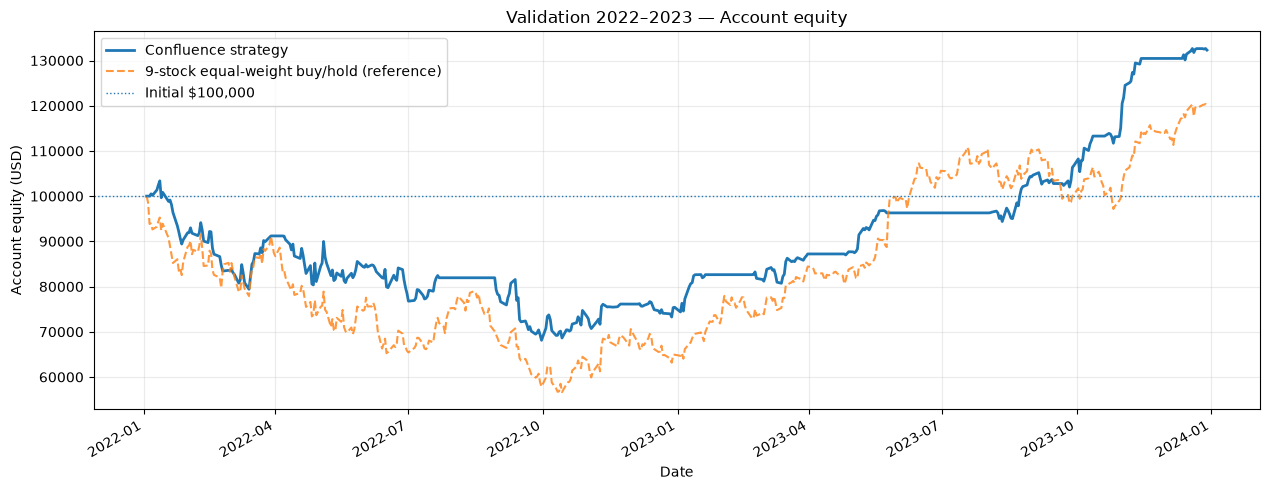

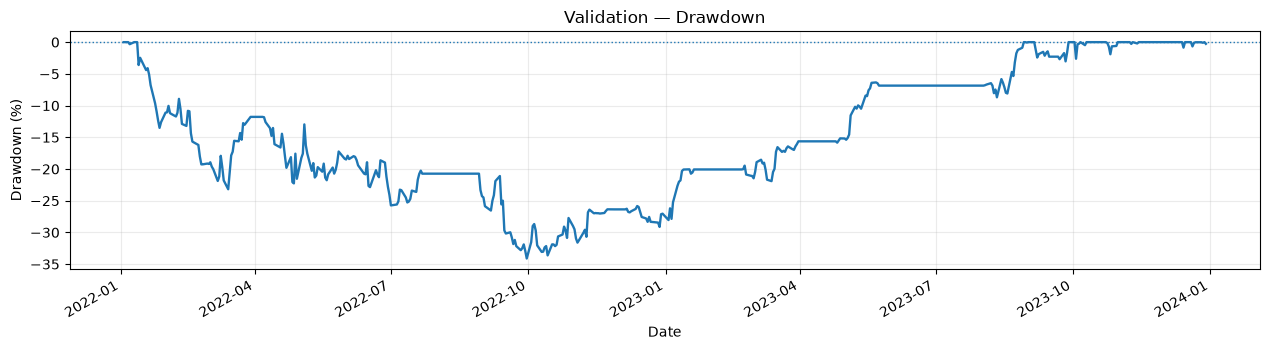

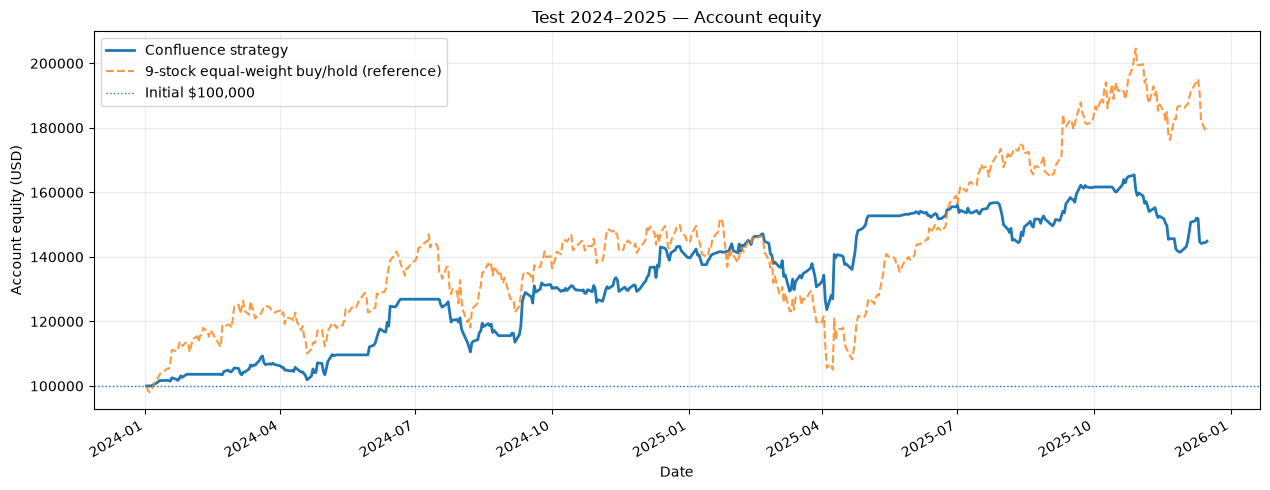

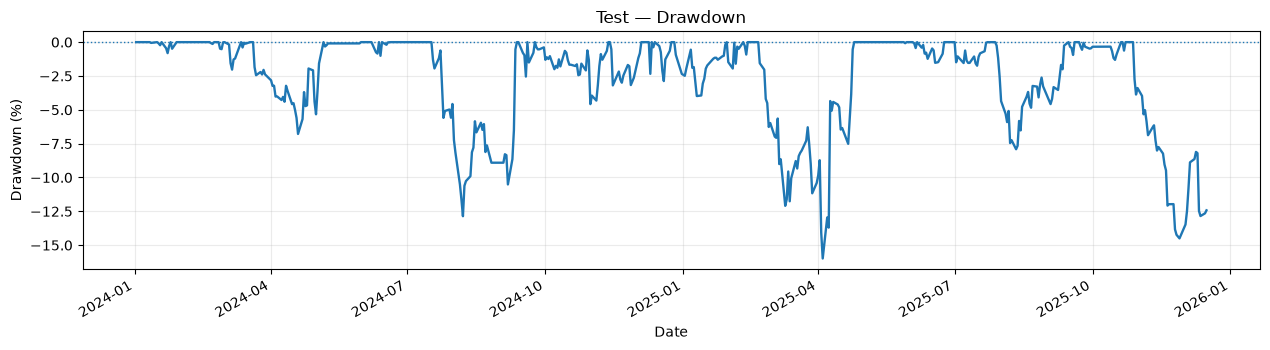


CELL 8: CATBOOST — FROZEN TIER-3 OHLC BACKTEST — VALIDATION / TEST
Enabled sides: ('Long',)
Factors: Long 6; Short 0; votes >= 5, percentile >= 80%
Cash $100,000.00; max 3 positions x 33.0% equity; next-open gap <= 2.5%
TP 2.5M; SL 0.7M; hold <= 15 bars (entry bar = 1)
M calibration: Train 2015-2021; positive >= 70/stock; pooled >= 70/side
Costs: 0 bps per leg; short collateral 100% of entry notional
Validation/Test accounts independent; frozen factor names/signs and ECDF fit before 2022.
Ranking: frozen Train-only Priority DESC -> votes DESC -> strength DESC -> ticker ASC
Signals after close t -> next-open fills; same-day stop/TP assumes STOP FIRST.
M is TRAIN winner-only 10D close-close return: not a calibrated next-open profit forecast.
Split-adjusted OHLC, dividends/borrow/financing not modeled; Test results are FINAL holdout.

1. Stage and annual performance:


,Period,Year,Initial_Equity_USD,Ending_Equity_USD,Net_Profit_USD,Total_Return,Annualized_Return,Max_Drawdown,Sharpe_252,Trading_Days,Trades,Long_Trades,Short_Trades,Trade_Win_Rate,Avg_Trade_Return,Profit_Factor,Invested_Day_Fraction,Mean_Open_Positions
0,Validation,ALL,100000.00000,132305.35440,32305.35440,0.32305,0.15121,-0.34108,0.73612,501,83,83,0,0.39759,0.01253,1.46733,0.66467,1.33134
1,Validation,2022,100000.00000,75422.84927,-24577.15073,-0.24577,-0.24662,-0.34108,-0.86772,251,61,61,0,0.22951,-0.01394,0.58767,0.80876,1.66534
2,Validation,2023,75422.84927,132305.35440,56882.50514,0.75418,0.76209,-0.04148,3.90753,250,22,22,0,0.86364,0.08592,14.43083,0.52000,0.99600
3,Test,ALL,100000.00000,144867.85194,44867.85194,0.44868,0.20906,-0.15985,1.05661,492,85,85,0,0.42353,0.01531,1.44415,0.81301,1.51423
4,Test,2024,100000.00000,139893.77544,39893.77544,0.39894,0.39894,-0.12860,1.91509,252,35,35,0,0.48571,0.03164,2.24433,0.75794,1.39683
5,Test,2025,139893.77544,144867.85194,4974.07649,0.03556,0.03737,-0.15985,0.27744,240,50,50,0,0.38000,0.00387,1.08076,0.87083,1.63750



2. Initial account rows:


,Period,Date,Cash_USD,Equity_USD,Open_Positions
0,Validation,2022-01-03,100000.0,100000.0,0
502,Test,2024-01-02,100000.0,100000.0,0



3. Trades by exit reason:


,Exit_Reason,FOLD_END_CLOSE,STOP_GAP_OPEN,STOP_INTRADAY,TAKE_PROFIT_GAP_OPEN,TAKE_PROFIT_INTRADAY,TIME_EXIT_15_BARS_CLOSE
Period,Direction,,,,,,
Test,Long,1,9,29,3,6,37
Validation,Long,1,9,38,1,7,27


... (22 outputs left out)

/home/zilinm2/Fin 556/Cell8_Test_Equity.png

Cell8_Test_Drawdown.png


/home/zilinm2/Fin 556/Cell8_Test_Drawdown.png


CELL 8 STATUS: COMPLETED


In [11]:
# ============================================================================
# CELL 8 — CATBOOST: FROZEN TIER-3 CONFLUENCE VALIDATION / TEST OHLC BACKTEST
# Requires Cells 1–7. Single notebook cell; no Validation/Test labels for signals.
# Trading parameters are editable below. Factor selection and quality weights
# are frozen upstream; entry votes (3-6) are independently configurable.
# ============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, FileLink

# 0. USER-ADJUSTABLE TRADING / RISK PARAMETERS (set BEFORE inspecting Test)
C8_START_CAPITAL = 100_000.0        # USD, independent account for each stage
C8_MAX_POSITIONS = 3                # simultaneous positions, no duplicate ticker
C8_POSITION_FRACTION = 0.33         # target notional / current OPEN equity
C8_MIN_VOTES = 5                  # choose 3, 4, 5, or 6; never below 3
C8_MAX_ENTRY_GAP = 0.025           # abs(next open / signal close - 1) <= 2.5%
C8_MAX_HOLD_BARS = 15             # entry session counts as bar 1 (11 = t+1..t+11)
C8_TP_M_MULT = 2.5                 # TP distance = multiplier * train-only M
C8_SL_M_MULT = 0.7          # SL distance = multiplier * train-only M
C8_MIN_STOCK_POSITIVE = 70        # train positive events required for stock M
C8_MIN_SIDE_POSITIVE = 70         # min pooled side events for fallback M
C8_M_TRAIN_START_YEAR = 2015      # M estimation sample start, never after 2021
C8_ZERO_COSTS = True              # default: exactly zero entry/exit cost
C8_COST_BPS_PER_LEG = 1.0          # used ONLY if C8_ZERO_COSTS = False
C8_SHORT_COLLATERAL_RATIO = 1.0   # reserve at least 100% short entry notional
C8_TRADE_SIDES = ('Long', 'Short')  # allowed subset; cannot enable a disabled side
C8_OUTPUT_DIR = Path.cwd()        # two CSV trade logs and four PNG figures
C8_OHLC_COLS = ('DlyOpen', 'DlyHigh', 'DlyLow', 'DlyClose')

# Frozen Train-only factors, weights, and ECDF; independently configurable votes.
C8_SINGLE_FACTOR_Q = C6_FACTOR_Q
C8_SCHEDULE = {'Validation': (2022, 2023), 'Test': (2024, 2025)}
C8_SIGNAL_TRAIN_CUTOFF = 2021
C8_SHARED_TRAIN_CUTOFF = C8_SIGNAL_TRAIN_CUTOFF  # legacy interface; frozen
C8_SIDES = ('Long', 'Short')                     # legacy direction labels
C8_COST_RATE = 0.0 if C8_ZERO_COSTS else C8_COST_BPS_PER_LEG / 10000.0

assert target_col == 'TARGET_10' and HORIZON == 10
assert C51_MIN_VOTES == C6_MIN_VOTES == 3
assert type(C8_MIN_VOTES) is int and C8_MIN_VOTES in (3, 4, 5, 6)
assert np.isclose(C8_SINGLE_FACTOR_Q, C51_FACTOR_Q)
assert isinstance(C8_MAX_POSITIONS, int) and C8_MAX_POSITIONS >= 1
assert isinstance(C8_MAX_HOLD_BARS, int) and C8_MAX_HOLD_BARS >= 1
assert np.isfinite(C8_START_CAPITAL) and C8_START_CAPITAL > 0
assert np.isfinite(C8_POSITION_FRACTION) and 0 < C8_POSITION_FRACTION <= 1
assert np.isfinite(C8_MAX_ENTRY_GAP) and 0 <= C8_MAX_ENTRY_GAP < 1
assert np.isfinite(C8_TP_M_MULT) and C8_TP_M_MULT > 0
assert np.isfinite(C8_SL_M_MULT) and C8_SL_M_MULT > 0
assert isinstance(C8_MIN_STOCK_POSITIVE, int) and C8_MIN_STOCK_POSITIVE >= 1
assert isinstance(C8_MIN_SIDE_POSITIVE, int) and C8_MIN_SIDE_POSITIVE >= 1
assert isinstance(C8_M_TRAIN_START_YEAR, int) and 2015 <= C8_M_TRAIN_START_YEAR <= 2021
assert isinstance(C8_ZERO_COSTS, bool)
assert np.isfinite(C8_COST_BPS_PER_LEG) and C8_COST_BPS_PER_LEG >= 0
assert np.isfinite(C8_SHORT_COLLATERAL_RATIO) and C8_SHORT_COLLATERAL_RATIO >= 1
assert len(C8_TRADE_SIDES) == len(set(C8_TRADE_SIDES))
assert set(C8_TRADE_SIDES).issubset({'Long', 'Short'})
assert len(C8_OHLC_COLS) == 4 and len(set(C8_OHLC_COLS)) == 4
assert all(c in data.columns for c in C8_OHLC_COLS)
assert len(tech_tickers) == 9 and data.index.is_unique
assert set(factor_six_validation['selected']) == {'Long', 'Short'}
assert set(factor_six_validation['orientations']) == {'Long', 'Short'}
assert C8_SCHEDULE == {'Validation': (2022, 2023), 'Test': (2024, 2025)}
assert set(C8_TRADE_SIDES).issubset(set(C51_SIDES))
C8_OUTPUT_DIR = Path(C8_OUTPUT_DIR)
C8_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

C8_ENABLED_SIDES = tuple(s for s in ('Long', 'Short')
                         if factor_six_validation['enabled'][s] and s in C8_TRADE_SIDES)
C8_FROZEN_FACTORS = {s: list(factor_six_validation['selected'][s]) for s in ('Long', 'Short')}
C8_FROZEN_SIGNS = factor_six_validation['orientations']
# Use EXACTLY Cell 6's 2021-frozen Composite_Score normalization.
C8_FROZEN_WEIGHTS = {
    side: c6_quality_weights(factor_validation, side, C8_FROZEN_FACTORS[side])
    for side in ('Long', 'Short')
}
for side in ('Long', 'Short'):
    fs = C8_FROZEN_FACTORS[side]
    assert not fs or 4 <= len(fs) <= C51_N
    assert len(fs) == len(set(fs))
    assert set(C8_FROZEN_SIGNS[side]) == set(fs)
    assert all(C8_FROZEN_SIGNS[side][f] in (-1, 1) for f in fs)
    assert (len(fs) > 0) == bool(factor_six_validation['enabled'][side])
    assert len(C8_FROZEN_WEIGHTS[side]) == len(fs)
    if fs:
        assert np.isfinite(C8_FROZEN_WEIGHTS[side]).all()
        assert np.isclose(C8_FROZEN_WEIGHTS[side].sum(), 1.0)
assert not (factor_six_validation['force_flat'] and C8_ENABLED_SIDES)

# 1. Frozen ECDF signal generation. Validation is audited against Cell 6.
def c8_make_frozen_stage_signals(stage):
    assert stage in C8_SCHEDULE
    start_year, end_year = C8_SCHEDULE[stage]
    features = list(dict.fromkeys(sum((C8_FROZEN_FACTORS[s] for s in ('Long', 'Short')), [])))
    assert target_col not in features, 'Targets cannot be used to generate signals.'
    columns = ['PERMNO', 'Ticker', 'DlyCalDt', 'Split'] + features
    tr = data.loc[validation_fold['train_fit_idx'], columns].copy()
    tr['DlyCalDt'] = pd.to_datetime(tr['DlyCalDt'])
    assert tr['DlyCalDt'].dt.year.max() <= C8_SIGNAL_TRAIN_CUTOFF
    mask = (pd.to_datetime(data['DlyCalDt']).dt.year.between(start_year, end_year)
            & data['Ticker'].isin(tech_tickers))
    oo = data.loc[mask, columns].copy()
    oo['DlyCalDt'] = pd.to_datetime(oo['DlyCalDt'])
    assert not oo.empty and set(oo['Split']) == {stage}
    assert set(oo['Ticker']) == set(tr['Ticker']) == set(tech_tickers)
    assert set(oo['DlyCalDt'].dt.year) == set(range(start_year, end_year + 1))
    assert tr['Split'].eq('Train').all() and tr['DlyCalDt'].max() < oo['DlyCalDt'].min()
    assert not oo[['DlyCalDt', 'Ticker']].duplicated().any()
    assert tr[columns].notna().all().all() and oo[columns].notna().all().all()
    if features:
        assert np.isfinite(tr[features].to_numpy(dtype=float)).all()
        assert np.isfinite(oo[features].to_numpy(dtype=float)).all()

    out = oo[['PERMNO', 'Ticker', 'DlyCalDt', 'Split']].copy()
    out['Period'] = stage
    out['Year'] = oo['DlyCalDt'].dt.year
    out['History_Start'] = tr['DlyCalDt'].min()
    out['History_Cutoff'] = tr['DlyCalDt'].max()
    tr_tick, oo_tick = tr['Ticker'].to_numpy(), oo['Ticker'].to_numpy()

    for side in ('Long', 'Short'):
        fs = C8_FROZEN_FACTORS[side] if side in C8_ENABLED_SIDES else []
        signs = C8_FROZEN_SIGNS[side]
        scores = np.zeros((len(oo), len(fs)), dtype=float)
        if fs:
            for ticker in tech_tickers:
                a = tr_tick == ticker
                b = oo_tick == ticker
                assert a.sum() >= 30 and b.any()
                for j, f in enumerate(fs):
                    scores[b, j] = c6_favorable_pct(
                        tr.loc[a, f].to_numpy(dtype=float),
                        oo.loc[b, f].to_numpy(dtype=float), int(signs[f]))
        hits = scores >= C8_SINGLE_FACTOR_Q
        votes = hits.sum(axis=1).astype(int)
        strength = np.divide((scores * hits).sum(axis=1), votes,
                             out=np.zeros(len(oo), dtype=float), where=votes > 0)
        priority = (scores * hits) @ C8_FROZEN_WEIGHTS[side]
        out[f'{side}_Priority'] = priority
        out[f'{side}_N_Factors'] = len(fs)
        out[f'{side}_Enabled'] = bool(fs)
        out[f'{side}_Votes'] = votes
        out[f'{side}_Strength'] = strength
        out[f'{side}_Qualified'] = bool(fs) & (votes >= C8_MIN_VOTES)
        out[f'{side}_Selected_Factors'] = '|'.join(fs)
        matches = [[f for f, hit in zip(fs, flags) if hit] for flags in hits]
        out[f'{side}_Matched_Factors'] = ['|'.join(m) for m in matches]
        out[f'{side}_Matched_Families'] = [
            '|'.join(sorted({c6_factor_family(f) for f in m})) for m in matches]
        out[f'{side}_Family_Count'] = [len({c6_factor_family(f) for f in m}) for m in matches]
        for j, f in enumerate(fs):
            out[f'{side}_Pct__{f}'] = scores[:, j]
            out[f'{side}_OK__{f}'] = hits[:, j]
        assert (votes <= len(fs)).all()
        if not fs:
            assert not out[f'{side}_Qualified'].any()

    out['Signal_Conflict'] = out['Long_Qualified'] & out['Short_Qualified']
    day_sides = out.groupby('DlyCalDt', sort=False)[['Long_Qualified', 'Short_Qualified']].transform('any')
    out['Daily_Conflict'] = day_sides['Long_Qualified'] & day_sides['Short_Qualified']
    out['New_Entries_Allowed'] = ~out['Daily_Conflict']
    for side in ('Long', 'Short'):
        out[f'{side}_Cancelled_By_Daily_Conflict'] = out[f'{side}_Qualified'] & out['Daily_Conflict']
        out[f'{side}_Candidate'] = out[f'{side}_Qualified'] & ~out['Daily_Conflict']
    out['Candidate_Direction'] = np.select(
        [out['Long_Candidate'], out['Short_Candidate']], ['Long', 'Short'], default='NONE')
    out['Candidate_Votes'] = np.select(
        [out['Long_Candidate'], out['Short_Candidate']],
        [out['Long_Votes'], out['Short_Votes']], default=0).astype(int)
    out['Candidate_Strength'] = np.select(
        [out['Long_Candidate'], out['Short_Candidate']],
        [out['Long_Strength'], out['Short_Strength']], default=np.nan)
    out['Candidate_Priority'] = np.select(
        [out['Long_Candidate'], out['Short_Candidate']],
        [out['Long_Priority'], out['Short_Priority']], default=np.nan)
    assert np.isfinite(out.loc[out['Candidate_Direction'].ne('NONE'),
                               'Candidate_Priority']).all()
    out['Trade_Signal_Available'] = 'AFTER_CLOSE'
    out['Earliest_Execution'] = 'NEXT_TRADING_DAY'
    order = out.loc[out['Candidate_Direction'].ne('NONE')].sort_values(
        ['DlyCalDt', 'Candidate_Priority', 'Candidate_Votes',
         'Candidate_Strength', 'Ticker'],
        ascending=[True, False, False, False, True], kind='mergesort')
    out['Daily_Rank_All'] = pd.Series(pd.NA, index=out.index, dtype='Int64')
    out.loc[order.index, 'Daily_Rank_All'] = order.groupby('DlyCalDt').cumcount().to_numpy() + 1
    assert not out.loc[out['Daily_Conflict'], 'Candidate_Direction'].ne('NONE').any()
    assert not (out['Long_Candidate'] & out['Short_Candidate']).any()
    if len(C8_ENABLED_SIDES) < 2:
        assert not out['Daily_Conflict'].any()
    return out

cell8_validation_signals = c8_make_frozen_stage_signals('Validation')
cell8_test_signals = c8_make_frozen_stage_signals('Test')
assert cell8_validation_signals.index.intersection(cell8_test_signals.index).empty
# Exact agreement with the previously frozen independent Validation signals.
# This assertion protects against accidental signal drift in the backtest.
if set(C8_ENABLED_SIDES) == set(s for s in ('Long', 'Short') if factor_six_validation['enabled'][s]):
    ref = cell6_validation_signals.reindex(cell8_validation_signals.index)
    assert ref['Ticker'].equals(cell8_validation_signals['Ticker'])
    for side in ('Long', 'Short'):
        assert np.array_equal(ref[f'{side}_Votes'].to_numpy(),
                              cell8_validation_signals[f'{side}_Votes'].to_numpy())
        assert np.allclose(ref[f'{side}_Strength'], cell8_validation_signals[f'{side}_Strength'])
        assert np.allclose(ref[f'{side}_Priority'], cell8_validation_signals[f'{side}_Priority'])
        # Cell 6 stays at >=3 votes; Cell 8 may require 3/4/5/6 votes.
        expected_qualified = (
            ref[f'{side}_Enabled'].to_numpy(dtype=bool)
            & (ref[f'{side}_Votes'].to_numpy(dtype=int) >= C8_MIN_VOTES)
        )
        assert np.array_equal(expected_qualified,
                              cell8_validation_signals[f'{side}_Qualified'].to_numpy())
        if C8_MIN_VOTES == C6_MIN_VOTES:
            assert np.array_equal(ref[f'{side}_Candidate'].to_numpy(),
                                  cell8_validation_signals[f'{side}_Candidate'].to_numpy())
    if C8_MIN_VOTES == C6_MIN_VOTES:
        assert ref['Daily_Conflict'].equals(cell8_validation_signals['Daily_Conflict'])
        assert np.allclose(ref['Candidate_Priority'],
                           cell8_validation_signals['Candidate_Priority'], equal_nan=True)
        # Cell 6 ranks Validation candidates by the same frozen Priority.
        ref_rank = cell6_signal_panel.loc[cell8_validation_signals.index, 'Daily_Rank_All']
        assert ref_rank.astype('Int64').equals(cell8_validation_signals['Daily_Rank_All'].astype('Int64'))

C8_PANEL_COLS = ['Period', 'Year', 'DlyCalDt', 'Ticker', 'Candidate_Direction',
                 'Candidate_Votes', 'Candidate_Strength', 'Candidate_Priority', 'Daily_Rank_All',
                 'Daily_Conflict', 'Long_Matched_Factors', 'Short_Matched_Factors',
                 'Long_Matched_Families', 'Short_Matched_Families']
c8_panel = pd.concat([cell8_validation_signals[C8_PANEL_COLS],
                      cell8_test_signals[C8_PANEL_COLS]], axis=0)
c8_panel = c8_panel.sort_values(['DlyCalDt', 'Ticker'], kind='mergesort').copy()
assert c8_panel.index.is_unique
c8_source = data.loc[c8_panel.index, ['Ticker', 'DlyCalDt'] + list(C8_OHLC_COLS)]
assert np.array_equal(c8_source['Ticker'].to_numpy(), c8_panel['Ticker'].to_numpy())
assert np.array_equal(pd.to_datetime(c8_source['DlyCalDt']).to_numpy(),
                      pd.to_datetime(c8_panel['DlyCalDt']).to_numpy())
raw_prices = c8_source[list(C8_OHLC_COLS)].to_numpy(dtype=float)
assert np.isfinite(raw_prices).all() and (raw_prices > 0).all()
# Explicit order of independently editable source columns.
for output_col, source_col in zip(('DlyOpen', 'DlyHigh', 'DlyLow', 'DlyClose'), C8_OHLC_COLS):
    c8_panel[output_col] = c8_source[source_col].to_numpy(dtype=float)
assert (c8_panel['DlyHigh'] >= c8_panel[['DlyOpen', 'DlyClose']].max(axis=1)).all()
assert (c8_panel['DlyLow'] <= c8_panel[['DlyOpen', 'DlyClose']].min(axis=1)).all()
assert (c8_panel['DlyHigh'] >= c8_panel['DlyLow']).all()
c8_panel['DlyCalDt'] = pd.to_datetime(c8_panel['DlyCalDt'])
assert not c8_panel[['DlyCalDt', 'Ticker']].duplicated().any()

# 2. TRAIN-ONLY M: same underlying estimator as original Cell 8.
# This is a 10D, signal-close, winner-only TRAIN heuristic, not an executable
# next-open payoff estimate. M never reads Validation or Test targets.
def c8_calibrate_m():
    fs = list(dict.fromkeys(sum((C8_FROZEN_FACTORS[s] for s in C8_ENABLED_SIDES), [])))
    columns = ['Ticker', 'DlyCalDt', target_col] + fs
    tr = data.loc[validation_fold['train_fit_idx'], columns].copy()
    tr['DlyCalDt'] = pd.to_datetime(tr['DlyCalDt'])
    tr = tr.loc[tr['DlyCalDt'].dt.year.between(C8_M_TRAIN_START_YEAR, 2021)].copy()
    # train_fit_idx already purges labels at the 2021 boundary.
    # Earlier start dates do not create a future-label problem.
    assert tr['DlyCalDt'].max() < pd.Timestamp(validation_fold['oos_start'])
    assert set(tr['Ticker']) == set(tech_tickers)
    assert tr[[target_col] + fs].notna().all().all()
    assert np.isfinite(tr[[target_col] + fs].to_numpy(dtype=float)).all()
    lookup, records, details = {}, [], {}
    for side in ('Long', 'Short'):
        selected = C8_FROZEN_FACTORS[side] if side in C8_ENABLED_SIDES else []
        signs = C8_FROZEN_SIGNS[side]
        event_counts, positive = {}, {}
        for ticker in tech_tickers:
            block = tr.loc[tr['Ticker'].eq(ticker)].sort_values('DlyCalDt')
            assert len(block) >= 30
            if selected:
                flags = np.column_stack([
                    c6_favorable_pct(block[f].to_numpy(dtype=float),
                                     block[f].to_numpy(dtype=float), int(signs[f]))
                    >= C8_SINGLE_FACTOR_Q for f in selected
                ])
                qualifying = flags.sum(axis=1) >= C8_MIN_VOTES
                signed_returns = block[target_col].to_numpy(dtype=float) * (1 if side == 'Long' else -1)
                good = signed_returns[qualifying & (signed_returns > 0)]
                event_counts[ticker] = int(qualifying.sum())
                positive[ticker] = good
            else:
                event_counts[ticker] = 0
                positive[ticker] = np.array([], dtype=float)
        pooled = np.concatenate(list(positive.values()))
        pooled_m = float(pooled.mean()) if len(pooled) >= C8_MIN_SIDE_POSITIVE else np.nan
        details[side] = {'Pooled_Positive_N': len(pooled), 'Pooled_M': pooled_m,
                         'Total_Qualifying_Train_Signals': sum(event_counts.values())}
        for ticker in tech_tickers:
            good = positive[ticker]
            n = len(good)
            if not selected:
                m, source = np.nan, 'DISABLED_SIDE'
            elif n >= C8_MIN_STOCK_POSITIVE:
                m, source = float(good.mean()), 'STOCK_TRAIN'
            elif np.isfinite(pooled_m):
                m, source = pooled_m, 'SIDE_POOLED_TRAIN'
            else:
                m, source = np.nan, 'UNAVAILABLE_NO_TRADE'
            if selected and (not np.isfinite(m) or not (0 < m < 1)):
                m, source = np.nan, 'UNAVAILABLE_NO_TRADE'
            lookup[(side, ticker)] = (m, source, n, event_counts[ticker])
            records.append({
                'Fold': 'FROZEN_THROUGH_2021', 'Direction': side, 'Ticker': ticker,
                'Calibration': source, 'Train_Confluence_Signals': event_counts[ticker],
                'Train_Positive_Events': n, 'Pooled_Positive_Events': len(pooled),
                'M_Positive_Signed_Return': m,
                'Take_Profit_Pct': C8_TP_M_MULT * m if np.isfinite(m) else np.nan,
                'Stop_Loss_Pct': C8_SL_M_MULT * m if np.isfinite(m) else np.nan
            })
    return lookup, records, details

c8_calibrated, c8_records, c8_m_details = c8_calibrate_m()
cell8_m_calibration_df = pd.DataFrame(c8_records)
c8_m_by_fold = {(stage, f'{a}-{b}'): c8_calibrated
                for stage, (a, b) in C8_SCHEDULE.items()}

# 3. Daily OHLC trading, at most one position per ticker.
C8_TRADE_COUNTER = 0

def c8_mark_equity(cash, positions, bars, mark_col='DlyClose'):
    value = float(cash)
    for ticker, p in positions.items():
        mark = float(bars[ticker][mark_col])
        if p['Direction'] == 'Long':
            value += p['Qty'] * mark
        else:
            value += p['Qty'] * (p['Entry_Price'] - mark)
    return value

def c8_available_cash(cash, positions):
    locked = sum(C8_SHORT_COLLATERAL_RATIO * p['Entry_Notional_USD']
                 for p in positions.values() if p['Direction'] == 'Short')
    return float(cash) - locked

def c8_exit_price(p, bar, allow_intraday=True):
    op, hi, lo = (float(bar[k]) for k in ('DlyOpen', 'DlyHigh', 'DlyLow'))
    tp, sl = p['TP_Price'], p['SL_Price']
    if p['Direction'] == 'Long':
        if op <= sl:
            return op, 'STOP_GAP_OPEN', False
        if op >= tp:
            return op, 'TAKE_PROFIT_GAP_OPEN', False
        hit_stop, hit_tp = hi >= sl and lo <= sl, hi >= tp
    else:
        if op >= sl:
            return op, 'STOP_GAP_OPEN', False
        if op <= tp:
            return op, 'TAKE_PROFIT_GAP_OPEN', False
        hit_stop, hit_tp = hi >= sl, lo <= tp
    if not allow_intraday:
        return None, None, False
    if hit_stop and hit_tp:
        return sl, 'STOP_AND_TP_SAME_BAR_STOP_FIRST', True
    if hit_stop:
        return sl, 'STOP_INTRADAY', False
    if hit_tp:
        return tp, 'TAKE_PROFIT_INTRADAY', False
    return None, None, False

# Regression tests for intraday level handling, for both directions.
for _side in ('Long', 'Short'):
    _p = {'Direction': _side,
          'TP_Price': 110.0 if _side == 'Long' else 90.0,
          'SL_Price': 95.0 if _side == 'Long' else 105.0}
    assert c8_exit_price(_p, {'DlyOpen':100., 'DlyHigh':112., 'DlyLow':88.})[1] == 'STOP_AND_TP_SAME_BAR_STOP_FIRST'
    assert c8_exit_price(_p, {'DlyOpen':100., 'DlyHigh':101., 'DlyLow':99.})[0] is None


def c8_run_stage(period, begin_capital):
    global C8_TRADE_COUNTER
    assert period in C8_SCHEDULE
    panel = c8_panel.loc[c8_panel['Period'].eq(period)].sort_values(['DlyCalDt', 'Ticker']).copy()
    dates = list(pd.DatetimeIndex(panel['DlyCalDt'].unique()).sort_values())
    assert dates and not panel[['DlyCalDt', 'Ticker']].duplicated().any()
    bars_by_date = {}
    for d, daily in panel.groupby('DlyCalDt', sort=True):
        bars_by_date[pd.Timestamp(d)] = {
            r.Ticker: {'DlyOpen': float(r.DlyOpen), 'DlyHigh': float(r.DlyHigh),
                       'DlyLow': float(r.DlyLow), 'DlyClose': float(r.DlyClose)}
            for r in daily.itertuples(index=False)
        }
        assert len(bars_by_date[pd.Timestamp(d)]) == len(tech_tickers)

    qualified = panel.loc[panel['Candidate_Direction'].ne('NONE')].copy()
    qualified = qualified.sort_values(
        ['DlyCalDt', 'Candidate_Priority', 'Candidate_Votes',
         'Candidate_Strength', 'Ticker'],
        ascending=[True, False, False, False, True], kind='mergesort')
    assert not qualified['Daily_Conflict'].any()
    candidate_by_date = {pd.Timestamp(d): g.to_dict('records')
                         for d, g in qualified.groupby('DlyCalDt', sort=True)}
    cash, positions, trades, curve, skips = float(begin_capital), {}, [], [], []
    pending = []
    last_date = dates[-1]
    fold = f'{C8_SCHEDULE[period][0]}-{C8_SCHEDULE[period][1]}'
    m_table = c8_m_by_fold[(period, fold)]

    def close_position(ticker, exit_price, date, reason, ambiguous=False):
        nonlocal cash
        p = positions.pop(ticker)
        qty, price = p['Qty'], float(exit_price)
        gross = qty * (price - p['Entry_Price']) * (1 if p['Direction'] == 'Long' else -1)
        fee = qty * price * C8_COST_RATE
        if p['Direction'] == 'Long':
            cash += qty * price - fee
        else:
            cash += gross - fee
        result = dict(p)
        result.update({
            'Exit_Date': pd.Timestamp(date), 'Exit_Price': price, 'Exit_Reason': reason,
            'Exit_Notional_USD': qty * price, 'Trade_Bars': p['Bars_Held'],
            'Gross_PnL_USD': gross, 'Exit_Cost_USD': fee,
            'Transaction_Cost_USD': p['Entry_Cost_USD'] + fee,
            'Net_PnL_USD': gross - p['Entry_Cost_USD'] - fee,
            'Return_On_Notional': (gross - p['Entry_Cost_USD'] - fee) / p['Entry_Notional_USD'],
            'Win': gross - p['Entry_Cost_USD'] - fee > 0,
            'OHLC_Both_Levels_Touched_Stop_First': bool(ambiguous)
        })
        trades.append(result)

    for date in dates:
        date = pd.Timestamp(date)
        bars = bars_by_date[date]
        exited_at_open = set()
        # First handle gaps for positions held since yesterday.
        for ticker in list(positions):
            ep, reason, ambiguous = c8_exit_price(positions[ticker], bars[ticker], False)
            if ep is not None:
                close_position(ticker, ep, date, reason, ambiguous)
                exited_at_open.add(ticker)

        # Prior-close orders are attempted only at today's open.
        if date != last_date:
            for candidate in pending:
                if len(positions) >= C8_MAX_POSITIONS:
                    break
                ticker, side = candidate['Ticker'], candidate['Candidate_Direction']
                if ticker in positions or ticker in exited_at_open:
                    continue
                assert side in C8_ENABLED_SIDES
                m, m_source, positive_n, train_n = m_table[(side, ticker)]
                if not np.isfinite(m):
                    skips.append({'Period': period, 'Date': date, 'Ticker': ticker,
                                  'Direction': side, 'Reason': 'NO_TRAIN_M'})
                    continue
                op = float(bars[ticker]['DlyOpen'])
                signal_close = float(candidate['DlyClose'])
                gap = op / signal_close - 1.0
                if abs(gap) > C8_MAX_ENTRY_GAP + 1e-12:
                    skips.append({'Period': period, 'Date': date, 'Ticker': ticker,
                                  'Direction': side, 'Reason': 'OPEN_OUTSIDE_CONFIGURED_GAP'})
                    continue
                equity_open = c8_mark_equity(cash, positions, bars, 'DlyOpen')
                if not np.isfinite(equity_open) or equity_open <= 0:
                    skips.append({'Period': period, 'Date': date, 'Ticker': ticker,
                                  'Direction': side, 'Reason': 'NONPOSITIVE_EQUITY'})
                    continue
                target_notional = C8_POSITION_FRACTION * equity_open
                qty = int(np.floor(target_notional / op))
                notional = qty * op
                fee = notional * C8_COST_RATE
                if side == 'Long':
                    tp = op * (1 + C8_TP_M_MULT * m)
                    sl = op * (1 - C8_SL_M_MULT * m)
                else:
                    tp = op * (1 - C8_TP_M_MULT * m)
                    sl = op * (1 + C8_SL_M_MULT * m)
                if not (0 < tp < np.inf and 0 < sl < np.inf):
                    skips.append({'Period': period, 'Date': date, 'Ticker': ticker,
                                  'Direction': side, 'Reason': 'INVALID_TP_SL_LEVEL'})
                    continue
                needed = (notional + fee if side == 'Long'
                          else C8_SHORT_COLLATERAL_RATIO * notional + fee)
                if qty < 1 or needed > c8_available_cash(cash, positions) + 1e-8:
                    skips.append({'Period': period, 'Date': date, 'Ticker': ticker,
                                  'Direction': side, 'Reason': 'INSUFFICIENT_CASH_OR_EQUITY'})
                    continue
                if side == 'Long':
                    cash -= notional + fee
                else:
                    cash -= fee   # proceeds segregated; short collateral reserved above
                C8_TRADE_COUNTER += 1
                positions[ticker] = {
                    'Trade_ID': f'T{C8_TRADE_COUNTER:06d}', 'Period': period,
                    'Fold': fold, 'Ticker': ticker, 'Direction': side,
                    'Signal_Date': pd.Timestamp(candidate['DlyCalDt']),
                    'Entry_Date': date, 'Signal_Votes': int(candidate['Candidate_Votes']),
                    'Signal_Strength': float(candidate['Candidate_Strength']),
                    'Signal_Priority': float(candidate['Candidate_Priority']),
                    'Signal_Rank': int(candidate['Daily_Rank_All']),
                    'Matched_Factors': candidate[f'{side}_Matched_Factors'],
                    'Matched_Families': candidate[f'{side}_Matched_Families'],
                    'Signal_Close': signal_close, 'Entry_Open': op, 'Entry_Price': op,
                    'Entry_Gap_From_Signal_Close': gap,
                    'Entry_Equity_USD': equity_open, 'Target_Notional_USD': target_notional,
                    'Qty': qty, 'Entry_Notional_USD': notional, 'Entry_Cost_USD': fee,
                    'M_Source': m_source, 'M_Train_Positive_Events': int(positive_n),
                    'M_Train_Confluence_Events': int(train_n), 'Historical_M': m,
                    'TP_Pct': C8_TP_M_MULT * m, 'SL_Pct': C8_SL_M_MULT * m,
                    'TP_Price': tp, 'SL_Price': sl, 'Bars_Held': 0
                }

        # Entry-day HIGH/LOW is available after the open, for both new and old.
        for ticker in list(positions):
            positions[ticker]['Bars_Held'] += 1
            ep, reason, ambiguous = c8_exit_price(positions[ticker], bars[ticker], True)
            if ep is not None:
                close_position(ticker, ep, date, reason, ambiguous)

        for ticker in list(positions):
            if positions[ticker]['Bars_Held'] >= C8_MAX_HOLD_BARS:
                close_position(ticker, bars[ticker]['DlyClose'], date,
                               f'TIME_EXIT_{C8_MAX_HOLD_BARS}_BARS_CLOSE')

        # Stage ends independent and flat. No positions roll from Val to Test.
        if date == last_date:
            for ticker in list(positions):
                close_position(ticker, bars[ticker]['DlyClose'], date, 'FOLD_END_CLOSE')

        equity = c8_mark_equity(cash, positions, bars)
        reserved = sum(C8_SHORT_COLLATERAL_RATIO * p['Entry_Notional_USD']
                       for p in positions.values() if p['Direction'] == 'Short')
        long_mv = sum(p['Qty'] * bars[t]['DlyClose']
                      for t, p in positions.items() if p['Direction'] == 'Long')
        short_exposure = sum(p['Qty'] * bars[t]['DlyClose']
                             for t, p in positions.items() if p['Direction'] == 'Short')
        assert len(positions) <= C8_MAX_POSITIONS
        assert c8_available_cash(cash, positions) >= -1e-5
        assert np.isfinite(equity) and equity > 0, 'Equity <= 0; margin-call/liquidation is not modeled.'
        curve.append({
            'Period': period, 'Year': int(date.year), 'Date': date,
            'Cash_USD': cash, 'Short_Collateral_Reserved_USD': reserved,
            'Available_Cash_USD': cash - reserved,
            'Long_Market_Value_USD': long_mv,
            'Short_Market_Exposure_USD': short_exposure,
            'Equity_USD': equity, 'Open_Positions': len(positions),
            'Long_Positions': sum(p['Direction'] == 'Long' for p in positions.values()),
            'Short_Positions': sum(p['Direction'] == 'Short' for p in positions.values()),
            'Daily_Conflict': bool(panel.loc[panel['DlyCalDt'].eq(date), 'Daily_Conflict'].iloc[0])
        })
        pending = [] if date == last_date else candidate_by_date.get(date, [])

    assert not positions
    cols = ['Trade_ID', 'Period', 'Fold', 'Ticker', 'Direction', 'Signal_Date',
            'Entry_Date', 'Exit_Date', 'Signal_Votes', 'Signal_Strength', 'Signal_Priority',
            'Signal_Rank',
            'Matched_Factors', 'Matched_Families', 'Signal_Close', 'Entry_Open',
            'Entry_Price', 'Entry_Gap_From_Signal_Close', 'Entry_Equity_USD',
            'Target_Notional_USD', 'Qty', 'Entry_Notional_USD', 'Entry_Cost_USD',
            'M_Source', 'M_Train_Positive_Events', 'M_Train_Confluence_Events',
            'Historical_M', 'TP_Pct', 'SL_Pct', 'TP_Price', 'SL_Price', 'Bars_Held',
            'Exit_Price', 'Exit_Reason', 'Exit_Notional_USD', 'Trade_Bars',
            'Gross_PnL_USD', 'Exit_Cost_USD', 'Transaction_Cost_USD',
            'Net_PnL_USD', 'Return_On_Notional', 'Win',
            'OHLC_Both_Levels_Touched_Stop_First']
    return (pd.DataFrame(curve), pd.DataFrame(trades, columns=cols),
            pd.DataFrame(skips, columns=['Period', 'Date', 'Ticker', 'Direction', 'Reason']), cash)

c8_valid_curve, c8_valid_trades, c8_valid_skips, c8_valid_end = c8_run_stage('Validation', C8_START_CAPITAL)
c8_test_curve, c8_test_trades, c8_test_skips, c8_test_end = c8_run_stage('Test', C8_START_CAPITAL)
cell8_trade_log_df = pd.concat([c8_valid_trades, c8_test_trades], ignore_index=True)
cell8_skipped_entries_df = pd.concat([c8_valid_skips, c8_test_skips], ignore_index=True)
cell8_trade_log_df['Exit_Date'] = pd.to_datetime(cell8_trade_log_df['Exit_Date'])

# 4. NAV: stage starts with cash and zero holdings. Benchmark is a reference.
def c8_add_derived_equity(df, initial):
    frame = df.copy().sort_values('Date').reset_index(drop=True)
    frame['Daily_Return'] = frame['Equity_USD'].pct_change()
    if len(frame):
        frame.loc[0, 'Daily_Return'] = frame.loc[0, 'Equity_USD'] / initial - 1
    frame['Cumulative_Return'] = frame['Equity_USD'] / initial - 1
    frame['Peak_Equity'] = np.maximum.accumulate(np.r_[initial, frame['Equity_USD'].to_numpy()])[1:]
    frame['Drawdown'] = frame['Equity_USD'] / frame['Peak_Equity'] - 1
    prices = c8_panel.loc[c8_panel['Period'].eq(frame['Period'].iat[0])].pivot(
        index='DlyCalDt', columns='Ticker', values='DlyClose').reindex(frame['Date'])
    assert prices.notna().all().all()
    frame['Equal_Weight_BuyHold_Equity'] = (
        initial * prices.div(prices.iloc[0]).mean(axis=1).to_numpy())
    return frame

def c8_add_flat_start(df):
    frame = df.copy().sort_values('Date').reset_index(drop=True)
    assert frame['Open_Positions'].iat[0] == 0
    assert np.isclose(frame['Equity_USD'].iat[0], C8_START_CAPITAL)
    frame['Row_Type'] = 'DAILY_CLOSE'
    anchor = {c: np.nan for c in frame.columns}
    anchor.update({
        'Period': frame['Period'].iat[0], 'Year': int(frame['Year'].iat[0]),
        'Date': frame['Date'].iat[0], 'Row_Type': 'INITIAL',
        'Cash_USD': C8_START_CAPITAL, 'Short_Collateral_Reserved_USD': 0.0,
        'Available_Cash_USD': C8_START_CAPITAL, 'Long_Market_Value_USD': 0.0,
        'Short_Market_Exposure_USD': 0.0, 'Equity_USD': C8_START_CAPITAL,
        'Open_Positions': 0, 'Long_Positions': 0, 'Short_Positions': 0,
        'Daily_Conflict': False, 'Daily_Return': 0.0,
        'Cumulative_Return': 0.0, 'Peak_Equity': C8_START_CAPITAL,
        'Drawdown': 0.0, 'Equal_Weight_BuyHold_Equity': C8_START_CAPITAL
    })
    return pd.concat([pd.DataFrame([anchor]), frame], ignore_index=True)

c8_valid_curve = c8_add_flat_start(c8_add_derived_equity(c8_valid_curve, C8_START_CAPITAL))
c8_test_curve = c8_add_flat_start(c8_add_derived_equity(c8_test_curve, C8_START_CAPITAL))
cell8_equity_df = pd.concat([c8_valid_curve, c8_test_curve], ignore_index=True)

# 5. Reporting and deterministic ledger checks.
def c8_metrics(frame, trades, init, period, year='ALL'):
    actual = frame.loc[frame['Row_Type'].eq('DAILY_CLOSE')] if 'Row_Type' in frame else frame
    n = len(actual)
    eq = actual['Equity_USD'].to_numpy(dtype=float)
    end = float(eq[-1]) if n else float(init)
    daily = np.diff(np.r_[init, eq]) / np.r_[init, eq][:-1] if n else np.array([], dtype=float)
    vol = float(daily.std(ddof=1)) if n >= 2 else np.nan
    sharpe = float(np.sqrt(252) * daily.mean() / vol) if n >= 3 and vol > 0 else np.nan
    draw = eq / np.maximum.accumulate(np.r_[init, eq])[1:] - 1 if n else np.array([0.0])
    profits = trades['Net_PnL_USD']
    gross_win = float(profits.loc[profits > 0].sum())
    gross_loss = -float(profits.loc[profits < 0].sum())
    pf = (gross_win / gross_loss if gross_loss > 0
          else (np.inf if gross_win > 0 else np.nan))
    return {
        'Period': period, 'Year': year, 'Initial_Equity_USD': float(init),
        'Ending_Equity_USD': end, 'Net_Profit_USD': end - init,
        'Total_Return': end / init - 1,
        'Annualized_Return': ((end / init) ** (252 / n) - 1) if n and end > 0 else np.nan,
        'Max_Drawdown': float(min(0, draw.min())), 'Sharpe_252': sharpe,
        'Trading_Days': n, 'Trades': len(trades),
        'Long_Trades': int(trades['Direction'].eq('Long').sum()),
        'Short_Trades': int(trades['Direction'].eq('Short').sum()),
        'Trade_Win_Rate': float((profits > 0).mean()) if len(profits) else np.nan,
        'Avg_Trade_Return': float(trades['Return_On_Notional'].mean()) if len(trades) else np.nan,
        'Profit_Factor': pf,
        'Invested_Day_Fraction': float(actual['Open_Positions'].gt(0).mean()) if n else 0.0,
        'Mean_Open_Positions': float(actual['Open_Positions'].mean()) if n else 0.0
    }

metrics = []
for period, curve in [('Validation', c8_valid_curve), ('Test', c8_test_curve)]:
    stage_trades = cell8_trade_log_df.loc[cell8_trade_log_df['Period'].eq(period)]
    metrics.append(c8_metrics(curve, stage_trades, C8_START_CAPITAL, period))
    opening = C8_START_CAPITAL
    for yr, days in curve.loc[curve['Row_Type'].eq('DAILY_CLOSE')].groupby('Year'):
        exited = stage_trades.loc[stage_trades['Exit_Date'].dt.year.eq(int(yr))]
        metrics.append(c8_metrics(days, exited, opening, period, int(yr)))
        opening = float(days['Equity_USD'].iloc[-1])
cell8_performance_df = pd.DataFrame(metrics)


def c8_audit_stage(period, curve, trades, closing_cash):
    actual = curve.loc[curve['Row_Type'].eq('DAILY_CLOSE')]
    assert curve['Row_Type'].iat[0] == 'INITIAL'
    assert len(curve) == len(actual) + 1
    assert np.isclose(curve['Equity_USD'].iat[0], C8_START_CAPITAL)
    assert int(curve['Open_Positions'].iat[0]) == 0
    assert int(curve['Open_Positions'].iat[-1]) == 0
    assert np.isfinite(curve['Equity_USD']).all() and (curve['Equity_USD'] > 0).all()
    assert actual['Open_Positions'].le(C8_MAX_POSITIONS).all()
    assert actual['Available_Cash_USD'].ge(-1e-5).all()
    assert np.isclose(trades['Net_PnL_USD'].sum(), closing_cash - C8_START_CAPITAL, atol=1e-5)
    assert np.isclose(curve['Equity_USD'].iat[-1], closing_cash, atol=1e-5)
    if len(trades):
        assert trades['Trade_ID'].is_unique
        assert trades['Direction'].isin(C8_ENABLED_SIDES).all()
        assert trades['Signal_Votes'].between(C8_MIN_VOTES, C51_N).all()
        assert (trades['Entry_Date'] > trades['Signal_Date']).all()
        assert (trades['Exit_Date'] >= trades['Entry_Date']).all()
        assert trades['Trade_Bars'].between(1, C8_MAX_HOLD_BARS).all()
        assert trades['Entry_Gap_From_Signal_Close'].abs().le(C8_MAX_ENTRY_GAP + 1e-12).all()
        assert trades['Qty'].ge(1).all()
        assert np.allclose(trades['Entry_Notional_USD'], trades['Qty'] * trades['Entry_Price'])
        assert np.allclose(trades['Net_PnL_USD'],
                           trades['Gross_PnL_USD'] - trades['Transaction_Cost_USD'])
        assert np.allclose(trades['Return_On_Notional'],
                           trades['Net_PnL_USD'] / trades['Entry_Notional_USD'])
        stage_signals = c8_panel.loc[c8_panel['Period'].eq(period)].set_index(['DlyCalDt', 'Ticker'])
        signal_key = pd.MultiIndex.from_arrays([trades['Signal_Date'], trades['Ticker']])
        src = stage_signals.reindex(signal_key)
        assert src['Candidate_Direction'].tolist() == trades['Direction'].tolist()
        assert np.array_equal(src['Candidate_Votes'].to_numpy(dtype=int),
                              trades['Signal_Votes'].to_numpy(dtype=int))
        assert np.allclose(src['Candidate_Strength'].to_numpy(dtype=float),
                           trades['Signal_Strength'].to_numpy(dtype=float))
        assert np.allclose(src['Candidate_Priority'].to_numpy(dtype=float),
                           trades['Signal_Priority'].to_numpy(dtype=float))
        assert np.array_equal(src['Daily_Rank_All'].to_numpy(dtype=int),
                              trades['Signal_Rank'].to_numpy(dtype=int))
        calendars = pd.DatetimeIndex(stage_signals.index.get_level_values(0).unique()).sort_values()
        signal_positions = calendars.get_indexer(pd.to_datetime(trades['Signal_Date']))
        assert (signal_positions >= 0).all()
        assert (signal_positions + 1 < len(calendars)).all()
        assert (calendars[signal_positions + 1] == pd.to_datetime(trades['Entry_Date']).to_numpy()).all()
        entry_key = pd.MultiIndex.from_arrays([trades['Entry_Date'], trades['Ticker']])
        assert np.allclose(trades['Entry_Price'],
                           stage_signals['DlyOpen'].reindex(entry_key).to_numpy())
        for ticker, stock in trades.groupby('Ticker'):
            by_date = stock.sort_values(['Entry_Date', 'Exit_Date'])
            assert not (by_date['Entry_Date'].iloc[1:].to_numpy()
                        < by_date['Exit_Date'].iloc[:-1].to_numpy()).any(), ticker
    return {
        'Period': period, 'Trading_Days': len(actual),
        'Start_Equity': float(curve['Equity_USD'].iat[0]),
        'Start_Cash': float(curve['Cash_USD'].iat[0]),
        'Start_Positions': 0, 'Final_Equity': float(curve['Equity_USD'].iat[-1]),
        'Trades': len(trades), 'Closed_PnL': float(trades['Net_PnL_USD'].sum()),
        'NAV_Change': float(curve['Equity_USD'].iat[-1] - C8_START_CAPITAL),
        'Conflict_Days': int(actual['Daily_Conflict'].sum()),
        'Stop_Exits': int(trades['Exit_Reason'].str.contains('STOP').sum()),
        'TP_Exits': int(trades['Exit_Reason'].str.contains('TAKE_PROFIT').sum()),
        'Ambiguous_OHLC': int(trades['OHLC_Both_Levels_Touched_Stop_First'].sum())
    }

cell8_audit_df = pd.DataFrame([
    c8_audit_stage('Validation', c8_valid_curve, c8_valid_trades, c8_valid_end),
    c8_audit_stage('Test', c8_test_curve, c8_test_trades, c8_test_end)
])

# 6. Cost sensitivity (descriptive; alternative costs do not change fills/size).
rows = []
for period, trades in [('Validation', c8_valid_trades), ('Test', c8_test_trades)]:
    total_entry = float(trades['Entry_Notional_USD'].sum())
    gross = float(trades['Gross_PnL_USD'].sum())
    net = float(trades['Net_PnL_USD'].sum())
    row = {
        'Period': period, 'Trades': len(trades), 'Gross_PnL_USD': gross,
        'Actual_Net_PnL_USD': net, 'Entry_Notional_Total_USD': total_entry,
        'Breakeven_Roundtrip_Bps': gross / total_entry * 10000 if total_entry else np.nan,
        'Average_PnL_USD_Per_Trade': net / len(trades) if len(trades) else np.nan
    }
    for bps in (1, 2, 5, 10):
        row[f'PnL_if_roundtrip_{bps}bps'] = gross - total_entry * bps / 10000
    rows.append(row)
cell8_cost_sensitivity_df = pd.DataFrame(rows)

# 7. Two CSV files with initial cash row; exactly four figures.
C8_OUTPUTS = {}
for period, curve, trades in [('Validation', c8_valid_curve, c8_valid_trades),
                              ('Test', c8_test_curve, c8_test_trades)]:
    paths = {
        'Trades': C8_OUTPUT_DIR / f'Cell8_{period}_Trade_Log.csv',
        'Equity_Plot': C8_OUTPUT_DIR / f'Cell8_{period}_Equity.png',
        'Drawdown_Plot': C8_OUTPUT_DIR / f'Cell8_{period}_Drawdown.png'
    }
    log_out = trades.copy().reset_index(drop=True)
    log_out.insert(0, 'Record_Type', 'TRADE')
    log_out.insert(1, 'Account_Date', pd.to_datetime(log_out['Entry_Date']))
    log_out['Portfolio_Equity_USD'] = log_out['Entry_Equity_USD']
    log_out['Portfolio_Cash_USD'] = np.nan
    log_out['Portfolio_Open_Positions'] = np.nan
    anchor = {col: np.nan for col in log_out.columns}
    anchor.update({
        'Record_Type': 'INITIAL_STATE', 'Account_Date': curve['Date'].iat[0],
        'Trade_ID': 'INITIAL', 'Period': period,
        'Fold': f'{C8_SCHEDULE[period][0]}-{C8_SCHEDULE[period][1]}',
        'Entry_Equity_USD': C8_START_CAPITAL,
        'Portfolio_Equity_USD': C8_START_CAPITAL,
        'Portfolio_Cash_USD': C8_START_CAPITAL,
        'Portfolio_Open_Positions': 0
    })
    # Insert INITIAL without concatenating an all-NA row (pandas dtype-safe).
    log_out = log_out.reindex([-1, *range(len(log_out))]).reset_index(drop=True)
    for col, value in anchor.items():
        if not pd.isna(value):
            log_out.at[0, col] = value
    assert len(log_out) == len(trades) + 1
    assert log_out['Record_Type'].iat[0] == 'INITIAL_STATE'
    log_out.to_csv(paths['Trades'], index=False, encoding='utf-8-sig')
    C8_OUTPUTS[period] = paths
    if period == 'Validation':
        cell8_validation_trade_log_export_df = log_out
    else:
        cell8_test_trade_log_export_df = log_out


def c8_plot_stage(period, curve, paths):
    fig, ax = plt.subplots(figsize=(12.8, 5.0))
    ax.plot(curve['Date'], curve['Equity_USD'], label='Confluence strategy', linewidth=2)
    ax.plot(curve['Date'], curve['Equal_Weight_BuyHold_Equity'],
            label='9-stock equal-weight buy/hold (reference)', linestyle='--', alpha=.8)
    ax.axhline(C8_START_CAPITAL, linestyle=':', linewidth=1,
               label=f'Initial ${C8_START_CAPITAL:,.0f}')
    ax.set(title=f'{period} {C8_SCHEDULE[period][0]}–{C8_SCHEDULE[period][1]} — Account equity',
           xlabel='Date', ylabel='Account equity (USD)')
    ax.grid(alpha=.25)
    ax.legend(loc='best')
    fig.autofmt_xdate()
    fig.tight_layout()
    fig.savefig(paths['Equity_Plot'], dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(12.8, 3.6))
    ax.plot(curve['Date'], curve['Drawdown'] * 100, linewidth=1.7)
    ax.axhline(0, linestyle=':', linewidth=1)
    ax.set(title=f'{period} — Drawdown', xlabel='Date', ylabel='Drawdown (%)')
    ax.grid(alpha=.25)
    fig.autofmt_xdate()
    fig.tight_layout()
    fig.savefig(paths['Drawdown_Plot'], dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

for _period, _curve in [('Validation', c8_valid_curve), ('Test', c8_test_curve)]:
    c8_plot_stage(_period, _curve, C8_OUTPUTS[_period])

# 8. Compact audit and output reporting.
print('\n' + '=' * 80)
print('CELL 8: CATBOOST — FROZEN TIER-3 OHLC BACKTEST — VALIDATION / TEST')
print('=' * 80)
print(f'Enabled sides: {C8_ENABLED_SIDES or "NONE (ALL CASH)"}')
print(f'Factors: Long {len(C8_FROZEN_FACTORS["Long"])}; Short {len(C8_FROZEN_FACTORS["Short"])}; '
      f'votes >= {C8_MIN_VOTES}, percentile >= {C8_SINGLE_FACTOR_Q:.0%}')
print(f'Cash ${C8_START_CAPITAL:,.2f}; max {C8_MAX_POSITIONS} positions x '
      f'{C8_POSITION_FRACTION:.1%} equity; next-open gap <= {C8_MAX_ENTRY_GAP:.1%}')
print(f'TP {C8_TP_M_MULT:g}M; SL {C8_SL_M_MULT:g}M; hold <= {C8_MAX_HOLD_BARS} bars '
      '(entry bar = 1)')
print(f'M calibration: Train {C8_M_TRAIN_START_YEAR}-2021; '
      f'positive >= {C8_MIN_STOCK_POSITIVE}/stock; pooled >= {C8_MIN_SIDE_POSITIVE}/side')
print(f'Costs: {C8_COST_RATE*10000:g} bps per leg; short collateral '
      f'{C8_SHORT_COLLATERAL_RATIO:.0%} of entry notional')
print('Validation/Test accounts independent; frozen factor names/signs and ECDF fit before 2022.')
print('Ranking: frozen Train-only Priority DESC -> votes DESC -> strength DESC -> ticker ASC')
print('Signals after close t -> next-open fills; same-day stop/TP assumes STOP FIRST.')
print('M is TRAIN winner-only 10D close-close return: not a calibrated next-open profit forecast.')
print('Split-adjusted OHLC, dividends/borrow/financing not modeled; Test results are FINAL holdout.')
print('\n1. Stage and annual performance:')
display(cell8_performance_df.round(5))
print('\n2. Initial account rows:')
display(cell8_equity_df.loc[cell8_equity_df['Row_Type'].eq('INITIAL'),
       ['Period', 'Date', 'Cash_USD', 'Equity_USD', 'Open_Positions']])
print('\n3. Trades by exit reason:')
if not cell8_trade_log_df.empty:
    display(pd.crosstab([cell8_trade_log_df['Period'], cell8_trade_log_df['Direction']],
                        cell8_trade_log_df['Exit_Reason']))
print('\n4. Sample executed trades:')
preview = ['Trade_ID', 'Period', 'Ticker', 'Direction', 'Signal_Date', 'Entry_Date',
           'Exit_Date', 'Signal_Votes', 'Qty', 'Entry_Price', 'Exit_Price',
           'Exit_Reason', 'Net_PnL_USD', 'Return_On_Notional']
for _period in C8_SCHEDULE:
    display(cell8_trade_log_df.loc[cell8_trade_log_df['Period'].eq(_period), preview].head(10).round(5))
print('\n5. Ledger, timing and signal audit:')
display(cell8_audit_df)
print('\n6. Cost sensitivity (alternative cost assumptions DO NOT recompute trades):')
display(cell8_cost_sensitivity_df.round(4))
print('\n7. M calibration quality (TRAIN only):')
display(cell8_m_calibration_df.groupby(['Direction', 'Calibration']).size().rename('Stock_Count'))

# Added display only: actual TRAIN-calibrated M used for executable TP/SL levels.
# M is the mean positive signed TARGET_10 return, NOT a volatility standard deviation.
print('\n7a. Effective historical M and resulting TP/SL (qualified training samples):')
_c8_m_eligible = cell8_m_calibration_df.loc[
    cell8_m_calibration_df['Calibration'].isin(['STOCK_TRAIN', 'SIDE_POOLED_TRAIN']),
    ['Direction', 'Ticker', 'Calibration', 'Train_Positive_Events',
     'Pooled_Positive_Events', 'M_Positive_Signed_Return',
     'Take_Profit_Pct', 'Stop_Loss_Pct']
].copy()
if _c8_m_eligible.empty:
    print('No qualifying stock/side M available under the current sample thresholds.')
else:
    _c8_m_eligible = _c8_m_eligible.sort_values(['Direction', 'Ticker'])
    _c8_m_eligible['M_%'] = 100 * _c8_m_eligible['M_Positive_Signed_Return']
    _c8_m_eligible['TP_%'] = 100 * _c8_m_eligible['Take_Profit_Pct']
    _c8_m_eligible['SL_%'] = 100 * _c8_m_eligible['Stop_Loss_Pct']
    display(_c8_m_eligible[
        ['Direction', 'Ticker', 'Calibration', 'Train_Positive_Events',
         'Pooled_Positive_Events', 'M_%', 'TP_%', 'SL_%']
    ].round(4))
    _c8_m_average = _c8_m_eligible.groupby('Direction').agg(
        Eligible_Stocks=('Ticker', 'nunique'),
        Mean_M=('M_Positive_Signed_Return', 'mean'),
        Mean_TP=('Take_Profit_Pct', 'mean'),
        Mean_SL=('Stop_Loss_Pct', 'mean')
    )
    for _col in ('Mean_M', 'Mean_TP', 'Mean_SL'):
        _c8_m_average[_col + '_%'] = 100 * _c8_m_average[_col]
    print('Equal-weight mean across eligible stocks (including pooled-M fallback where used):')
    display(_c8_m_average[
        ['Eligible_Stocks', 'Mean_M_%', 'Mean_TP_%', 'Mean_SL_%']
    ].round(4))
print('\n8. Output files — two CSV trade logs and four PNG plots:')
for _period in C8_SCHEDULE:
    for _path in C8_OUTPUTS[_period].values():
        print(_path.name)
        display(FileLink(str(_path)))
for _period, (_start, _end) in C8_SCHEDULE.items():
    stage_last = c8_panel.loc[c8_panel['Period'].eq(_period), 'DlyCalDt'].max()
    if stage_last < pd.Timestamp(_end, 12, 20):
        print(f'WARNING: {_period} ends {stage_last.date()} before calendar year end; '
              'the engineered dataset may omit late-year dates.')
print('\nCELL 8 STATUS: COMPLETED')

In [12]:
# Cell 8 diagnostics — signal frequency and realized trades by entry year
sig = c8_panel.copy()
sig = sig.loc[sig['Candidate_Direction'].ne('NONE')]

signal_summary = (
    sig.groupby(['Period', 'Year'])
    .agg(
        Signals=('Ticker', 'size'),
        Signal_Days=('DlyCalDt', 'nunique')
    )
)

tr = cell8_trade_log_df.copy()
tr['Year'] = pd.to_datetime(tr['Entry_Date']).dt.year
tr['Stop'] = tr['Exit_Reason'].str.contains('STOP', na=False)
tr['Take_Profit'] = tr['Exit_Reason'].str.contains(
    'TAKE_PROFIT', na=False
)

trade_summary = (
    tr.groupby(['Period', 'Year'])
    .agg(
        Trades=('Trade_ID', 'size'),
        Stop_Rate=('Stop', 'mean'),
        TP_Rate=('Take_Profit', 'mean'),
        Win_Rate=('Win', 'mean'),
        Avg_Trade_Return=('Return_On_Notional', 'mean'),
        Avg_Hold_Bars=('Trade_Bars', 'mean')
    )
)

comparison = signal_summary.join(trade_summary, how='outer')
display(comparison.round(4))

Signals  Signal_Days  Trades  Stop_Rate  TP_Rate  Win_Rate  \
Period     Year                                                               
Test       2024      134           79      38     0.3947   0.1316    0.4737   
           2025      165           97      47     0.4894   0.0851    0.3830   
Validation 2022      401          120      64     0.6875   0.0625    0.2656   
           2023       69           32      19     0.1579   0.2105    0.8421   

                 Avg_Trade_Return  Avg_Hold_Bars  
Period     Year                                   
Test       2024            0.0288        10.5526  
           2025            0.0044         8.8723  
Validation 2022           -0.0073         7.8906  
           2023            0.0794        12.3684

In [13]:
# Cell 8: Exit-reason PnL diagnostics
tr = cell8_trade_log_df.copy()

tr["Entry_Year"] = pd.to_datetime(tr["Entry_Date"]).dt.year

tr["Exit_Group"] = np.select(
    [
        tr["Exit_Reason"].str.contains("STOP", na=False),
        tr["Exit_Reason"].str.contains("TAKE_PROFIT", na=False),
        tr["Exit_Reason"].str.contains("TIME_EXIT", na=False),
    ],
    ["Stop", "Take Profit", "Time Exit"],
    default="Other"
)

diagnostics = (
    tr.groupby(["Period", "Entry_Year", "Exit_Group"])
      .agg(
          Trades=("Trade_ID", "count"),
          Win_Rate=("Win", "mean"),
          Mean_Return=("Return_On_Notional", "mean"),
          Net_PnL_USD=("Net_PnL_USD", "sum"),
          Avg_Hold_Bars=("Trade_Bars", "mean")
      )
      .reset_index()
)

display(diagnostics.round(4))

,Period,Entry_Year,Exit_Group,Trades,Win_Rate,Mean_Return,Net_PnL_USD,Avg_Hold_Bars
0,Test,2024,Stop,15,0.0000,-0.0517,-32569.8129,5.8000
1,Test,2024,Take Profit,5,1.0000,0.2106,40067.8418,8.8000
2,Test,2024,Time Exit,18,0.7222,0.0454,31076.7950,15.0000
3,Test,2025,Other,1,0.0000,-0.0215,-1008.7800,14.0000
4,Test,2025,Stop,23,0.0000,-0.0512,-55776.3301,4.1739
5,Test,2025,Take Profit,4,1.0000,0.1764,30410.9132,5.5000
6,Test,2025,Time Exit,19,0.7368,0.0369,32667.2250,15.0000
7,Validation,2022,Stop,44,0.0000,-0.0523,-63385.7159,5.1364
8,Validation,2022,Take Profit,4,1.0000,0.1761,17953.6162,9.7500
9,Validation,2022,Time Exit,16,0.8125,0.0704,28061.7050,15.0000
